In [1]:
# !pip install scipy scikit-learn seaborn matplotlib pandas tabulate

In [2]:
import json, re
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import ttest_rel, wilcoxon

try:
    import seaborn as sns; sns.set_theme(style="whitegrid")
except ImportError:
    sns = None

VISUAL_TOKEN_CAP = 32_000
FAILED_THINKING_TOKENS = 32_000

def token_p95(values):
    """Return the 95th percentile for a token-consumption series."""
    return pd.to_numeric(values, errors="coerce").quantile(0.95)

def format_mean_std(mean_value, std_value, decimals=1):
    """Format token consumption as mean ± sample standard deviation."""
    if pd.isna(mean_value):
        return "nan"
    std_value = 0.0 if pd.isna(std_value) else std_value
    return f"{mean_value:.{decimals}f} ± {std_value:.{decimals}f}"

def add_mean_std_display(frame, mean_col, std_col, output_col, decimals=1):
    """Add a display-only mean ± std column without replacing numeric data."""
    result = frame.copy()
    result[output_col] = [
        format_mean_std(mean, std, decimals)
        for mean, std in zip(result[mean_col], result[std_col])
    ]
    return result

### Setup and plotting dependencies

Imports the data-processing, statistical-testing, and plotting libraries used throughout the analysis. Seaborn styling is enabled when the package is available; the notebook falls back to Matplotlib-only plots otherwise.


In [3]:
def repair_json_line(line: str) -> str:
    return re.sub(r'\\(?!["\\/bfnrtu])', r"\\\\", line)

def load_jsonl(path: Path):
    rows, bad = [], 0
    with open(path, "r", encoding="utf-8", errors="replace") as f:
        for line in f:
            line = line.strip()
            if not line: continue
            try: row = json.loads(line)
            except json.JSONDecodeError:
                try: row = json.loads(repair_json_line(line))
                except Exception:
                    bad += 1
                    continue
            if not isinstance(row, dict) or row.get("num_token") != 0:
                rows.append(row)
    return rows, bad

def failed_method_result(method, failure_reason, failure_tokens):
    return {
        "method": method, "position": failure_tokens, "stopped_early": False,
        "correct": False, "finish_reason": "failed",
        "thinking_tokens": FAILED_THINKING_TOKENS, "answer_tokens": 0,
        "completion_tokens": failure_tokens, "prompt_tokens": 0,
        "verifier_score": None, "verifier_prompt_tokens": 0,
        "verifier_completion_tokens": 0,
        "logs": {"generation_failed": True, "failure_reason": failure_reason},
    }

def get_method_results(record):
    """Return method results from normalized, current, or legacy runs."""
    if not isinstance(record, dict):
        return []
    additional = record.get("additional_logs")
    if isinstance(additional, dict):
        method_results = additional.get("method_results")
        if isinstance(method_results, list):
            return method_results
    method_results = record.get("method_results")
    return method_results if isinstance(method_results, list) else []

def iter_method_results(records):
    """Yield valid method-result dictionaries with their parent run."""
    for record_index, record in enumerate(records):
        if not isinstance(record, dict):
            continue
        for method_result in get_method_results(record):
            if isinstance(method_result, dict):
                yield record_index, record, method_result

def process_method_result(record, method_result):
    """Normalize fields shared by every method-level analysis."""
    logs = method_result.get("logs")
    logs = logs if isinstance(logs, dict) else {}
    generation_failed = bool(logs.get("generation_failed"))
    failure_tokens = (
        logs.get("failure_max_completion_token")
        or method_result.get("completion_tokens")
        or method_result.get("position")
        or record.get("num_token")
        or 0
    )
    completion_tokens = (
        failure_tokens if generation_failed
        else method_result.get("completion_tokens") or 0
    )
    answer_tokens = (
        0 if generation_failed else method_result.get("answer_tokens") or 0
    )
    verifier_prompt_tokens = (
        0 if generation_failed
        else method_result.get("verifier_prompt_tokens") or 0
    )
    verifier_completion_tokens = (
        0 if generation_failed
        else method_result.get("verifier_completion_tokens") or 0
    )
    thinking_tokens = (
        FAILED_THINKING_TOKENS if generation_failed
        else method_result.get("thinking_tokens") or 0
    )
    return {
        "method": method_result.get("method"),
        "position": (
            failure_tokens if generation_failed else method_result.get("position")
        ),
        "stopped_early": (
            False if generation_failed else bool(method_result.get("stopped_early"))
        ),
        "correct": (
            False if generation_failed else bool(method_result.get("correct"))
        ),
        "thinking_tokens": thinking_tokens,
        "answer_tokens": answer_tokens,
        "completion_tokens": completion_tokens,
        "final_answer_tokens": (
            answer_tokens if answer_tokens > 0 else completion_tokens
        ),
        "prompt_tokens": (
            0 if generation_failed else method_result.get("prompt_tokens") or 0
        ),
        "verifier_prompt_tokens": verifier_prompt_tokens,
        "verifier_completion_tokens": verifier_completion_tokens,
        "verifier_score": method_result.get("verifier_score"),
        "generation_failed": generation_failed,
        "failure_reason": logs.get("failure_reason"),
        "num_probe_scores": len(logs.get("probe_scores", [])),
        "logs": logs,
    }

def normalize_record(r):
    if not isinstance(r, dict): return r
    if "additional_logs" not in r or not isinstance(r["additional_logs"], dict):
        r["additional_logs"] = {}
    additional = r["additional_logs"]
    # Current replay files store method_results at the top level; older
    # files stored them under additional_logs. Normalize both layouts.
    method_results = get_method_results(r)
    method_name = r.get("agent") or r.get("method") or "unknown"
    num_token = r.get("num_token") or 0
    correct_val = r.get("correct"); 
    if correct_val is None: correct_val = r.get("ok")
    if correct_val is None: correct_val = False
    failure_reason = r.get("failure_reason") or additional.get("failure_reason")
    generation_failed = bool(r.get("generation_failed") or additional.get("generation_failed") or failure_reason == "full_generation_reached_token_limit")
    # The top-level record is one run of the agent, even when it also
    # contains replayed method results. Keep it exactly once.
    if not any(m.get("method") == method_name for m in method_results if isinstance(m, dict)):
        if generation_failed:
            failure_tokens = additional.get("failure_max_completion_token") or num_token
            method_results.append(failed_method_result(method_name, failure_reason, failure_tokens))
        else:
            method_results.append({
            "method": method_name,
            "position": r.get("position") or num_token,
            "stopped_early": r.get("stopped_early") or False,
            "correct": bool(correct_val),
            "finish_reason": r.get("finish_reason") or "stop",
            # Preserve missing thinking usage. Agreement simulation
            # falls back to position/completion_tokens for providers
            # that bake reasoning into the completion count.
            "thinking_tokens": r.get("thinking_tokens"),
            "answer_tokens": r.get("answer_tokens") or 0,
            "completion_tokens": r.get("completion_tokens") or num_token,
            "prompt_tokens": r.get("prompt_tokens") or 0,
            "verifier_score": r.get("verifier_score"),
            "verifier_prompt_tokens": r.get("verifier_prompt_tokens") or 0,
            "verifier_completion_tokens": r.get("verifier_completion_tokens") or 0,
            "logs": {
                "probe_scores": additional.get("probe_scores", []),
                "puma_trials": additional.get("puma_trials", []),
                "entrocut_checks": additional.get("entrocut_checks", []),
                "sufficiency_attempts": additional.get("sufficiency_attempts", []),
                "generation_failed": generation_failed,
                "failure_reason": failure_reason,
                "failure_max_completion_token": r.get("failure_max_completion_token") or additional.get("failure_max_completion_token"),
            },
            })
    additional["method_results"] = method_results
    return r

CODE_BENCHMARKS = {"humaneval", "livecodebench"}
EXCLUDED_CODE_LOG_METHODS = {"dynasor", "answer-coverage", "puma"}


def has_excluded_code_log(record, benchmark):
    """Flag code records containing methods not intended for code analysis."""
    if benchmark not in CODE_BENCHMARKS:
        return False
    return any(
        isinstance(method_result, dict)
        and method_result.get("method") in EXCLUDED_CODE_LOG_METHODS
        for method_result in get_method_results(record)
    )


def glob_all_outputs(base_dir="examples/fix"):
    path = Path(base_dir)
    if not path.is_dir():
        print(f"Output directory not found: {path}")
        return []
    jsonl_files = sorted(path.rglob("*.jsonl"))
    print(f"Found {len(jsonl_files)} JSONL files")
    records = []
    parse_failures = 0
    token_limit_records = 0
    token_limit_cases = set()
    excluded_code_records = 0
    for f in jsonl_files:
        benchmark = f.parent.name
        rows, bad = load_jsonl(f)
        parse_failures += bad
        for li, r in enumerate(rows, 1):
            if isinstance(r, dict):
                line_index = r["line_number"] if r.get("line_number") is not None else li
                additional = r.get("additional_logs") if isinstance(r.get("additional_logs"), dict) else {}
                failure_reason = r.get("failure_reason") or additional.get("failure_reason")
                if failure_reason == "full_generation_reached_token_limit":
                    token_limit_records += 1
                    token_limit_cases.add((benchmark, r.get("model"), line_index))
                has_mr = (
                    isinstance(r.get("method_results"), list)
                    or (
                        isinstance(r.get("additional_logs"), dict)
                        and isinstance(r["additional_logs"].get("method_results"), list)
                    )
                )
                is_sa = ("agent" in r and ("correct" in r or "ok" in r))
                if has_mr or is_sa:
                    if has_excluded_code_log(r, benchmark):
                        excluded_code_records += 1
                        continue
                    r["benchmark"] = benchmark
                    r["source_file"] = f.name
                    r["line_index"] = line_index
                    records.append(normalize_record(r))
    # A failed full-generation run has no nested method results. Add a
    # failed result for every method configured for that benchmark/model.
    expected_methods = {}
    for r in records:
        key = (r.get("benchmark"), r.get("model"))
        methods = expected_methods.setdefault(key, set())
        methods.update(
            m.get("method") for m in get_method_results(r)
            if isinstance(m, dict) and m.get("method")
        )
    for r in records:
        additional = r["additional_logs"]
        failure_reason = r.get("failure_reason") or additional.get("failure_reason")
        generation_failed = bool(r.get("generation_failed") or additional.get("generation_failed") or failure_reason == "full_generation_reached_token_limit")
        if not generation_failed:
            continue
        method_results = get_method_results(r)
        present = {m.get("method") for m in method_results}
        failure_tokens = additional.get("failure_max_completion_token") or r.get("num_token") or 0
        key = (r.get("benchmark"), r.get("model"))
        for method in sorted(expected_methods.get(key, set()) - present):
            method_results.append(failed_method_result(method, failure_reason, failure_tokens))
    print(
        "Excluded code records containing dynasor, answer-coverage, "
        f"or puma logs: {excluded_code_records}"
    )
    print(f"Unrecoverable JSON parse failures: {parse_failures}")
    print(f"Token-limit failure records: {token_limit_records}")
    print(f"Unique question/model cases with a token-limit failure: {len(token_limit_cases)}")
    print(f"Loaded {len(records)} evaluation records.")
    return records

### Load and normalize evaluation records

Defines helpers to repair malformed escape sequences, read JSONL files, and normalize both top-level `method_results` (current replay files) and `additional_logs.method_results` (legacy files) into a common internal structure. The top-level agent run is retained alongside replayed methods. A failed full-generation run is propagated to every configured method with `correct=False`, `generation_failed=True`, and 32K thinking tokens while preserving the uncapped failure token count. `glob_all_outputs()` recursively scans every `.jsonl` file under `examples/fix`, reports parse and token-limit failures, and annotates each usable record with its benchmark, source file, and question line index. Before normalization, code records from `humaneval` or `livecodebench` are excluded when their method logs contain any of `dynasor`, `answer-coverage`, or `puma`.


In [4]:
def process_records(records):
    rows = []

    for idx, record, method_result in iter_method_results(records):
        additional = record.get("additional_logs") or {}
        full_failure_reason = (
            record.get("failure_reason")
            or additional.get("failure_reason")
        )
        values = process_method_result(record, method_result)
        line_index = record.get("line_index", idx)
        completion_tokens = values["completion_tokens"]
        thinking_tokens = values["thinking_tokens"]
        verifier_prompt_tokens = values["verifier_prompt_tokens"]
        verifier_completion_tokens = values["verifier_completion_tokens"]
        effective_tokens = (
            completion_tokens
            if pd.notna(completion_tokens)
            else thinking_tokens
            if pd.notna(thinking_tokens)
            else values["position"]
        )
        full_num_token = record.get("num_token") or 0
        total_cost = effective_tokens + verifier_completion_tokens

        rows.append({
            "run_id": (
                f"{record.get('benchmark')}::{record.get('model')}::"
                f"{record.get('source_file', 'unknown')}::{line_index}"
            ),
            "sample_id": f"{record.get('benchmark')}_{line_index}",
            "benchmark": record.get("benchmark"),
            "model": record.get("model"),
            "dataset": record.get("dataloader"),
            "full_num_token": full_num_token,
            "full_correct": bool(record.get("correct", False)),
            "full_limit_exceeded": (
                full_failure_reason == "full_generation_reached_token_limit"
            ),
            "full_failure_reason": full_failure_reason,
            **{key: value for key, value in values.items() if key != "logs"},
            "run_count": 1,
            "effective_tokens": effective_tokens,
            "verifier_total_tokens": (
                verifier_prompt_tokens + verifier_completion_tokens
            ),
            "total_cost_tokens_est": total_cost,
            "token_saving_vs_full": (
                1 - effective_tokens / full_num_token
                if full_num_token else np.nan
            ),
            "position_ratio": (
                values["position"] / full_num_token
                if full_num_token and pd.notna(values["position"]) else np.nan
            ),
            "token_saving_with_verifier_overhead": (
                1 - total_cost / full_num_token
                if full_num_token else np.nan
            ),
        })

    return pd.DataFrame(rows)


def process_probe_records(records):
    rows = []
    for idx, record, method_result in iter_method_results(records):
        values = process_method_result(record, method_result)
        logs = values["logs"]
        base = {
            "sample_id": (
                f"{record.get('benchmark')}_{record.get('line_index', idx)}"
            ),
            "method": values["method"],
            "correct": values["correct"],
            "stopped_early": values["stopped_early"],
            "benchmark": record.get("benchmark"),
            "model": record.get("model"),
        }
        for item in logs.get("probe_scores", []):
            if isinstance(item, (list, tuple)) and len(item) >= 2:
                rows.append({
                    **base, "probe_type": "probe",
                    "position": item[0], "score": item[1],
                })
        for item in logs.get("entrocut_checks", []):
            rows.append({
                **base, "probe_type": "entropy",
                "position": item.get("position"), "score": item.get("score"),
            })
        for item in logs.get("sufficiency_attempts", []):
            rows.append({
                **base, "probe_type": "sufficiency",
                "position": item.get("position"), "score": item.get("score"),
            })
        for item in logs.get("puma_trials", []):
            rows.append({
                **base, "probe_type": "puma",
                "position": item.get("position"), "score": item.get("confidence"),
            })
    return pd.DataFrame(rows)

### Build analysis tables

`process_records()` flattens method-level results into one row per question, run, and method. Failed generations are marked incorrect with 32K thinking tokens while their uncapped failure token count is retained for analysis. The function then derives token cost, verifier overhead, savings, and exit-position metrics. `process_probe_records()` separately expands probe, entropy, sufficiency, and PUMA observations into a long-form table suitable for plotting.


In [5]:
ORACLE_METHOD = "oracle"
ORACLE_REPLAY_METHOD = "replay_eval"
ORACLE_ACCURACY_THRESHOLD = 0.66
if not 0 < ORACLE_ACCURACY_THRESHOLD <= 1:
    raise ValueError("ORACLE_ACCURACY_THRESHOLD must be in (0, 1]")


def assign_model_family(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    finite_baseline = df["method"].astype(str).str.contains(
        r"baseline_(?!no_thinking)", regex=True, na=False
    )
    oracle_source = finite_baseline | df["method"].eq(ORACLE_REPLAY_METHOD)
    df["model_family"] = np.where(
        oracle_source,
        ORACLE_METHOD,
        df["model"],
    )
    return df


def _baseline_budget(method):
    method = str(method)
    if method == "baseline_no_thinking":
        return 0.0
    match = re.fullmatch(r"baseline_(\d+(?:\.\d+)?)([Kk]?)", method)
    if match is None:
        return np.nan
    value = float(match.group(1))
    return value * 1024 if match.group(2) else value


def _oracle_candidate_bin(method):
    """Finite baseline bins, then replay_eval at +infinity."""
    if method == ORACLE_REPLAY_METHOD:
        return np.inf
    budget = _baseline_budget(method)
    return float(budget)


def _average_method_runs(df):
    """Collapse repeated runs within each exact method and question."""
    numeric_cols = [
        "full_num_token", "position", "stopped_early", "correct",
        "thinking_tokens", "answer_tokens", "completion_tokens",
        "final_answer_tokens", "prompt_tokens", "verifier_prompt_tokens",
        "verifier_completion_tokens", "verifier_score", "generation_failed",
        "num_probe_scores", "effective_tokens", "verifier_total_tokens",
        "total_cost_tokens_est", "token_saving_vs_full", "position_ratio",
        "token_saving_with_verifier_overhead",
        "completion_plus_verify_completion_tokens",
    ]
    numeric_cols = [column for column in numeric_cols if column in df.columns]
    other_cols = [
        "dataset", "full_correct", "full_limit_exceeded",
        "failure_reason", "model_family",
    ]
    other_cols = [column for column in other_cols if column in df.columns]
    group_cols = [
        column
        for column in ["benchmark", "model", "sample_id", "method"]
        if column in df.columns
    ]
    aggregations = {column: "mean" for column in numeric_cols}
    if "run_count" in df.columns:
        aggregations["run_count"] = "sum"
    aggregations.update({column: "first" for column in other_cols})
    averaged = (
        df.groupby(group_cols, as_index=False, dropna=False)
        .agg(aggregations)
    )
    # One accuracy transformation only: retain the per-question mean
    # across repeated runs. Do not threshold it into majority accuracy.
    averaged["run_accuracy"] = averaged["correct"]
    averaged["correct"] = averaged["run_accuracy"]
    return averaged


def _select_oracle_candidate_rows(
    candidates,
    *,
    unit_cols,
    success_col,
    bin_col="_oracle_bin",
):
    """Select the first oracle-correct bin, or the final attempted bin."""
    selected = []
    for _, group in candidates.groupby(unit_cols, dropna=False, sort=False):
        solved = group[
            group[success_col]
            .fillna(0)
            .astype(float)
            .ge(ORACLE_ACCURACY_THRESHOLD)
        ]
        pool = solved if not solved.empty else group
        index = (
            pool[bin_col].idxmin()
            if not solved.empty
            else pool[bin_col].idxmax()
        )
        selected.append(candidates.loc[index].copy())
    return pd.DataFrame(selected) if selected else candidates.iloc[0:0].copy()


def select_lowest_correct_baseline(df: pd.DataFrame) -> pd.DataFrame:
    """Legacy finite-only baseline collapse used by later diagnostic cells."""
    averaged = _average_method_runs(df)
    budgets = averaged["method"].map(_baseline_budget)
    candidates = averaged[budgets.notna()].copy()
    candidates["_oracle_bin"] = budgets[budgets.notna()]
    ordinary = averaged[
        budgets.isna() | averaged["method"].eq("baseline_no_thinking")
    ].copy()
    unit_cols = [
        column
        for column in ["benchmark", "model", "sample_id"]
        if column in averaged.columns
    ]
    selected = _select_oracle_candidate_rows(
        candidates,
        unit_cols=unit_cols,
        success_col="run_accuracy",
    )
    # Keep the output schema stable even when this slice contains no
    # finite baseline rows (for example, a filtered method subset).
    selected["selected_baseline_method"] = selected["method"]
    if not selected.empty:
        selected["method"] = "baseline_thinking"
        selected["model_family"] = "baseline_thinking"
    return pd.concat([ordinary, selected], ignore_index=True, sort=False)


def select_oracle_baseline(df: pd.DataFrame) -> pd.DataFrame:
    """Extend the finite baseline oracle with replay_eval as the +inf bin.

    The finite selection is reused verbatim. If it does not meet the oracle
    accuracy threshold,
    replay_eval becomes the final candidate. `replay_eval` also remains visible
    as a standalone comparator in cells 22 and 26.
    """
    finite = select_lowest_correct_baseline(df.copy())

    candidates = finite[
        finite["method"].isin(["baseline_thinking", ORACLE_REPLAY_METHOD])
    ].copy()
    candidates["_oracle_bin"] = np.where(
        candidates["method"].eq(ORACLE_REPLAY_METHOD),
        np.inf,
        candidates["selected_baseline_method"].map(_baseline_budget),
    )
    unit_cols = [
        column
        for column in ["benchmark", "model", "sample_id"]
        if column in finite.columns
    ]
    oracle = _select_oracle_candidate_rows(
        candidates,
        unit_cols=unit_cols,
        success_col="correct",
    )
    if not oracle.empty:
        # Preserve the selected candidate's mean accuracy across repeated
        # runs. Selection uses the threshold, but reported/plotted accuracy
        # must not be thresholded a second time into a synthetic 0 or 1.
        oracle["run_accuracy"] = pd.to_numeric(
            oracle["run_accuracy"], errors="coerce"
        ).fillna(0.0)
        oracle["correct"] = oracle["run_accuracy"]
        oracle["selected_oracle_method"] = np.where(
            oracle["method"].eq(ORACLE_REPLAY_METHOD),
            ORACLE_REPLAY_METHOD,
            oracle["selected_baseline_method"],
        )
        oracle["oracle_bin"] = np.where(
            np.isinf(oracle["_oracle_bin"]),
            "+inf (replay_eval)",
            oracle["selected_oracle_method"],
        )
        oracle["method"] = ORACLE_METHOD
        oracle["model_family"] = ORACLE_METHOD

    # Remove the finite-only synthetic row, but retain replay_eval itself.
    ordinary = finite[~finite["method"].eq("baseline_thinking")].copy()
    return pd.concat([ordinary, oracle], ignore_index=True, sort=False)


### Build finite baselines and the replay-extended oracle

Repeated runs are averaged within each exact finite baseline budget. The main `oracle` selects the lowest finite bin meeting the oracle accuracy threshold and uses `replay_eval` as the final `+∞` bin when no finite bin succeeds. Both `replay_eval` and `baseline_no_thinking` remain visible as standalone comparators. The finite-only `baseline_thinking` helper is retained only for later legacy diagnostics.


In [6]:
TOKEN_ASSUMPTIONS = {
    "thinking": "thinking_tokens",
    "completion": "completion_tokens",
    "completion_plus_verify_completion": "completion_plus_verify_completion_tokens",
}

def compute_lower_bound_details(
    df: pd.DataFrame,
    token_col: str,
) -> tuple[pd.DataFrame, pd.DataFrame]:

    solved = df.loc[
        df["correct"] & df[token_col].notna()
    ].copy()

    if solved.empty:
        return pd.DataFrame(), pd.DataFrame()

    # One minimum-token correct solution per question
    optimal_indices = solved.groupby("sample_id")[token_col].idxmin()

    oracle = solved.loc[
        optimal_indices,
        ["sample_id", "model_family", "method", token_col],
    ].rename(columns={
        "model_family": "optimal_model",
        "method": "optimal_method",
        token_col: "optimal_tokens",
    })

    details = df.merge(oracle, on="sample_id", how="left")

    # Difference for every run, including incorrect runs
    details["raw_token_diff_vs_optimal"] = (
        details[token_col] - details["optimal_tokens"]
    )

    # Efficiency difference only when the evaluated run is correct
    details["correct_token_diff_vs_optimal"] = (
        details["raw_token_diff_vs_optimal"]
        .where(details["correct"])
    )

    summary = (
        details.dropna(subset=["optimal_tokens"])
        .groupby(["model_family", "method"])
        .agg(
            n=("sample_id", "count"),
            accuracy=("correct", "mean"),
            mean_tokens=(token_col, "mean"),
            std_tokens=(token_col, "std"),
            p95_tokens=(token_col, token_p95),
            mean_optimal_tokens=("optimal_tokens", "mean"),
            std_optimal_tokens=("optimal_tokens", "std"),
            p95_optimal_tokens=("optimal_tokens", token_p95),
            mean_raw_difference=("raw_token_diff_vs_optimal", "mean"),
            mean_correct_difference=(
                "correct_token_diff_vs_optimal",
                "mean",
            ),
        )
        .reset_index()
    )

    summary = add_mean_std_display(
        summary, "mean_tokens", "std_tokens", "tokens (mean ± std)"
    )
    summary = add_mean_std_display(
        summary, "mean_optimal_tokens", "std_optimal_tokens",
        "optimal_tokens (mean ± std)",
    )

    return details, summary

### Compute the per-question token lower bound

Defines the token-count assumptions used in the analysis and finds the cheapest correct run for each sample under a selected assumption. The returned detail table compares every run with that oracle result, while the summary reports accuracy and average token differences by model family and method.


In [7]:
def _method_summary(df):
    df = df.copy()
    if "run_count" not in df.columns:
        df["run_count"] = 1
    accuracy_col = "run_accuracy" if "run_accuracy" in df.columns else "correct"
    summary = df.groupby("method").agg(
        observed_n=("sample_id","size"),
        all_failed_n=("generation_failed", lambda values: (values >= 1).sum()),
        total_runs=("run_count", "sum"),
        mean_runs_per_question=("run_count", "mean"),
        accuracy=(accuracy_col,"mean"),
        early_stop_rate=("stopped_early","mean"),
        mean_thinking_tokens=("thinking_tokens","mean"),
        std_thinking_tokens=("thinking_tokens","std"),
        p95_thinking_tokens=("thinking_tokens",token_p95),
        mean_completion_tokens=("completion_tokens","mean"),
        std_completion_tokens=("completion_tokens","std"),
        p95_completion_tokens=("completion_tokens",token_p95),
        mean_answer_tokens=("answer_tokens","mean"),
        std_answer_tokens=("answer_tokens","std"),
        p95_answer_tokens=("answer_tokens",token_p95),
        mean_final_answer_tokens=("final_answer_tokens","mean"),
        std_final_answer_tokens=("final_answer_tokens","std"),
        p95_final_answer_tokens=("final_answer_tokens",token_p95),
        mean_effective_tokens=("effective_tokens","mean"),
        std_effective_tokens=("effective_tokens","std"),
        p95_effective_tokens=("effective_tokens",token_p95),
        mean_verifier_tokens=("verifier_total_tokens","mean"),
        std_verifier_tokens=("verifier_total_tokens","std"),
        p95_verifier_tokens=("verifier_total_tokens",token_p95),
        mean_total_cost=("total_cost_tokens_est","mean"),
        std_total_cost=("total_cost_tokens_est","std"),
        p95_total_cost=("total_cost_tokens_est", token_p95),
        mean_saving=("token_saving_with_verifier_overhead","mean"),
        run_failure_rate=("generation_failed","mean"),
    )
    unit_cols = [c for c in ["benchmark", "model", "sample_id"] if c in df.columns]
    n = len(df[unit_cols].drop_duplicates())
    summary.insert(0, "n", n)
    summary.insert(2, "failed_n", summary["n"] - summary["observed_n"] + summary.pop("all_failed_n"))
    summary.insert(2, "successful_n", summary["n"] - summary["failed_n"])
    summary["failure_rate"] = summary["failed_n"] / summary["n"].replace(0, np.nan)
    summary = add_mean_std_display(
        summary, "mean_total_cost", "std_total_cost",
        "total_cost_tokens (mean ± std)",
    )
    for token_name in [
        "thinking", "completion", "answer", "final_answer",
        "effective", "verifier",
    ]:
        summary = add_mean_std_display(
            summary, f"mean_{token_name}_tokens",
            f"std_{token_name}_tokens",
            f"{token_name}_tokens (mean ± std)",
        )
    return summary.sort_values(["accuracy","mean_saving"], ascending=[False,False])

def _sig_tests(df, summary, baseline):
    if baseline not in df["method"].unique() or baseline not in summary.index: return None
    accuracy_col = "run_accuracy" if "run_accuracy" in df.columns else "correct"
    unit_cols = [c for c in ["benchmark", "model", "sample_id"] if c in df.columns]
    pc = df.pivot_table(index=unit_cols, columns="method", values=accuracy_col, aggfunc="mean")
    pt = df.pivot_table(index=unit_cols, columns="method", values="total_cost_tokens_est", aggfunc="mean")
    rows = []
    for m in summary.index:
        if m == baseline: continue
        pa = pc[[m, baseline]].dropna() if m in pc.columns and baseline in pc.columns else pd.DataFrame()
        p_acc = np.nan
        if len(pa) > 1:
            try: _, p_acc = ttest_rel(pa[m].astype(float), pa[baseline].astype(float))
            except: pass
        pk = pt[[m, baseline]].dropna() if m in pt.columns and baseline in pt.columns else pd.DataFrame()
        p_tok = np.nan
        if len(pk) > 1:
            try: _, p_tok = wilcoxon(pk[m], pk[baseline])
            except:
                try: _, p_tok = ttest_rel(pk[m], pk[baseline])
                except: pass
        rows.append({"Method": m, "Acc Diff": summary.loc[m,"accuracy"]-summary.loc[baseline,"accuracy"],
                      "Acc p": p_acc, "Acc Sig": p_acc<0.05 if not np.isnan(p_acc) else False,
                      "Token Diff": summary.loc[m,"mean_total_cost"]-summary.loc[baseline,"mean_total_cost"],
                      "Token p": p_tok, "Token Sig": p_tok<0.05 if not np.isnan(p_tok) else False})
    return pd.DataFrame(rows)


### Summaries, paired tests, and oracle comparisons

Defines reusable reporting helpers: method-level accuracy and token summaries, paired significance tests against a baseline, and a lower-bound comparison based on the least expensive correct answer for each sample. In the method summary, `n` is the full question/model universe, `observed_n` is the number of questions with a stored row for that method, and `successful_n`/`failed_n` separate questions with usable performance data from failed-only or missing results. The tests use a paired t-test for accuracy and prefer Wilcoxon's signed-rank test for token costs, with a paired t-test fallback.


In [8]:
def show_oracle_selection(df_collapsed):
    """Report the selected finite or replay (+inf) oracle bin."""
    selected = df_collapsed[df_collapsed["method"] == ORACLE_METHOD]
    if selected.empty:
        print("  No oracle rows found.")
        return
    report = selected.groupby("oracle_bin", dropna=False).agg(
        n=("sample_id", "size"), accuracy=("run_accuracy", "mean"),
        mean_completion_tokens=("completion_tokens", "mean"),
        std_completion_tokens=("completion_tokens", "std"),
        p95_completion_tokens=("completion_tokens", token_p95),
    ).sort_index()
    report = add_mean_std_display(
        report, "mean_completion_tokens", "std_completion_tokens",
        "completion_tokens (mean ± std)",
    )
    print(report.round(4).to_markdown())

def analyze_performance(df, baseline_name=ORACLE_METHOD):
    if df.empty: print("Empty DataFrame."); return None
    
    # 1. Add model family and token assumptions
    df = assign_model_family(df)
    if "completion_plus_verify_completion_tokens" not in df.columns:
        df["completion_plus_verify_completion_tokens"] = df["completion_tokens"] + df["verifier_completion_tokens"]
        
    # 2. Collapse baselines for main accuracy and performance comparison
    df_collapsed = select_oracle_baseline(df)
    
    print("\n" + "="*60 + "\n  OVERALL PERFORMANCE (REPLAY-EXTENDED ORACLE)\n" + "="*60)
    summary = _method_summary(df_collapsed)
    print(summary.round(4).to_markdown())

    # Final answer tokens
    print("\n" + "="*60 + "\n  FINAL ANSWER TOKENS\n" + "="*60)
    fat = df_collapsed.groupby("method")["final_answer_tokens"].agg(
        mean="mean", median="median", std="std", p95=token_p95
    ).sort_values("mean")
    fat = add_mean_std_display(fat, "mean", "std", "final_answer_tokens (mean ± std)")
    print(fat.round(2).to_markdown())

    # Limit exceeded split
    print("\n" + "="*60 + "\n  SPLIT BY LIMIT EXCEEDED\n" + "="*60)
    for exceeded, sub in df_collapsed.groupby("full_limit_exceeded"):
        tag = "EXCEEDED" if exceeded else "NOT EXCEEDED"
        s = _method_summary(sub)[[
            "n", "successful_n", "failed_n", "accuracy",
            "total_cost_tokens (mean ± std)", "p95_total_cost",
        ]].sort_values("accuracy", ascending=False)
        print(f"\n--- {tag} (n={len(sub)}) ---")
        print(s.round(4).to_markdown())

    # Significance
    sig = _sig_tests(df_collapsed, summary, baseline_name)
    if sig is not None:
        print("\n" + "="*60 + f"\n  SIGNIFICANCE vs {baseline_name}\n" + "="*60)
        print(sig.round(5).to_markdown(index=False))

    # Lower bound for all 3 assumptions
    print("\n" + "="*60 + "\n  LOWER BOUND (OPTIMAL SOLUTION) BY TOKEN ASSUMPTION\n" + "="*60)
    for assumption, token_col in TOKEN_ASSUMPTIONS.items():
        print(f"\n--- Assumption: {assumption} ({token_col}) ---")
        _, lb_summary = compute_lower_bound_details(df, token_col)
        if not lb_summary.empty:
            print(lb_summary.round(4).to_markdown(index=False))
            
    # Lowest-correct baseline budget selection
    print("\n" + "="*60 + "\n  ORACLE BIN SELECTION (0..16K + replay_eval at +inf)\n" + "="*60)
    show_oracle_selection(df_collapsed)

    # ── Per-benchmark analysis ──
    benchmarks = df["benchmark"].dropna().unique()
    if len(benchmarks) > 1:
        for bm in sorted(benchmarks):
            print(f"\n{'#'*60}\n  BENCHMARK: {bm}\n{'#'*60}")
            bdf = df[df["benchmark"] == bm]
            bdf_collapsed = select_oracle_baseline(bdf)
            bs = _method_summary(bdf_collapsed)
            print(bs.round(4).to_markdown())
            bsig = _sig_tests(bdf_collapsed, bs, baseline_name)
            if bsig is not None: print(bsig.round(5).to_markdown(index=False))
            for assumption, token_col in TOKEN_ASSUMPTIONS.items():
                print(f"--- Lower Bound: {assumption} ---")
                _, lb_summary = compute_lower_bound_details(bdf, token_col)
                if not lb_summary.empty:
                    print(lb_summary.round(4).to_markdown(index=False))

    # ── Per-model analysis ──
    models = df["model"].dropna().unique()
    if len(models) > 1:
        for mdl in sorted(models):
            print(f"\n{'#'*60}\n  MODEL: {mdl}\n{'#'*60}")
            mdf = df[df["model"] == mdl]
            mdf_collapsed = select_oracle_baseline(mdf)
            ms = _method_summary(mdf_collapsed)
            print(ms.round(4).to_markdown())

    return summary

### Run the main performance analysis

Produces the overall performance report after selecting the lowest correct thinking budget for each question. The analysis covers final-answer tokens, token-limit subsets, paired significance, three lower-bound assumptions, the selected-budget distribution, and optional benchmark- and model-specific breakdowns.


In [9]:
VISUAL_METHOD_LABELS = {
    "answer-coverage": "Answer\nCoverage",
    "answer_coverage": "Answer\nCoverage",
    "baseline_no_thinking": "No Thinking",
    "codestop": "CoDEStop",
    "deer": "DEER",
    "dtsr": "DTSR",
    "dynasor": "Dynasor",
    "entrocut": "EntroCut",
    "oracle": "Oracle",
    "puma": "PUMA",
    "replay_eval": "Full",
    "statistical_early_stop": "Statistical\nEarly Stop",
}
BAR_EXCLUDED_METHODS = {"baseline_no_thinking", "replay_eval"}
SHORT_TOKEN_BENCHMARKS = {"humaneval", "halueval"}


def visual_method_label(method):
    return VISUAL_METHOD_LABELS.get(method, str(method).replace("_", " ").title())


def show_bar(series, title, ylabel, sort=True, percentage=False):
    from matplotlib.ticker import PercentFormatter

    s = series.drop(index=BAR_EXCLUDED_METHODS, errors="ignore").dropna()
    if sort: s = s.sort_values(ascending=False)
    s.index = [visual_method_label(method) for method in s.index]
    plt.figure(figsize=(11, 5))
    s.plot(kind="bar", edgecolor="black", linewidth=0.7)
    plt.title(title, fontsize=14, fontweight="bold", pad=15)
    plt.ylabel(ylabel); plt.xlabel("Method")
    if percentage:
        plt.gca().yaxis.set_major_formatter(PercentFormatter(xmax=1.0))
    plt.xticks(rotation=45, ha="right"); plt.grid(axis="y", alpha=0.3)
    plt.tight_layout(); plt.show()


def draw_accuracy_vs_tokens(
    df,
    title_suffix="",
    output_dir=None,
    show_title=True,
    show_legend=True,
    separate_legend=False,
):
    """Accuracy (%) vs completion-plus-verifier token budget.

    Draws ROC-style curves where X = token budget, Y = accuracy achievable
    within that budget, using completion_tokens plus verifier_completion_tokens.

    Plots are generated for each unique combination of (benchmark, model).
    """
    token_col = "total_cost_tokens_est"

    from matplotlib.lines import Line2D
    from matplotlib.ticker import FuncFormatter

    methods = sorted(df["method"].dropna().unique())
    if not methods:
        return []
    output_path = Path(output_dir) if output_dir is not None else None
    if output_path is not None:
        output_path.mkdir(parents=True, exist_ok=True)

    # Colours — one per method, reused across all plots
    cmap = plt.cm.tab10 if len(methods) <= 10 else plt.cm.tab20
    method_colors = {m: cmap(i / max(len(methods) - 1, 1))
                     for i, m in enumerate(methods)}

    # ── helper that draws ONE panel ──────────────────────────────
    def _draw_panel(ax, sub_df, token_col, label, methods_to_draw, token_cap):
        capped_tokens = sub_df[token_col].clip(upper=token_cap)
        min_tok = capped_tokens.quantile(0.01)
        max_tok = capped_tokens.quantile(0.99)
        if pd.isna(min_tok) or pd.isna(max_tok) or max_tok <= 0:
            return
        # HumanEval and HaluEval stop at 16K; other datasets use 32K.
        budget_pts = np.arange(1000, token_cap + 1000, 1000)
        
        budget_pts = np.sort(np.unique(budget_pts))
        
        # Map markers for ordinary curves. No-thinking is a reference line.
        marker_cycle = ['^', 's', 'D', 'v', 'p', '*', 'h']
        marker_idx = 0
        method_markers = {}
        for m in methods_to_draw:
            if m == ORACLE_METHOD or "baseline" in m.lower():
                method_markers[m] = 'o'
            else:
                method_markers[m] = marker_cycle[marker_idx % len(marker_cycle)]
                marker_idx += 1
                
        curves = {}
        for m in methods_to_draw:
            mdf = sub_df[sub_df["method"] == m]
            n_total = sub_df["sample_id"].nunique()
            accuracy_col = "correct"
            if n_total == 0:
                continue
            acc_curve = [
                (mdf[accuracy_col].fillna(0) * (mdf[token_col] <= T)).sum() / n_total * 100
                for T in budget_pts
            ]
            if m == "baseline_no_thinking":
                # Accuracy is on the y-axis, so its scalar baseline is a
                # horizontal dash-dot reference (with no large marker).
                baseline_accuracy = float(np.max(acc_curve))
                curves[m] = np.full(len(budget_pts), baseline_accuracy)
                ax.axhline(
                    baseline_accuracy,
                    label=visual_method_label(m).replace("\n", " "),
                    color=method_colors.get(m),
                    linestyle="-.",
                    linewidth=1.5,
                )
                continue
            curves[m] = acc_curve
            ax.plot(
                budget_pts, acc_curve,
                label=visual_method_label(m).replace("\n", " "),
                linewidth=2, marker=method_markers.get(m, 'o'),
                markersize=4, color=method_colors.get(m),
            )
            
        # Shading between baseline and best non-baseline method
        baseline_m = ORACLE_METHOD if ORACLE_METHOD in curves else None
        if baseline_m is None:
            baseline_m = next(
                (m for m in methods_to_draw if "baseline" in m.lower()),
                None,
            )
        if not baseline_m and methods_to_draw:
            baseline_m = methods_to_draw[0]
            
        if len(curves) > 1 and baseline_m in curves:
            base_curve = np.array(curves[baseline_m])
            other_curves = [np.array(c) for m, c in curves.items() if m != baseline_m]
            if other_curves: 
                max_curve = np.maximum.reduce(other_curves)
                ax.fill_between(budget_pts, base_curve, max_curve,
                                where=(max_curve >= base_curve),
                                alpha=0.15, color="cornflowerblue")
                                
        ax.set_xlabel("Tokens", fontsize=14)
        ax.set_ylabel("Accuracy (%)", fontsize=14)
        if show_title:
            ax.set_title(label, fontsize=16, fontweight="bold")
        ax.tick_params(axis="both", labelsize=12)
        ax.grid(True, linestyle="--", alpha=0.4)
        if show_legend:
            ax.legend(fontsize=7, loc="lower right")
        
        # Format X-axis with k-suffix for thousands
        ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{int(x/1000)}K" if x >= 1000 else f"{int(x)}"))
        ax.set_xlim(1000, token_cap)

    # ── Per-benchmark, Per-model charts ──────────────────────────
    saved_paths = []
    groups = df.groupby(["benchmark", "model"])
    for (bm, model), mdf in groups:
        bm_methods = sorted(mdf["method"].dropna().unique())
        if not bm_methods:
            continue
        fig, ax = plt.subplots(figsize=(10, 7))
        token_cap = 16_000 if str(bm).lower() in SHORT_TOKEN_BENCHMARKS else VISUAL_TOKEN_CAP
        _draw_panel(ax, mdf, token_col, f"{bm} ({model})", bm_methods, token_cap)
        if show_title:
            fig.suptitle(f"Accuracy vs Token Budget — {bm} ({model}){title_suffix}",
                         fontsize=18, fontweight="bold", y=0.98)
            fig.tight_layout(rect=[0, 0, 1, 0.94])
        else:
            fig.tight_layout()
        if output_path is not None:
            safe_name = re.sub(r"[^A-Za-z0-9._-]+", "_", f"{bm}_{model}").strip("_")
            image_path = output_path / f"accuracy_vs_tokens_{safe_name}.png"
            fig.savefig(image_path, dpi=300, bbox_inches="tight")
            saved_paths.append(image_path)
            plt.close(fig)
        else:
            plt.show()

    if separate_legend and output_path is not None:
        marker_cycle = ['^', 's', 'D', 'v', 'p', '*', 'h']
        marker_idx = 0
        legend_handles = []
        for method in methods:
            if method == "baseline_no_thinking":
                legend_handles.append(Line2D(
                    [0], [0], color=method_colors[method],
                    linestyle="-.", linewidth=1.5, marker=None,
                    label=visual_method_label(method).replace("\n", " "),
                ))
                continue
            if method == ORACLE_METHOD or "baseline" in method.lower():
                marker = 'o'
            else:
                marker = marker_cycle[marker_idx % len(marker_cycle)]
                marker_idx += 1
            legend_handles.append(Line2D(
                [0], [0], color=method_colors[method], marker=marker,
                linewidth=2, markersize=5,
                label=visual_method_label(method).replace("\n", " "),
            ))
        legend_fig = plt.figure(figsize=(12, max(0.8, 0.45 * np.ceil(len(methods) / 4))))
        legend_fig.legend(
            handles=legend_handles, loc="center", ncol=min(4, len(methods)),
            frameon=False, fontsize=11,
        )
        legend_path = output_path / "accuracy_vs_tokens_legend.png"
        legend_fig.savefig(legend_path, dpi=300, bbox_inches="tight", transparent=True)
        saved_paths.append(legend_path)
        plt.close(legend_fig)

    return saved_paths


def draw_all_visualizations(df, summary, baseline_name="baseline_no_thinking"):
    if df.empty or summary.empty: return
    # Cap token values only in the plotting copy; analysis data is unchanged.
    plot_df = df.copy()
    visual_token_cols = [
        "full_num_token", "position", "thinking_tokens", "answer_tokens",
        "completion_tokens", "final_answer_tokens", "verifier_prompt_tokens",
        "verifier_completion_tokens", "verifier_total_tokens",
        "effective_tokens", "total_cost_tokens_est",
    ]
    for col in visual_token_cols:
        if col in plot_df.columns:
            plot_df[col] = plot_df[col].clip(upper=VISUAL_TOKEN_CAP)
    plot_summary = _method_summary(plot_df)
    # Bar charts
    show_bar(plot_summary["accuracy"], "Accuracy by Method", "Accuracy", percentage=True)
    show_bar(plot_summary["mean_saving"], "Token Saving (incl. Verifier)", "Saving", percentage=True)
    show_bar(plot_summary["early_stop_rate"], "Early Stop Rate", "Rate", percentage=True)
    show_bar(plot_summary["mean_final_answer_tokens"], "Mean Final Answer Tokens", "Tokens", sort=False)

    # Token breakdown (3 types: thinking, completion, verifier)
    plt.figure(figsize=(12, 6))
    breakdown = plot_summary[["mean_thinking_tokens","mean_completion_tokens","mean_verifier_tokens"]].copy()
    breakdown = breakdown.drop(index=BAR_EXCLUDED_METHODS, errors="ignore")
    breakdown.index = [visual_method_label(method) for method in breakdown.index]
    breakdown.plot(kind="bar", stacked=True, edgecolor="black", linewidth=0.7, ax=plt.gca())
    plt.title("Token Breakdown (Thinking / Completion / Verifier)", fontsize=14, fontweight="bold")
    plt.ylabel("Tokens"); plt.xticks(rotation=45, ha="right")
    plt.legend(["Thinking","Completion","Verifier"]); plt.grid(axis="y", alpha=0.3)
    plt.tight_layout(); plt.show()


    draw_accuracy_vs_tokens(plot_df)

    # Exit position boxplot
    plt.figure(figsize=(12, 6))
    vp = plot_df.dropna(subset=["position"])
    if not vp.empty:
        order = vp.groupby("method")["position"].median().sort_values().index
        if sns:
            sns.boxplot(data=vp, x="method", y="position", order=order, palette="viridis")
        else:
            plt.boxplot([vp[vp["method"]==m]["position"] for m in order])
            plt.xticks(range(1, len(order)+1), order)
        plt.xticks(rotation=45, ha="right")
        plt.title("Exit Position Distribution", fontsize=14, fontweight="bold")
        plt.ylabel("Tokens"); plt.grid(axis="y", alpha=0.3)
        plt.tight_layout(); plt.show()


def draw_all_visualizations_export(df, summary, output_dir="output"):
    """Export the title-free curve-only visualization set.

    Bar and box plots are intentionally excluded. Each benchmark/model curve
    is saved without an in-panel legend; one shared legend is saved separately.
    HumanEval and HaluEval use a 16K x-axis cap, while other datasets use 32K.
    """
    if df.empty or summary.empty:
        return []
    return draw_accuracy_vs_tokens(
        df,
        output_dir=output_dir,
        show_title=False,
        show_legend=False,
        separate_legend=True,
    )


def draw_normalized_exit_position_pdf(
    df,
    methods,
    bins=10,
    figsize=(12, 7),
    x_transform="linear",
    smoothing=None,
    smooth_sigma=2.0,
    smooth_window=7,
):
    """Draw one benchmark-macro PDF of normalized early-exit positions.

    For each method, every benchmark first contributes its own normalized
    early-exit histogram; those benchmark PDFs are then averaged equally.
    Each displayed method PDF sums to one.

    Parameters
    ----------
    smoothing : {None, "gaussian", "moving_average"}
        Optional smoothing applied to the binned early-exit probability mass.

    smooth_sigma : float
        Gaussian smoothing strength, measured in histogram bins.
        Typical values: 1.0 to 4.0.

    smooth_window : int
        Window size for moving-average smoothing. Prefer odd values such
        as 3, 5, 7, 9, etc.

    x_transform : {"linear", "log1p_percent"}
        Set to "log1p_percent" to plot
        log(1 + 100 * fraction) on the x-axis.
    """
    required = {
        "method",
        "benchmark",
        "position",
        "full_num_token",
        "stopped_early",
    }
    missing = required.difference(df.columns)
    if missing:
        raise ValueError(f"Missing required columns: {sorted(missing)}")

    methods = list(dict.fromkeys(methods))
    if not methods:
        raise ValueError("methods must contain at least one method name")

    # ------------------------------------------------------------------
    # Histogram bins
    # ------------------------------------------------------------------
    if np.isscalar(bins):
        if int(bins) != bins or int(bins) < 1:
            raise ValueError("bins must be a positive integer or bin edges")
        bin_edges = np.linspace(0.0, 1.0, int(bins) + 1)
    else:
        bin_edges = np.asarray(bins, dtype=float)
        if (
            bin_edges.ndim != 1
            or len(bin_edges) < 2
            or not np.all(np.isfinite(bin_edges))
            or not np.all(np.diff(bin_edges) > 0)
            or bin_edges[0] > 0
            or bin_edges[-1] < 1
        ):
            raise ValueError(
                "bin edges must increase and cover the [0, 1] range"
            )

    # ------------------------------------------------------------------
    # Validate smoothing
    # ------------------------------------------------------------------
    valid_smoothing = {None, "gaussian", "moving_average"}
    if smoothing not in valid_smoothing:
        raise ValueError(
            "smoothing must be None, 'gaussian', or 'moving_average'"
        )

    if smooth_sigma <= 0:
        raise ValueError("smooth_sigma must be > 0")

    if int(smooth_window) != smooth_window or smooth_window < 1:
        raise ValueError("smooth_window must be a positive integer")

    smooth_window = int(smooth_window)

    # ------------------------------------------------------------------
    # X transform
    # ------------------------------------------------------------------
    if x_transform not in {"linear", "log1p_percent"}:
        raise ValueError(
            "x_transform must be 'linear' or 'log1p_percent'"
        )

    tick_fractions = np.linspace(0.0, 1.0, 6)

    if x_transform == "log1p_percent":
        display_bin_edges = np.log1p(100.0 * bin_edges)
        display_ticks = np.log1p(100.0 * tick_fractions)
        x_label = "log(1 + fraction of full thinking tokens × 100)"
        figure_title = "Log-Normalized Thinking-Token Stop Position"
    else:
        display_bin_edges = bin_edges
        display_ticks = tick_fractions
        x_label = "Fraction of full thinking tokens used"
        figure_title = "Normalized Thinking-Token Stop Position"

    # ------------------------------------------------------------------
    # Prepare data
    # ------------------------------------------------------------------
    plot_df = df[df["method"].isin(methods)].copy()

    if "generation_failed" in plot_df.columns:
        plot_df = plot_df[
            ~plot_df["generation_failed"].fillna(False).astype(bool)
        ]

    plot_df["_full_tokens"] = pd.to_numeric(
        plot_df["full_num_token"],
        errors="coerce",
    )
    plot_df["_position"] = pd.to_numeric(
        plot_df["position"],
        errors="coerce",
    )
    plot_df["_stopped_early"] = (
        plot_df["stopped_early"].fillna(False).astype(bool)
    )

    plot_df = plot_df[
        plot_df["_full_tokens"].gt(0)
        & plot_df["benchmark"].notna()
        & plot_df["_stopped_early"]
    ].copy()

    plot_df["_exit_fraction"] = (
        plot_df["_position"] / plot_df["_full_tokens"]
    )

    plot_df = plot_df[
        np.isfinite(plot_df["_exit_fraction"])
        & plot_df["_exit_fraction"].between(0.0, 1.0)
    ].copy()

    if plot_df.empty:
        print("No valid exit-position records for the requested methods.")
        return None

    # ------------------------------------------------------------------
    # Colors
    # ------------------------------------------------------------------
    cmap = plt.cm.tab10 if len(methods) <= 10 else plt.cm.tab20

    colors = {
        method: cmap(i / max(len(methods) - 1, 1))
        for i, method in enumerate(methods)
    }

    # ------------------------------------------------------------------
    # Smoothing helper
    # ------------------------------------------------------------------
    def _smooth_mass(mass):
        """Smooth probability mass while preserving its total mass."""
        mass = np.asarray(mass, dtype=float)

        if smoothing is None or mass.sum() == 0:
            return mass

        original_total = mass.sum()

        if smoothing == "moving_average":
            window = smooth_window

            kernel = np.ones(window, dtype=float)
            kernel /= kernel.sum()

        elif smoothing == "gaussian":
            # Use +/- 3 sigma for the discrete Gaussian kernel.
            radius = max(1, int(np.ceil(3 * smooth_sigma)))

            x = np.arange(-radius, radius + 1, dtype=float)

            kernel = np.exp(
                -0.5 * (x / smooth_sigma) ** 2
            )
            kernel /= kernel.sum()

        smoothed = np.convolve(
            mass,
            kernel,
            mode="same",
        )

        # np.convolve with zero-padding can lose a little mass at the
        # boundaries. Renormalize so the original probability is preserved.
        smoothed_total = smoothed.sum()

        if smoothed_total > 0:
            smoothed *= original_total / smoothed_total

        return smoothed

    # ------------------------------------------------------------------
    # Construct an early-exit PDF for one benchmark
    # ------------------------------------------------------------------
    def _mass(frame):
        """Return a probability-mass histogram for one dataframe."""

        if frame.empty:
            return None

        values = frame["_exit_fraction"].to_numpy()
        counts = np.histogram(values, bins=bin_edges)[0].astype(float)
        return _smooth_mass(counts / len(values))

    # ------------------------------------------------------------------
    # Draw the benchmark-macro chart
    # ------------------------------------------------------------------
    def _draw_panel(ax):

        for method in methods:
            method_df = plot_df[
                plot_df["method"] == method
            ]

            if method_df.empty:
                continue

            benchmark_masses = [
                _mass(group)
                for _, group in method_df.groupby("benchmark", sort=False)
                if not group.empty
            ]
            if not benchmark_masses:
                continue

            mass = np.mean(benchmark_masses, axis=0)
            label = f"{method}"

            ax.stairs(
                mass,
                display_bin_edges,
                label=label,
                color=colors[method],
                linewidth=2,
                fill=False,
            )

        ax.set_title(
            f"{figure_title} — Benchmark-Macro Average",
            fontsize=18,
            fontweight="bold",
        )

        ax.set_xlim(
            display_bin_edges[0],
            display_bin_edges[-1],
        )

        ax.set_xticks(display_ticks)
        ax.set_xticklabels(
            [f"{value:.0%}" for value in tick_fractions]
        )

        ax.set_ylabel("Probability mass", fontsize=16)
        ax.tick_params(axis="both", labelsize=13)
        ax.grid(axis="y", alpha=0.3)

        if ax.lines or ax.patches:
            ax.legend(fontsize=11)

    # ------------------------------------------------------------------
    # Plot
    # ------------------------------------------------------------------
    fig, ax = plt.subplots(figsize=figsize)
    _draw_panel(ax)
    ax.set_xlabel(x_label, fontsize=16)
    fig.tight_layout()

    plt.show()

    return fig, ax


def draw_log_normalized_exit_position_pdf(df, methods, bins=10, figsize=(12, 7), smoothing=None, smooth_sigma=2.0, smooth_window=7):
    """Draw the benchmark-macro PDF with x = log(1 + 100 * fraction)."""
    return draw_normalized_exit_position_pdf(
        df, methods, bins=bins, figsize=figsize, x_transform="log1p_percent", smoothing=smoothing, smooth_sigma=smooth_sigma, smooth_window=smooth_window
    )



### Visualization utilities

Defines the plotting routines used later in the notebook, including method bar charts, accuracy-versus-token-budget curves, token breakdowns, and exit-position distributions.


In [10]:
records = glob_all_outputs()
if not records:
    print("No records loaded.")
df = process_records(records)
df_probe = process_probe_records(records)

if df.empty:
    print("Empty processed records DataFrame.")

# Assign model family and compute the third token assumption
df = assign_model_family(df)
df["completion_plus_verify_completion_tokens"] = (
    df["completion_tokens"] + df["verifier_completion_tokens"]
)

Found 57 JSONL files
Excluded code records containing dynasor, answer-coverage, or puma logs: 6
Unrecoverable JSON parse failures: 0
Token-limit failure records: 0
Unique question/model cases with a token-limit failure: 0
Loaded 58529 evaluation records.


### Load data and create working DataFrames

Discovers evaluation outputs, normalizes them into the main result and probe tables, and warns when no usable data is found. It also assigns model families and computes the combined completion-plus-verifier token measure required by later lower-bound analyses.


In [11]:
# ── LOWER BOUND DETAILS AND STRUCTURED CSV EXPORTS ──
results_dir = Path("results")
results_dir.mkdir(exist_ok=True)

# Save overall lower bounds (root)
for assumption, token_col in TOKEN_ASSUMPTIONS.items():
    details, lb_summary = compute_lower_bound_details(df, token_col)
    # if not details.empty:
    #     details.to_csv(results_dir / f"lower_bound_{assumption}_per_question.csv", index=False)
    #     lb_summary.to_csv(results_dir / f"lower_bound_{assumption}_summary.csv", index=False)
        
# Save partitioned lower bounds per benchmark and model
# each folder is one benchmark, each file in the folder is one different model
for benchmark, bdf in df.groupby("benchmark"):
    bm_dir = results_dir / benchmark
    bm_dir.mkdir(parents=True, exist_ok=True)
    
    for model, mdf in bdf.groupby("model"):
        for assumption, token_col in TOKEN_ASSUMPTIONS.items():
            details, lb_summary = compute_lower_bound_details(mdf, token_col)
            # if not details.empty:
            #     details.to_csv(bm_dir / f"{model}_lower_bound_{assumption}_per_question.csv", index=False)
            #     lb_summary.to_csv(bm_dir / f"{model}_lower_bound_{assumption}_summary.csv", index=False)
            #     print(f"Saved lower bound CSVs: {bm_dir.name}/{model}_lower_bound_{assumption}")


### Prepare lower-bound result directories

Creates the `results/` hierarchy and computes lower-bound detail and summary tables overall and for each benchmark/model pair. CSV export statements are currently commented out, so this cell prepares the calculations and directories without writing report files.


In [12]:
# Map baseline methods in df_probe
if not df_probe.empty:
    is_baseline_probe = df_probe["method"].astype(str).str.contains(r"baseline_(?!no_thinking)", regex=True, na=False)
    df_probe.loc[is_baseline_probe, "method"] = "baseline_thinking"

### Align probe baseline labels

Renames finite token-budget variants to `baseline_thinking` only inside the probe table. Probe logs do not have a replay-equivalent trace, so this label is intentionally separate from the main `oracle`.


In [13]:
# Main report uses the shared finite-bin + replay oracle.
summary = analyze_performance(df, baseline_name=ORACLE_METHOD)



  OVERALL PERFORMANCE (REPLAY-EXTENDED ORACLE)
| method                 |     n |   observed_n |   successful_n |   failed_n |   total_runs |   mean_runs_per_question |   accuracy |   early_stop_rate |   mean_thinking_tokens |   std_thinking_tokens |   p95_thinking_tokens |   mean_completion_tokens |   std_completion_tokens |   p95_completion_tokens |   mean_answer_tokens |   std_answer_tokens |   p95_answer_tokens |   mean_final_answer_tokens |   std_final_answer_tokens |   p95_final_answer_tokens |   mean_effective_tokens |   std_effective_tokens |   p95_effective_tokens |   mean_verifier_tokens |   std_verifier_tokens |   p95_verifier_tokens |   mean_total_cost |   std_total_cost |   p95_total_cost |   mean_saving |   run_failure_rate |   failure_rate | total_cost_tokens (mean ± std)   | thinking_tokens (mean ± std)   | completion_tokens (mean ± std)   | answer_tokens (mean ± std)   | final_answer_tokens (mean ± std)   | effective_tokens (mean ± std)   | verifier_tokens (mean ± std

### Generate performance reports

Runs the performance report against the shared `oracle`. The report includes standalone `replay_eval` results and an oracle-bin table showing finite selections and the `+∞` replay fallback.


In [14]:
df_collapsed = select_oracle_baseline(df)
methods_collapsed = df_collapsed["method"].unique()
base_vis = ORACLE_METHOD


### Prepare collapsed data for visualization

Builds the same replay-extended oracle used by the report. The accuracy-versus-budget visualization uses `oracle` as its reference line and also plots `replay_eval` separately.


In [15]:
# draw_all_visualizations(df_collapsed, summary)

In [16]:
exported_visualizations = draw_all_visualizations_export(
    df_collapsed,
    summary,
    output_dir="output",
)
print(f"Saved {len(exported_visualizations)} visualization images to output/.")

Saved 41 visualization images to output/.


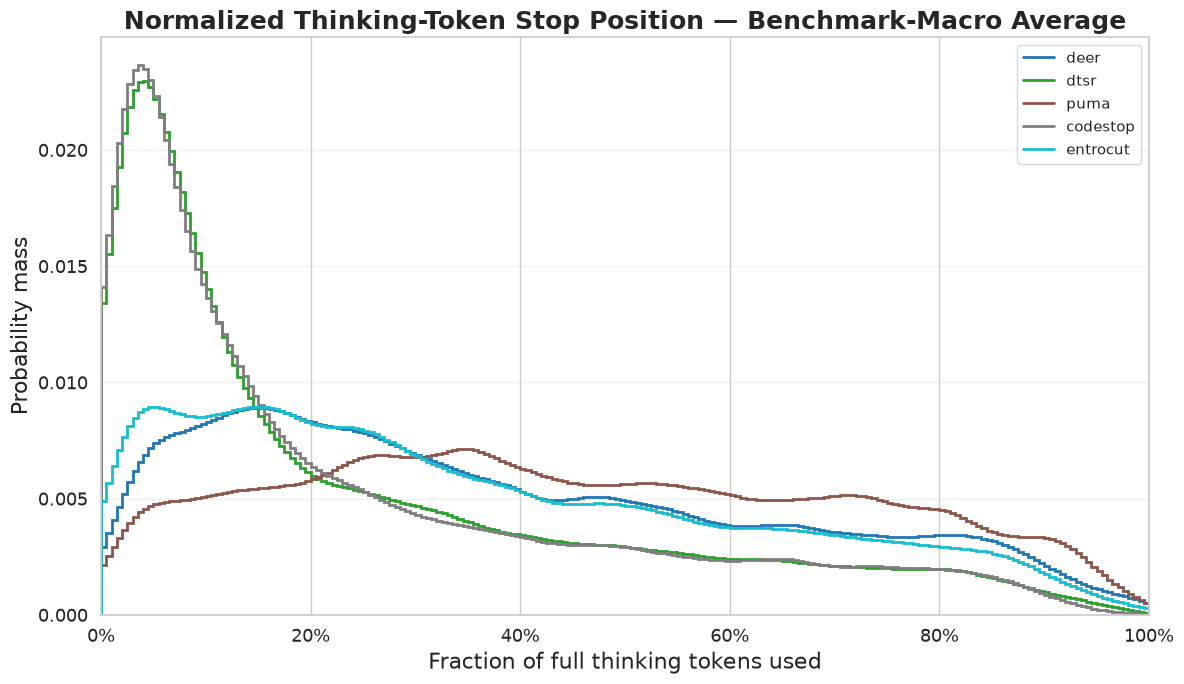

(<Figure size 1200x700 with 1 Axes>,
 <Axes: title={'center': 'Normalized Thinking-Token Stop Position — Benchmark-Macro Average'}, xlabel='Fraction of full thinking tokens used', ylabel='Probability mass'>)

In [17]:
draw_normalized_exit_position_pdf(
      df_collapsed,
      methods=["deer", "dtsr", "puma", "codestop", "entrocut"],
      bins=200,
      smoothing="gaussian",
    smooth_sigma=5,     
  )

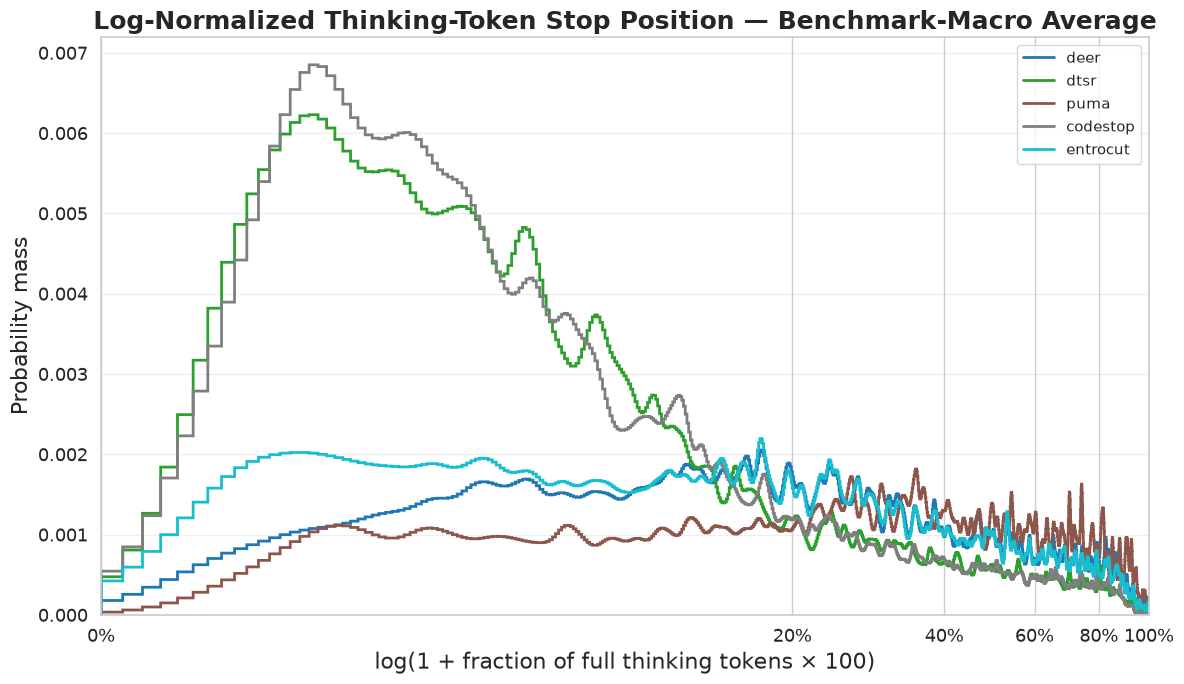

(<Figure size 1200x700 with 1 Axes>,
 <Axes: title={'center': 'Log-Normalized Thinking-Token Stop Position — Benchmark-Macro Average'}, xlabel='log(1 + fraction of full thinking tokens × 100)', ylabel='Probability mass'>)

In [18]:
draw_log_normalized_exit_position_pdf(
      df_collapsed,
      methods=["deer", "dtsr", "puma", "codestop", "entrocut"],
            bins=1000,
            smoothing="gaussian",
                smooth_sigma=3,
  )

In [19]:
# raise SystemExit("Analysis complete. Exiting script.")

### Draw aggregate performance visualizations

Renders the summary bar charts, stacked token-cost breakdown, per-benchmark/model accuracy-versus-budget curves, and exit-position distributions. Token values are clipped to 32K only in a plotting copy; analytical values remain unchanged, and accuracy curves use the full question count as their denominator.


In [20]:
from evaluator.code_exec import extract_code_block


code_character_rows = []
for record in records:
    additional = record.get("additional_logs") or {}
    failure_reason = (
        record.get("failure_reason")
        or additional.get("failure_reason")
    )
    if (
        record.get("evaluator") != "code_exec"
        or failure_reason == "full_generation_reached_token_limit"
    ):
        continue

    dataset = record.get("dataloader") or record.get("benchmark")
    top_level_method = record.get("agent") or record.get("method")
    top_level_answer = record.get("output") or record.get("content") or ""

    for method_result in get_method_results(record):
        if not isinstance(method_result, dict):
            continue
        answer = method_result.get("final_answer")
        if not answer and method_result.get("method") == top_level_method:
            answer = top_level_answer
        code = extract_code_block(str(answer or ""))
        code_character_rows.append({
            "dataset": dataset,
            "code_characters": len(code),
        })

code_character_df = pd.DataFrame(code_character_rows)
if code_character_df.empty:
    display(pd.DataFrame(columns=[
        "dataset", "n_method_answers",
        "average_code_characters", "p95_code_characters",
    ]))
else:
    code_character_summary = (
        code_character_df.groupby("dataset", as_index=False)
        .agg(
            n_method_answers=("code_characters", "size"),
            average_code_characters=("code_characters", "mean"),
            p95_code_characters=(
                "code_characters", lambda values: values.quantile(0.95)
            ),
        )
        .sort_values("dataset")
        .reset_index(drop=True)
    )
    display(code_character_summary.round(2))


,dataset,n_method_answers,average_code_characters,p95_code_characters
0,livecodebench,63000,3655.42,11594.1


# Optimal token consumption

## Target-integrated token efficiency (TITE)

TITE averages oracle-relative efficiency over reasoning-gain targets
`0.001, ..., 1.000`, where no thinking is zero gain and the discrete oracle
is complete gain: $G=A_{oracle}-A_{NT}$ and
$a(q)=A_{NT}+qG$. For every recorded run, the oracle uses the cheapest correct
early-exit, finite-baseline, or full `replay_eval` result; when all are
incorrect, it pays the `replay_eval` cost and remains incorrect. Missed targets
contribute zero. **Weight-TITE** uses the same targets with the linear 2x
weight `w(g) = (2/3)(1 + g)`. Both metrics are N/A when the
oracle gain $A_{oracle}-A_{NT}$ is not greater than `0.001`. Because each
target efficiency is clipped to $[0,1]$, $0 \leq TITE_m \leq C_m \leq 1$,
where $C_m$ is target coverage. The oracle has TITE 1 and the no-thinking
baseline has TITE 0 whenever the oracle gain is applicable.

The report uses **completion + verifier-completion tokens** as its cost and
shows that mean cost directly in the table.


In [21]:
# Shared configuration for the TITE and hybrid reports
DATASET_GROUPS = {
    "math+qa": ["aime26", "gpqa_diamond", "gsm8k", "math500", "mmlu_pro_subset"],
    "code": ["humaneval", "livecodebench"],
    "hallucination": ["truthfulqa", "halueval"],
}

REPORT_METHOD_ORDER = [
    ORACLE_METHOD,
    ORACLE_REPLAY_METHOD,
    "statistical_early_stop",
    "entrocut",
    "deer",
    "dtsr",
    "codestop",
    "baseline_no_thinking",
    "dynasor",
    "answer-coverage",
    "puma",
    "terminator_hf",
    "thought_calibration",
]


def prepare_report_table(df_raw):
    """Use the same oracle-prepared table as cells 22 and 26."""
    return select_oracle_baseline(df_raw)


TITE_OPTIMAL_ORACLE_METHODS = [
    "codestop", "deer", "entrocut", "dtsr",
]


def build_tite_optimal_oracle(
    df_raw,
    token_col="total_cost_tokens_est",
    fallback_method=ORACLE_REPLAY_METHOD,
):
    """Build the cell-80 optimal oracle, then balance repeated questions."""
    required = {
        "benchmark", "model", "sample_id", "run_id",
        "method", "correct", token_col,
    }
    missing = required.difference(df_raw.columns)
    if missing:
        raise ValueError(f"Missing optimal-oracle columns: {sorted(missing)}")

    work = df_raw.copy()
    unit_cols = ["benchmark", "model", "sample_id", "run_id"]
    finite_baseline = work["method"].map(_baseline_budget).notna()
    candidate_mask = (
        work["method"].isin(TITE_OPTIMAL_ORACLE_METHODS)
        | work["method"].eq(fallback_method)
        | finite_baseline
    )
    candidates = work[
        candidate_mask
        & work["correct"].fillna(False).astype(bool)
        & work[token_col].notna()
    ].copy()
    fallback = (
        work[work["method"].eq(fallback_method)]
        .drop_duplicates(unit_cols, keep="first")
    )
    if fallback.empty:
        return fallback

    candidate_groups = {
        key: group
        for key, group in candidates.groupby(unit_cols, dropna=False)
    }
    selected_rows = []
    for _, fallback_row in fallback.iterrows():
        key = tuple(fallback_row[column] for column in unit_cols)
        correct_rows = candidate_groups.get(key)
        if correct_rows is not None and not correct_rows.empty:
            selected = correct_rows.loc[correct_rows[token_col].idxmin()].copy()
            selected_method = selected["method"]
        else:
            selected = fallback_row.copy()
            selected["correct"] = False
            selected_method = "fallback_unsolved"
        selected["selected_oracle_method"] = selected_method
        selected["oracle_bin"] = "optimal_oracle"
        selected["method"] = ORACLE_METHOD
        selected["model_family"] = ORACLE_METHOD
        selected_rows.append(selected)

    oracle_runs = pd.DataFrame(selected_rows)
    oracle_questions = _average_method_runs(oracle_runs)
    oracle_questions["oracle_bin"] = "optimal_oracle"
    oracle_questions["selected_oracle_method"] = "per-run minimum"
    return oracle_questions


def prepare_tite_report_table(df_raw):
    """Replace the legacy report oracle with the optimal TITE oracle."""
    ordinary = prepare_report_table(df_raw)
    ordinary = ordinary[~ordinary["method"].eq(ORACLE_METHOD)].copy()
    oracle = build_tite_optimal_oracle(df_raw)
    if oracle.empty:
        return ordinary.iloc[0:0].copy()
    scope_cols = ["benchmark", "model", "sample_id"]
    ordinary = ordinary.merge(
        oracle[scope_cols].drop_duplicates(),
        on=scope_cols,
        how="inner",
    )
    return pd.concat([ordinary, oracle], ignore_index=True, sort=False)


def oracle_selection_summary(report_df):
    selected = report_df[report_df["method"].eq(ORACLE_METHOD)]
    if selected.empty:
        return pd.DataFrame()
    accuracy_col = "run_accuracy" if "run_accuracy" in selected else "correct"
    return (
        selected.groupby("oracle_bin", dropna=False)
        .agg(
            questions=("sample_id", "size"),
            accuracy=(accuracy_col, "mean"),
            mean_tokens=("total_cost_tokens_est", "mean"),
            std_tokens=("total_cost_tokens_est", "std"),
            p95_tokens=("total_cost_tokens_est", token_p95),
        )
        .sort_index()
        .pipe(
            add_mean_std_display, "mean_tokens", "std_tokens",
            "tokens (mean ± std)",
        )
    )


In [22]:
def _build_token_requirement_table(
    subset,
    *,
    token_col,
    accuracy_col,
    oracle_method=ORACLE_METHOD,
    targets,
):
    """Return per-method token requirements for explicit accuracy targets."""
    required = {"method", "sample_id", token_col, accuracy_col}
    missing = required.difference(subset.columns)
    if missing:
        raise ValueError(f"Missing columns: {sorted(missing)}")
    methods = sorted(subset["method"].dropna().unique())
    if oracle_method not in methods:
        raise ValueError(f"Missing oracle method {oracle_method!r}")

    n_questions = subset["sample_id"].nunique()
    curves = {}
    for method in methods:
        per_question = (
            subset[subset["method"].eq(method)]
            .groupby("sample_id", as_index=False)
            .agg(
                success_probability=(accuracy_col, "mean"),
                tokens=(token_col, "mean"),
            )
        )
        per_question["success_probability"] = (
            per_question["success_probability"].fillna(0).clip(0, 1)
        )
        successful = per_question[
            per_question["success_probability"].gt(0)
            & np.isfinite(per_question["tokens"])
            & per_question["tokens"].ge(0)
        ].sort_values("tokens")
        curves[method] = (
            successful["tokens"].to_numpy(float),
            np.cumsum(
                successful["success_probability"].to_numpy(float) / n_questions
            ),
        )

    oracle_curve = curves[oracle_method][1]
    oracle_accuracy = float(oracle_curve[-1]) if len(oracle_curve) else 0.0
    target_values = np.asarray(targets, dtype=float)
    common_targets = np.sort(np.unique(target_values[
        np.isfinite(target_values)
        & (target_values > 0)
        & (target_values <= oracle_accuracy + 1e-12)
    ]))
    requirements = pd.DataFrame(
        index=methods, columns=common_targets, dtype=float
    )
    for method, (token_values, cumulative_accuracy) in curves.items():
        indices = np.searchsorted(
            cumulative_accuracy, common_targets, side="left"
        )
        requirements.loc[method] = [
            token_values[index] if index < len(token_values) else np.inf
            for index in indices
        ]
    return requirements


def calculate_target_efficiency(
    subset,
    token_col="total_cost_tokens_est",
    targets=None,
    accuracy_col=None,
    oracle_method=ORACLE_METHOD,
):
    """Return gain-based TITE and Weight-TITE for every method."""
    accuracy_col = accuracy_col or (
        "run_accuracy" if "run_accuracy" in subset else "correct"
    )
    gain_targets = TITE_GAIN_TARGETS if targets is None else targets
    summary, detail = calculate_tite(
        subset,
        token_col=token_col,
        accuracy_col=accuracy_col,
        oracle_method=oracle_method,
        gain_targets=gain_targets,
        return_details=True,
    )
    result = summary.merge(
        calculate_weight_tite(detail), on="method", how="left"
    )
    return result.sort_values(
        ["TITE", "target_coverage", "accuracy"],
        ascending=False,
        na_position="last",
    ).reset_index(drop=True)

In [23]:
# TITE: efficiency over positive fractions of the reasoning gain.
TITE_EPSILON = 0.001
TITE_GAIN_TARGETS = np.arange(1, 1001, dtype=float) / 1000
TITE_NO_THINKING_METHOD = "baseline_no_thinking"


def _method_accuracy_on_scope(subset, method, accuracy_col, n_questions):
    rows = subset[subset["method"].eq(method)]
    if rows.empty or n_questions <= 0:
        return np.nan
    per_question = (
        rows.groupby("sample_id")[accuracy_col]
        .mean().fillna(0).clip(0, 1)
    )
    return float(per_question.sum() / n_questions)


def calculate_tite(
    subset,
    token_col="total_cost_tokens_est",
    accuracy_col=None,
    oracle_method=ORACLE_METHOD,
    no_thinking_method=TITE_NO_THINKING_METHOD,
    gain_targets=TITE_GAIN_TARGETS,
    epsilon=TITE_EPSILON,
    return_details=False,
):
    """Calculate TITE; unreached positive reasoning-gain targets score zero."""
    accuracy_col = accuracy_col or (
        "run_accuracy" if "run_accuracy" in subset else "correct"
    )
    methods = sorted(subset["method"].dropna().unique())
    n_questions = subset["sample_id"].nunique()
    accuracies = {
        method: _method_accuracy_on_scope(
            subset, method, accuracy_col, n_questions
        )
        for method in methods
    }
    missing_anchors = [
        method for method in [no_thinking_method, oracle_method]
        if method not in methods
    ]
    if missing_anchors:
        summary = pd.DataFrame({
            "method": methods,
            "TITE": np.nan,
            "accuracy": [accuracies[method] for method in methods],
            "efficiency_when_reached": np.nan,
            "geometric_token_multiplier": np.nan,
            "target_coverage": np.nan,
            "targets_reached": 0,
            "n_targets": 0,
            "first_target": np.nan,
            "last_target": np.nan,
            "status": "Missing TITE anchor",
            "gain_coverage": np.nan,
            "excess_accuracy": np.nan,
            "no_thinking_accuracy": np.nan,
            "oracle_accuracy": np.nan,
            "reasoning_gain": np.nan,
            "rg_applicable": False,
        })
        detail = pd.DataFrame()
        return (summary, detail) if return_details else summary

    no_thinking_accuracy = accuracies[no_thinking_method]
    oracle_accuracy = accuracies[oracle_method]
    reasoning_gain = oracle_accuracy - no_thinking_accuracy
    applicable = bool(np.isfinite(reasoning_gain) and reasoning_gain > epsilon)

    summary_rows = []
    detail_rows = []
    if applicable:
        gain_targets = np.asarray(gain_targets, dtype=float)
        gain_targets = np.sort(np.unique(gain_targets[
            np.isfinite(gain_targets)
            & (gain_targets > 0)
            & (gain_targets <= 1)
        ]))
        accuracy_targets = no_thinking_accuracy + gain_targets * reasoning_gain
        requirements = _build_token_requirement_table(
            subset,
            token_col=token_col,
            accuracy_col=accuracy_col,
            oracle_method=oracle_method,
            targets=accuracy_targets,
        )
        oracle_tokens = requirements.loc[oracle_method].to_numpy(float)
        if len(requirements.columns) != len(gain_targets):
            raise ValueError(
                "The optimal oracle does not reach its own accuracy anchor"
            )

        for method in methods:
            method_tokens = requirements.loc[method].to_numpy(float)
            reached = np.isfinite(method_tokens) & np.isfinite(oracle_tokens)
            target_efficiency = np.zeros(len(gain_targets), dtype=float)
            target_efficiency[reached] = np.minimum(
                oracle_tokens[reached]
                / np.maximum(method_tokens[reached], 1e-12),
                1.0,
            )
            gain_coverage = float(np.clip(
                (accuracies[method] - no_thinking_accuracy) / reasoning_gain,
                0, 1,
            ))
            target_coverage = float(reached.mean()) if len(reached) else 0.0
            multiplier = (
                float(np.exp(np.mean(np.log(
                    np.maximum(method_tokens[reached], 1e-12)
                    / np.maximum(oracle_tokens[reached], 1e-12)
                ))))
                if reached.any()
                else np.nan
            )
            summary_rows.append({
                "method": method,
                "TITE": float(target_efficiency.mean()),
                "accuracy": accuracies[method],
                "efficiency_when_reached": (
                    float(target_efficiency[reached].mean())
                    if reached.any() else np.nan
                ),
                "geometric_token_multiplier": multiplier,
                "target_coverage": target_coverage,
                "targets_reached": int(reached.sum()),
                "n_targets": len(gain_targets),
                "first_target": accuracy_targets.min(),
                "last_target": accuracy_targets.max(),
                "status": (
                    "Full gain coverage" if target_coverage == 1
                    else "Partial gain coverage" if target_coverage > 0
                    else "No gain target reached"
                ),
                "gain_coverage": gain_coverage,
                "excess_accuracy": float(max(
                    0, accuracies[method] - oracle_accuracy
                )),
                "no_thinking_accuracy": no_thinking_accuracy,
                "oracle_accuracy": oracle_accuracy,
                "reasoning_gain": reasoning_gain,
                "rg_applicable": True,
            })
            detail_rows.extend({
                "method": method,
                "gain_target": gain_target,
                "accuracy_target": accuracy_target,
                "oracle_tokens": oracle_cost,
                "method_tokens": method_cost if is_reached else np.nan,
                "target_efficiency": efficiency,
                "reached": bool(is_reached),
            } for gain_target, accuracy_target, oracle_cost, method_cost,
                efficiency, is_reached in zip(
                    gain_targets, accuracy_targets, oracle_tokens, method_tokens,
                    target_efficiency, reached
                ))
    else:
        for method in methods:
            summary_rows.append({
                "method": method, "TITE": np.nan,
                "accuracy": accuracies[method],
                "efficiency_when_reached": np.nan,
                "geometric_token_multiplier": np.nan,
                "target_coverage": np.nan,
                "targets_reached": 0, "n_targets": 0,
                "first_target": np.nan, "last_target": np.nan,
                "status": "Reasoning gain not applicable",
                "gain_coverage": np.nan, "excess_accuracy": np.nan,
                "no_thinking_accuracy": no_thinking_accuracy,
                "oracle_accuracy": oracle_accuracy,
                "reasoning_gain": reasoning_gain, "rg_applicable": False,
            })

    summary = pd.DataFrame(summary_rows)
    detail = pd.DataFrame(detail_rows)
    return (summary, detail) if return_details else summary


In [24]:
# Weight-TITE: TITE with the normalized linear 2x gain-target weight.
def calculate_weight_tite(gain_detail):
    """Weight gain targets by w(g) = (2/3)(1 + g)."""
    if gain_detail.empty:
        return pd.DataFrame(columns=["method", "Weight-TITE"])
    weighted = gain_detail.copy()
    weighted["linear_2x_weight"] = (2 / 3) * (
        1 + weighted["gain_target"]
    )
    weighted["weighted_efficiency"] = (
        weighted["target_efficiency"] * weighted["linear_2x_weight"]
    )
    result = (
        weighted.groupby("method", as_index=False)
        .agg(
            weighted_efficiency=("weighted_efficiency", "sum"),
            total_weight=("linear_2x_weight", "sum"),
        )
    )
    result["Weight-TITE"] = (
        result["weighted_efficiency"] / result["total_weight"]
    )
    result = result[["method", "Weight-TITE"]]
    return result


In [25]:
def format_target_efficiency_table(aggregate, efficiency, method_order=None):
    if "method" not in aggregate.columns:
        raise ValueError("aggregate must contain a 'method' column")
    efficiency = efficiency.copy()
    if "method" not in efficiency.columns:
        if not efficiency.empty:
            raise ValueError("efficiency must contain a 'method' column")
        efficiency = pd.DataFrame({
            "method": pd.Series(dtype=object),
        })
    metric_columns = [
        "TITE", "Weight-TITE",
        "geometric_token_multiplier", "target_coverage",
    ]
    for column in metric_columns:
        if column not in efficiency.columns:
            efficiency[column] = np.nan
        else:
            efficiency[column] = pd.to_numeric(
                efficiency[column], errors="coerce"
            )
    table = aggregate.merge(
        efficiency[["method", *metric_columns]],
        on="method", how="left",
    )
    if method_order:
        order = {method: i for i, method in enumerate(method_order)}
        table["_order"] = table["method"].map(order).fillna(len(order))
        table = table.sort_values(["_order", "method"]).drop(columns="_order")

    result = table[[
        "method", "acc", "mean_total", "std_total", "p95_total",
        "compl_pct", "reduc_pct", "token_pct_vs_replay", "opt_cur",
        "TITE", "Weight-TITE",
        "geometric_token_multiplier", "target_coverage",
    ]].copy()
    result = result.rename(columns={
        "p95_total": "p95_tok (complete+verify)",
        "compl_pct": "compl%",
        "reduc_pct": "reduc%",
        "token_pct_vs_replay": "token% vs replay_eval",
        "geometric_token_multiplier": "tok_x",
        "target_coverage": "target_cov%",
    })
    result["acc"] = result["acc"].round(3)
    result = add_mean_std_display(
        result, "mean_total", "std_total",
        "tok (complete+verify; mean ± std)",
    )
    result = result.drop(columns=["mean_total", "std_total"])
    result["p95_tok (complete+verify)"] = result[
        "p95_tok (complete+verify)"
    ].round(1)
    for column in ["compl%", "reduc%"]:
        result[column] = result[column].round(1)
    result["opt_cur"] = result["opt_cur"].round(3)
    for column in ["TITE", "Weight-TITE"]:
        result[column] = result[column].round(3)
    result["tok_x"] = result["tok_x"].map(
        lambda value: round(value, 3) if pd.notna(value) and np.isfinite(value) else "inf"
    )
    result["target_cov%"] = (result["target_cov%"] * 100).round(1)
    return result.set_index("method")


In [26]:
def build_cross_dataset_tables(
    report_df,
    group_name,
    datasets,
    token_col="total_cost_tokens_est",
):
    results = []
    for model in sorted(report_df["model"].dropna().unique()):
        subset = report_df[
            report_df["model"].eq(model)
            & report_df["benchmark"].isin(datasets)
        ].copy()
        if subset.empty:
            continue
        accuracy_col = "correct"
        keys = ["benchmark", "model", "sample_id"]
        oracle_cost = (
            subset[
                subset["method"].eq(ORACLE_METHOD)
                & subset[accuracy_col].ge(0.5)
                & subset[token_col].notna()
            ][keys + [token_col]]
            .rename(columns={token_col: "optimal_tokens"})
        )
        subset = subset.merge(oracle_cost, on=keys, how="left")
        denominator = subset[token_col].replace(0, np.nan)
        subset["per_sample_opt_cur"] = subset["optimal_tokens"] / denominator
        subset["per_sample_compl_pct"] = (
            subset["completion_tokens"] / denominator * 100
        )
        aggregate = (
            subset.groupby(["method", "benchmark"], as_index=False)
            .agg(
                acc=(accuracy_col, "mean"),
                compl_pct=("per_sample_compl_pct", "mean"),
                mean_total=(token_col, "mean"),
                std_total=(token_col, "std"),
                p95_total=(token_col, token_p95),
                mean_saving=("token_saving_vs_full", "mean"),
                opt_cur=("per_sample_opt_cur", "mean"),
            )
        )
        aggregate["reduc_pct"] = aggregate["mean_saving"] * 100
        replay_mean_by_benchmark = (
            aggregate[aggregate["method"].eq(ORACLE_REPLAY_METHOD)]
            .set_index("benchmark")["mean_total"]
            .replace(0, np.nan)
        )
        aggregate["token_pct_vs_replay"] = (
            aggregate["mean_total"]
            / aggregate["benchmark"].map(replay_mean_by_benchmark)
            * 100
        )

        print(f"\n{'=' * 72}\n  MODEL: {model} | GROUP: {group_name}\n{'=' * 72}")
        for dataset in datasets:
            dataset_subset = subset[subset["benchmark"].eq(dataset)]
            if dataset_subset.empty:
                continue
            efficiency = calculate_target_efficiency(
                dataset_subset,
                token_col=token_col,
                accuracy_col=accuracy_col,
                oracle_method=ORACLE_METHOD,
            )
            efficiency["model"] = model
            efficiency["benchmark"] = dataset
            results.append(efficiency)
            table = format_target_efficiency_table(
                aggregate[aggregate["benchmark"].eq(dataset)],
                efficiency,
                REPORT_METHOD_ORDER,
            )
            print(f"\n--- {dataset} ---")
            print(table.to_markdown())
    return pd.concat(results, ignore_index=True) if results else pd.DataFrame()


In [27]:
# Prepare the report representation once and reuse it everywhere below.
report_df = prepare_report_table(df)
tite_report_df = prepare_tite_report_table(df)

print("\n" + "=" * 72 + "\n  ORACLE BIN SELECTION\n" + "=" * 72)
print(oracle_selection_summary(report_df).round(3).to_markdown())

efficiency_frames = [
    build_cross_dataset_tables(tite_report_df, group_name, datasets)
    for group_name, datasets in DATASET_GROUPS.items()
]
efficiency_results = pd.concat(
    [frame for frame in efficiency_frames if not frame.empty],
    ignore_index=True,
) if any(not frame.empty for frame in efficiency_frames) else pd.DataFrame()



  ORACLE BIN SELECTION
| oracle_bin           |   questions |   accuracy |   mean_tokens |   std_tokens |   p95_tokens | tokens (mean ± std)   |
|:---------------------|------------:|-----------:|--------------:|-------------:|-------------:|:----------------------|
| +inf (replay_eval)   |       11279 |      0.017 |      8358.82  |    11270.4   |     34050    | 8358.8 ± 11270.4      |
| baseline_1.5K        |         765 |      1     |      2284.07  |      907.011 |      4099    | 2284.1 ± 907.0        |
| baseline_12K         |         315 |      0.998 |     12728.5   |     1870.78  |     15360    | 12728.5 ± 1870.8      |
| baseline_16K         |         176 |      0.994 |     16919.7   |     2040.2   |     19196.2  | 16919.7 ± 2040.2      |
| baseline_1K          |        1899 |      1     |      1508.96  |      717.683 |      3072    | 1509.0 ± 717.7        |
| baseline_24K         |         180 |      0.839 |     20037     |     7889.73  |     26803.6  | 20037.0 ± 7889.7      |


In [28]:
# Macro averages across the configured benchmark families.
def build_group_average_tables(
    report_df,
    efficiency_results,
    dataset_groups=DATASET_GROUPS,
    token_col="total_cost_tokens_est",
):
    tables = {}
    for group_name, datasets in dataset_groups.items():
        for model in sorted(report_df["model"].dropna().unique()):
            subset = report_df[
                report_df["model"].eq(model)
                & report_df["benchmark"].isin(datasets)
            ].copy()
            if subset.empty:
                continue

            keys = ["benchmark", "model", "sample_id"]
            oracle_cost = (
                subset[
                    subset["method"].eq(ORACLE_METHOD)
                    & subset["correct"].ge(0.5)
                    & subset[token_col].notna()
                ][keys + [token_col]]
                .rename(columns={token_col: "optimal_tokens"})
            )
            subset = subset.merge(oracle_cost, on=keys, how="left")
            denominator = subset[token_col].replace(0, np.nan)
            subset["per_sample_opt_cur"] = (
                subset["optimal_tokens"] / denominator
            )
            subset["per_sample_compl_pct"] = (
                subset["completion_tokens"] / denominator * 100
            )
            aggregate = (
                subset.groupby(["method", "benchmark"], as_index=False)
                .agg(
                    acc=("correct", "mean"),
                    compl_pct=("per_sample_compl_pct", "mean"),
                    mean_total=(token_col, "mean"),
                    std_total=(token_col, "std"),
                    p95_total=(token_col, token_p95),
                    mean_saving=("token_saving_vs_full", "mean"),
                    opt_cur=("per_sample_opt_cur", "mean"),
                )
            )
            aggregate["reduc_pct"] = aggregate["mean_saving"] * 100
            present_datasets = sorted(subset["benchmark"].unique())
            method_counts = aggregate.groupby("method")["benchmark"].nunique()
            common_methods = method_counts[
                method_counts.eq(len(present_datasets))
            ].index
            macro_aggregate = (
                aggregate[aggregate["method"].isin(common_methods)]
                .groupby("method", as_index=False)
                .mean(numeric_only=True)
            )
            replay_mean = macro_aggregate.loc[
                macro_aggregate["method"].eq(ORACLE_REPLAY_METHOD),
                "mean_total",
            ]
            replay_mean = replay_mean.iloc[0] if not replay_mean.empty else np.nan
            macro_aggregate["token_pct_vs_replay"] = (
                macro_aggregate["mean_total"] / replay_mean * 100
                if pd.notna(replay_mean) and replay_mean > 0
                else np.nan
            )
            macro_efficiency = (
                efficiency_results[
                    efficiency_results["model"].eq(model)
                    & efficiency_results["benchmark"].isin(present_datasets)
                    & efficiency_results["method"].isin(common_methods)
                ]
                .groupby("method", as_index=False)
                .mean(numeric_only=True)
            )
            table = format_target_efficiency_table(
                macro_aggregate, macro_efficiency, REPORT_METHOD_ORDER
            )
            tables[(model, group_name)] = table
            print(
                f"\n{'=' * 72}\n"
                f"  MODEL: {model} | AVERAGE: {group_name}\n"
                f"{'=' * 72}"
            )
            print(table.to_markdown())
    return tables


group_average_tables = build_group_average_tables(
    tite_report_df, efficiency_results
)



  MODEL: gemma4e4 | AVERAGE: math+qa
| method                 |   acc |   p95_tok (complete+verify) |   compl% |   reduc% |   token% vs replay_eval |   opt_cur |   TITE |   Weight-TITE |   tok_x |   target_cov% | tok (complete+verify; mean ± std)   |
|:-----------------------|------:|----------------------------:|---------:|---------:|------------------------:|----------:|-------:|--------------:|--------:|--------------:|:------------------------------------|
| oracle                 | 0.703 |                      4840.6 |    100   |     23.5 |                 79.0944 |     1     |  1     |         0.999 |   1     |         100   | 2146.2 ± 1631.3                     |
| replay_eval            | 0.604 |                      5859   |    100   |      0   |                100      |     0.678 |  0.373 |         0.337 |   2.003 |          69.6 | 2713.5 ± 1760.4                     |
| statistical_early_stop | 0.59  |                      5859.4 |    100   |      0   |                 99.

The generated tables are the report source of truth. `oracle` combines
all finite baseline bins with the uncapped `replay_eval` fallback,
rather than reporting either naïve path as a separate method. Hard-coded
numerical conclusions were removed so rerunning the notebook cannot leave
stale prose behind.


In [29]:
def build_target_requirement_detail(
    subset,
    selected_method,
    token_col="total_cost_tokens_est",
    accuracy_col=None,
    targets=None,
    oracle_method=ORACLE_METHOD,
    baseline_method=TITE_NO_THINKING_METHOD,
):
    """Return gain-target costs using the same engine as the TITE table."""
    accuracy_col = accuracy_col or (
        "run_accuracy" if "run_accuracy" in subset else "correct"
    )
    gain_targets = TITE_GAIN_TARGETS if targets is None else targets
    _, all_detail = calculate_tite(
        subset,
        token_col=token_col,
        accuracy_col=accuracy_col,
        oracle_method=oracle_method,
        gain_targets=gain_targets,
        return_details=True,
    )
    if all_detail.empty:
        raise ValueError("TITE is not applicable because its anchor gain is missing")
    if selected_method not in set(all_detail["method"]):
        raise ValueError(
            f"Method {selected_method!r} is not present; "
            f"available methods: {sorted(all_detail['method'].unique())}"
        )

    detail = (
        all_detail[all_detail["method"].eq(selected_method)]
        .sort_values("gain_target")
        .reset_index(drop=True)
        .copy()
    )
    accuracy_targets = detail["accuracy_target"].to_numpy(float)
    requirements = _build_token_requirement_table(
        subset,
        token_col=token_col,
        accuracy_col=accuracy_col,
        oracle_method=oracle_method,
        targets=accuracy_targets,
    )
    baseline_tokens = (
        requirements.loc[baseline_method].to_numpy(float)
        if baseline_method in requirements.index
        else np.full(len(detail), np.nan)
    )
    method_tokens = detail["method_tokens"].to_numpy(float)
    oracle_tokens = detail["oracle_tokens"].to_numpy(float)
    reached = detail["reached"].to_numpy(bool)

    detail["target_index"] = np.arange(1, len(detail) + 1)
    detail["target_accuracy"] = detail["accuracy_target"]
    detail["expected_correct_answers"] = (
        detail["target_accuracy"] * subset["sample_id"].nunique()
    )
    detail["baseline_tokens"] = np.where(
        np.isfinite(baseline_tokens), baseline_tokens, np.nan
    )
    detail["extra_tokens"] = np.where(
        reached, method_tokens - oracle_tokens, np.nan
    )
    detail["token_multiplier"] = np.where(
        reached,
        method_tokens / np.maximum(oracle_tokens, 1e-12),
        np.nan,
    )

    efficiency = calculate_target_efficiency(
        subset,
        token_col=token_col,
        targets=gain_targets,
        accuracy_col=accuracy_col,
        oracle_method=oracle_method,
    ).set_index("method").loc[selected_method]
    summary = {
        "method": selected_method,
        "TITE": efficiency["TITE"],
        "baseline_method": baseline_method,
        "no_thinking_accuracy": efficiency["no_thinking_accuracy"],
        "oracle_accuracy": efficiency["oracle_accuracy"],
        "geometric_token_multiplier": efficiency["geometric_token_multiplier"],
        "target_coverage": efficiency["target_coverage"],
        "targets_reached": int(efficiency["targets_reached"]),
        "n_targets": int(efficiency["n_targets"]),
        "first_target": efficiency["first_target"],
        "last_target": efficiency["last_target"],
    }
    return detail, summary

In [30]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter


def plot_target_requirement_gap(
    detail,
    summary,
    benchmark=None,
    model=None,
    annotate_target=None,
):
    """
    Plot oracle and selected-method token requirements against accuracy.

    The first plot focuses on the accuracy interval from the no-thinking
    baseline to the oracle. The second plot shows the same curves from zero
    accuracy and marks the no-thinking accuracy with a red vertical line.

    ``annotate_target`` is an accuracy value between 0 and 1.
    """
    method = summary["method"]
    reached = detail["reached"].to_numpy(dtype=bool)
    target_accuracy = detail["target_accuracy"].to_numpy(dtype=float)
    oracle_tokens = detail["oracle_tokens"].to_numpy(dtype=float)
    method_tokens = detail["method_tokens"].to_numpy(dtype=float)
    no_thinking_accuracy = float(summary["no_thinking_accuracy"])
    oracle_accuracy = float(summary["oracle_accuracy"])

    reached_rows = detail[detail["reached"]]
    selected_row = None
    if not reached_rows.empty:
        if annotate_target is None:
            selected_row = reached_rows.iloc[len(reached_rows) // 2]
        else:
            selected_row = reached_rows.iloc[
                (reached_rows["target_accuracy"] - annotate_target)
                .abs()
                .argmin()
            ]

    summary_text = (
        f"TITE = {summary['TITE']:.3f}\n"
        f"Token multiplier = "
        + (
            f"{summary['geometric_token_multiplier']:.2f}×"
            if pd.notna(summary["geometric_token_multiplier"])
            else "N/A"
        )
        + "\n"
        f"Target coverage = {summary['target_coverage']:.1%}"
    )

    def draw_plot(x_min, mark_no_thinking=False, annotate=False):
        fig, ax = plt.subplots(figsize=(11, 6))

        ax.plot(
            target_accuracy,
            oracle_tokens,
            marker="o",
            markersize=2.5,
            linewidth=2,
            label="Oracle token requirement",
        )
        ax.plot(
            target_accuracy,
            method_tokens,
            marker="o",
            markersize=2.5,
            linewidth=2,
            label=f"Actual requirement: {method}",
        )
        ax.fill_between(
            target_accuracy,
            oracle_tokens,
            method_tokens,
            where=reached,
            alpha=0.2,
            interpolate=True,
            label="Extra tokens above oracle",
        )

        if reached.any() and not reached.all():
            last_reached_accuracy = detail.loc[
                detail["reached"], "target_accuracy"
            ].max()
            ax.axvline(
                last_reached_accuracy,
                linestyle="--",
                linewidth=1,
            )
            ax.text(
                last_reached_accuracy,
                ax.get_ylim()[1] * 0.96,
                "Last reached accuracy",
                ha="right",
                va="top",
                fontsize=11,
            )

        if mark_no_thinking:
            ax.axvline(
                no_thinking_accuracy,
                color="red",
                linestyle="--",
                linewidth=2,
                label=f"No-thinking accuracy: {no_thinking_accuracy:.1%}",
            )

        if annotate and selected_row is not None:
            x = selected_row["target_accuracy"]
            optimal = selected_row["oracle_tokens"]
            actual = selected_row["method_tokens"]
            multiplier = selected_row["token_multiplier"]
            efficiency = selected_row["target_efficiency"]

            ax.vlines(
                x,
                optimal,
                actual,
                linestyle=":",
                linewidth=2,
            )
            annotation = (
                f"Accuracy: {x:.1%}\n"
                f"Oracle: {optimal:,.0f} tokens\n"
                f"Actual: {actual:,.0f} tokens\n"
                f"Efficiency: {efficiency:.3f}\n"
                f"Token multiplier: {multiplier:.2f}×"
            )
            ax.annotate(
                annotation,
                xy=(x, actual),
                xytext=(20, 20),
                textcoords="offset points",
                arrowprops={"arrowstyle": "->"},
                fontsize=11,
                bbox={"boxstyle": "round", "alpha": 0.85},
            )

        title_parts = [
            f"Oracle versus actual token requirement: {method}",
        ]
        if benchmark is not None:
            title_parts.append(str(benchmark))
        if model is not None:
            title_parts.append(str(model))

        ax.set_title(
            " | ".join(title_parts), fontsize=18, fontweight="bold"
        )
        ax.set_xlabel("Target accuracy", fontsize=14)
        ax.set_ylabel("Tokens required to reach target", fontsize=14)
        ax.set_xlim(x_min, oracle_accuracy)
        ax.xaxis.set_major_formatter(PercentFormatter(xmax=1.0))
        ax.tick_params(axis="both", labelsize=12)
        ax.grid(alpha=0.25)
        ax.legend(fontsize=11)
        ax.text(
            0.99,
            0.02,
            summary_text,
            transform=ax.transAxes,
            ha="right",
            va="bottom",
            fontsize=11,
            bbox={"boxstyle": "round", "alpha": 0.85},
        )
        plt.tight_layout()
        plt.show()

    draw_plot(
        no_thinking_accuracy,
        annotate=True,
    )
    draw_plot(
        0.0,
        mark_no_thinking=True,
    )


In [31]:
# model_name = "qwen35_9b"
# benchmark_name = "math500"
# method_name = "deer"

# plot_subset = tite_report_df[
#     (tite_report_df["model"] == model_name)
#     & (
#         tite_report_df["benchmark"]
#         == benchmark_name
#     )
# ].copy()

# detail, summary = build_target_requirement_detail(
#     subset=plot_subset,
#     selected_method=method_name,
#     token_col="total_cost_tokens_est",
#     accuracy_col="correct",
# )

# print(pd.Series(summary).to_string())

# plot_target_requirement_gap(
#     detail=detail,
#     summary=summary,
#     benchmark=benchmark_name,
#     model=model_name,
# )

# Entropy and surprisal analysis

# Continuation reasoning-error rate

This test uses the original method rows and their original token positions. It does **not** use the synthetic oracle, select an optimal baseline, or threshold an averaged accuracy. Exact `baseline_*` methods remain ordinary observed attempts. The only ordering rule is the simple token-position comparison described below.

For one JSONL reasoning trace, let $e=(r,m,t)$ denote a correct anchor answer from method $m$ at its recorded reasoning position $t$. For this anchor, define the set of valid later attempts

$$
L_e = \{j : r_j=r,\; m_j \ne m,\; t_j>t,\; j \text{ is valid}\}.
$$

Thus, an attempt is later only when its original token position is strictly larger than the anchor position. No oracle bin is constructed. The uncapped full answer is also included as a later attempt when its original `full_num_token` is available and the full generation did not exceed its token limit. `replay_eval` is excluded from the method pool because that same outcome is represented once as `full_answer`.

Let $c_j=1$ when later attempt $j$ is correct and $c_j=0$ otherwise. For every correct anchor that has at least one later attempt, its within-trace continuation error is

$$
q_e = 1 - \frac{1}{|L_e|}\sum_{j \in L_e} c_j
= \frac{1}{|L_e|}\sum_{j \in L_e}(1-c_j).
$$

For example, if a correct anchor occurs at 1,000 original tokens and the valid later attempts at 2,000, 4,000, and 8,000 tokens have correctness `[1, 0, 1]`, then

$$
q_e = 1 - \frac{1+0+1}{3} = \frac{1}{3}.
$$

Every correct anchor is kept as a separate observation. If a benchmark/model scope contains $E$ eligible anchors, the reported continuation reasoning-error rate is the simple mean

$$
\widehat q = \frac{1}{E}\sum_{e=1}^{E}q_e.
$$

This averages the error percentage inside each anchor trace first and then averages across anchors. It does not pool all later attempts into one denominator, and it does not group by anchor method. Repeated records remain separate anchor observations; question identity is used only to cluster the uncertainty estimate.

For the 95% interval, let $G$ be the number of question clusters, $E_g$ the anchors belonging to question cluster $g$, and $u_e=q_e-\widehat q$. The question-clustered variance estimate is

$$
\widehat{\operatorname{Var}}(\widehat q)
= \frac{G}{G-1}\frac{1}{E^2}
\sum_{g=1}^{G}\left(\sum_{e \in E_g}u_e\right)^2.
$$

The standard error is the square root of this variance. The confidence interval uses a Student-$t$ critical value with $G-1$ degrees of freedom and is clipped to $[0,1]$. Support is labeled **strong** when the upper bound is at most 2%, **moderate** when it is at most 5%, and **poor** otherwise.

Rows with `generation_failed=True` or a missing position are excluded individually; one failed method does not remove the other valid method responses from the same trace. There is no PUMA- or Dynasor-specific exclusion.

In [32]:
from scipy.stats import t as student_t


CONTINUATION_CONFIDENCE_LEVEL = 0.95


def continuation_support(ci_upper):
    if pd.isna(ci_upper):
        return "not estimable"
    if ci_upper <= 0.02:
        return "strong"
    if ci_upper <= 0.05:
        return "moderate"
    return "poor"


def _clustered_mean_interval(
    frame,
    value_col,
    cluster_col="question_cluster",
    confidence_level=CONTINUATION_CONFIDENCE_LEVEL,
):
    """CR1-style question-clustered interval for a flattened mean."""
    work = frame[[value_col, cluster_col]].dropna()
    n = len(work)
    clusters = work[cluster_col].nunique()
    if n == 0:
        return np.nan, np.nan, np.nan

    mean = float(work[value_col].mean())
    if clusters <= 1:
        return mean, 0.0, 1.0

    cluster_scores = (
        work.assign(_residual=work[value_col] - mean)
        .groupby(cluster_col)["_residual"]
        .sum()
    )
    variance = (
        clusters / (clusters - 1.0)
        * float(np.square(cluster_scores).sum())
        / (n**2)
    )
    standard_error = np.sqrt(max(variance, 0.0))
    alpha = 1.0 - confidence_level
    critical = student_t.ppf(1.0 - alpha / 2.0, df=clusters - 1)
    half_width = critical * standard_error
    return (
        mean,
        max(0.0, mean - half_width),
        min(1.0, mean + half_width),
    )


def build_trace_continuation_attempts(df_raw):
    """Build one row per correct method anchor and reasoning trace."""
    required = {
        "run_id",
        "sample_id",
        "benchmark",
        "model",
        "method",
        "position",
        "correct",
        "full_correct",
        "full_num_token",
        "full_limit_exceeded",
        "generation_failed",
    }
    missing = required.difference(df_raw.columns)
    if missing:
        raise ValueError(f"Missing columns: {sorted(missing)}")

    work = df_raw.copy()
    work["_position"] = pd.to_numeric(
        work["position"],
        errors="coerce",
    )
    work["_correct"] = work["correct"].fillna(False).astype(bool)
    work["_full_correct"] = (
        work["full_correct"].fillna(False).astype(bool)
    )
    work["_generation_failed"] = (
        work["generation_failed"].fillna(False).astype(bool)
    )
    work["_full_position"] = pd.to_numeric(
        work["full_num_token"],
        errors="coerce",
    )

    # Keep early-exit and baseline responses. Exclude only failed method
    # responses and replay_eval, which is represented once as full_answer.
    method_rows = work[
        ~work["method"].eq("replay_eval")
        & ~work["_generation_failed"]
        & work["_position"].notna()
    ].copy()

    method_rows = method_rows.drop_duplicates(
        ["run_id", "method"],
        keep="first", 
    )
    run_metadata = method_rows.groupby(
        "run_id",
        as_index=False,
    ).agg(
        sample_id=("sample_id", "first"),
        benchmark=("benchmark", "first"),
        model=("model", "first"),
        full_position=("_full_position", "first"),
        full_correct=("_full_correct", "first"),
        full_limit_exceeded=("full_limit_exceeded", "first"),
    )

    anchors = method_rows.loc[
        method_rows["_correct"],
        ["run_id", "method", "_position"],
    ].rename(columns={
        "method": "anchor_method",
        "_position": "anchor_position",
    })
    continuation_pool = method_rows[
        ["run_id", "method", "_position", "_correct"]
    ].rename(columns={
        "method": "later_method",
        "_position": "later_position",
        "_correct": "later_correct",
    })
    full_pool = run_metadata.loc[
        run_metadata["full_position"].notna()
        & ~run_metadata["full_limit_exceeded"].fillna(False).astype(bool),
        ["run_id", "full_position", "full_correct"],
    ].rename(columns={
        "full_position": "later_position",
        "full_correct": "later_correct",
    })
    full_pool["later_method"] = "full_answer"
    continuation_pool = pd.concat(
        [continuation_pool, full_pool],
        ignore_index=True,
        sort=False,
    )

    comparisons = anchors.merge(
        continuation_pool,
        on="run_id",
        how="inner",
    )
    comparisons = comparisons[
        comparisons["later_method"]
        .ne(comparisons["anchor_method"])
        & comparisons["later_position"]
        .gt(comparisons["anchor_position"])
    ].copy()

    trace_stats = comparisons.groupby(
        ["run_id", "anchor_method", "anchor_position"],
        as_index=False,
    ).agg(
        later_attempts=("later_correct", "size"),
        later_correct_attempts=("later_correct", "sum"),
        later_accuracy=("later_correct", "mean"),
    ).rename(columns={
        "anchor_method": "method",
        "anchor_position": "reasoning_budget",
    })
    trace_stats["q_trace"] = 1.0 - trace_stats["later_accuracy"]
    return trace_stats.merge(
        run_metadata[["run_id", "sample_id", "benchmark", "model"]],
        on="run_id",
        how="left",
        validate="many_to_one",
    )


def calculate_continuation_error_rates(
    df_raw,
    confidence_level=CONTINUATION_CONFIDENCE_LEVEL,
):
    # Every correct method result remains a separate exit t. No method-level
    # averaging or grouping is performed before the flattened summaries.
    trace_stats = build_trace_continuation_attempts(df_raw)
    if trace_stats.empty:
        return pd.DataFrame(), trace_stats

    trace_stats["question_cluster"] = (
        trace_stats["benchmark"].astype(str)
        + "::"
        + trace_stats["model"].astype(str)
        + "::"
        + trace_stats["sample_id"].astype(str)
    )

    scopes = []
    for (benchmark, model), group in trace_stats.groupby(
        ["benchmark", "model"],
        dropna=False,
    ):
        scopes.append(("stratum", benchmark, model, group))
    scopes.append(("overall", "ALL", "ALL", trace_stats))

    rows = []
    for scope, benchmark, model, scope_df in scopes:
        q_hat, ci_lower, ci_upper = _clustered_mean_interval(
            scope_df,
            value_col="q_trace",
            confidence_level=confidence_level,
        )
        rows.append({
            "scope": scope,
            "benchmark": benchmark,
            "model": model,
            "exit_t_observations": len(scope_df),
            "question_clusters": scope_df["question_cluster"].nunique(),
            "mean_reasoning_budget": float(scope_df["reasoning_budget"].mean()),
            "mean_later_attempts_per_trace": float(scope_df["later_attempts"].mean()),
            "later_correct": float(scope_df["later_accuracy"].mean()),
            "q_hat": q_hat,
            "ci_lower": ci_lower,
            "ci_upper": ci_upper,
            "support": continuation_support(ci_upper),
        })

    return pd.DataFrame(rows), trace_stats


def print_continuation_error_report(estimates):
    if estimates.empty:
        print("No eligible within-trace continuation attempts.")
        return

    display = estimates.copy()
    for column in ["later_correct", "q_hat", "ci_lower", "ci_upper"]:
        display[column] = (display[column] * 100.0).round(2)
    display["mean_reasoning_budget"] = display["mean_reasoning_budget"].round(1)
    display["mean_later_attempts_per_trace"] = (
        display["mean_later_attempts_per_trace"].round(2)
    )
    display = display.rename(columns={
        "later_correct": "later_correct_%",
        "q_hat": "q_hat_%",
        "ci_lower": "ci_lower_%",
        "ci_upper": "ci_upper_%",
    })

    print("FLATTENED CONTINUATION REASONING-ERROR RATE (%)")
    print(display.to_markdown(index=False))
    print(
        "\nEach correct method result is one exit t. Method identity is not "
        "used as an aggregation group. Support uses the question-clustered "
        "95% upper bound: strong <= 2%, moderate <= 5%, poor > 5%."
    )


continuation_error_stats, continuation_trace_stats = (
    calculate_continuation_error_rates(df)
)
print_continuation_error_report(continuation_error_stats)


FLATTENED CONTINUATION REASONING-ERROR RATE (%)
| scope   | benchmark       | model            |   exit_t_observations |   question_clusters |   mean_reasoning_budget |   mean_later_attempts_per_trace |   later_correct_% |   q_hat_% |   ci_lower_% |   ci_upper_% | support   |
|:--------|:----------------|:-----------------|----------------------:|--------------------:|------------------------:|--------------------------------:|------------------:|----------:|-------------:|-------------:|:----------|
| stratum | aime26          | gemma4e4         |                   102 |                  15 |                  2151.7 |                           16.01 |             90.37 |      9.63 |         0    |        19.65 | poor      |
| stratum | aime26          | gpt_oss_20b_high |                   500 |                  26 |                  7265.6 |                            9.16 |             99.17 |      0.83 |         0.22 |         1.43 | strong    |
| stratum | aime26          | qwen35

## Exit-agreement hybrid with a 16K hard stop

The hybrid checks the configured early-exit methods at ascending token stages.
At each stage, at least `ceil(AGREEMENT_T * N)` of the required methods must
have emitted valid early-exit signals before the stage ends. Answer values are
never compared. The latest exiting method available when the quorum forms
supplies the returned answer.

The stage cascade is checked only through `AGREEMENT_CUTOFF` (8K). If no exit
quorum fires, generation continues to the `baseline_16K` checkpoint and the
answer produced there is returned. This 16K hard-stop outcome is counted as a
normal early-exit result, not as a full-generation fallback.

For a quorum formed by methods `A`, `B`, and `C`, where `C` exits last, the
estimated cost is

$$
T_{\text{exit}} = t_C + a_C + v_A + v_B + v_C,
$$

where $t_C$ is the decision position, $a_C$ is the selected method's answer
completion cost, and $v_m$ is each monitor's verifier-completion cost through
that position. Per-attempt trace costs are summed for all active monitors, including
monitors that have not exited yet. At the hard stop, verifier costs are truncated
at the agreement cutoff and the recorded `baseline_16K` completion cost is used.


In [33]:
import json
import re
from collections import defaultdict

import pandas as pd


# ============================================================
# CONFIGURATION
# ============================================================

# Each key is also the minimum reasoning position for that stage.
# Therefore the 512 stage is the 0.5K gate: CodeStop and DEER may flag
# earlier, but the ensemble cannot accept their decision before token 512.
# Do not add baseline_500 merely as a timing gate; it would become another
# exit voter. Use the numeric stage key to express the minimum.
THRESHOLD_MIX = {
    # 512: [
    #     "codestop",
    #     "deer",
    # ],
    1_024: [
        "codestop",
        "deer",
        "entrocut",
        "dtsr",
    ],
    2_048: [
        "codestop",
        "deer",
        "entrocut",
        "dtsr",
    ],
    4_096: [
        "codestop",
        "deer",
        "entrocut",
        "dtsr",
    ],
}

# Exit-vote checks end at 8K; an unresolved run hard-stops at 16K.
AGREEMENT_CUTOFF = 8_192
AGREEMENT_T = 0.75
HARD_STOP_METHOD = "baseline_16K"


ANSWER_FIELDS = (
    "normalized_answer",
    "extracted_answer",
    "final_answer",
    "answer",
    "prediction",
    "pred",
    "response",
    "output",
    "generated_answer",
)


def first_not_none(*values):
    for value in values:
        if value is not None:
            return value

    return None


def extract_answer(method_result, record):
    """
    Extract the actual answer produced by a method.

    Extend ANSWER_FIELDS when the raw files use another field name.
    """

    method_logs = (
        method_result.get("logs")
        if isinstance(method_result.get("logs"), dict)
        else {}
    )

    containers = [
        method_result,
        method_logs,
    ]

    # Only use the top-level answer when this method was the
    # top-level agent that generated the record.
    top_level_method = (
        record.get("agent")
        or record.get("method")
    )

    if method_result.get("method") == top_level_method:
        containers.append(record)

        additional = record.get("additional_logs")

        if isinstance(additional, dict):
            containers.append(additional)

    for container in containers:
        for field in ANSWER_FIELDS:
            value = container.get(field)

            if value is not None:
                return value

    return None


def normalize_answer(answer, benchmark=None):
    """
    Conservative normalization for the selected output record.

    For code benchmarks, preserve code structure.
    For other benchmarks, normalize capitalization and whitespace.

    Replace this function with benchmark-specific canonicalization
    when one is available.
    """

    if answer is None:
        return None

    if isinstance(answer, (dict, list, tuple)):
        return json.dumps(
            answer,
            sort_keys=True,
            ensure_ascii=False,
        )

    text = str(answer).replace("\r\n", "\n").strip()

    if not text:
        return None

    # Remove an outer Markdown code fence only.
    if text.startswith("```") and text.endswith("```"):
        text = re.sub(
            r"^```[a-zA-Z0-9_+-]*\s*",
            "",
            text,
        )
        text = re.sub(
            r"\s*```$",
            "",
            text,
        ).strip()

    benchmark = str(benchmark or "").lower()

    is_code_benchmark = any(
        name in benchmark
        for name in (
            "humaneval",
            "livecodebench",
            "code",
        )
    )

    if is_code_benchmark:
        # Remove trailing spaces without collapsing code lines.
        return "\n".join(
            line.rstrip()
            for line in text.splitlines()
        ).strip()

    return re.sub(
        r"\s+",
        " ",
        text,
    ).strip().lower()


def build_exit_dataframe(records):
    """
    Build one row per benchmark/model/question/run/method.

    This differs from process_records() because it retains:
      - run_id
      - actual answer
      - normalized selected-output representation
    """

    rows = []

    for record_index, record in enumerate(records):
        additional = (
            record.get("additional_logs")
            if isinstance(
                record.get("additional_logs"),
                dict,
            )
            else {}
        )

        method_results = get_method_results(record)

        benchmark = record.get("benchmark")
        model = record.get("model")
        line_index = record.get(
            "line_index",
            record_index,
        )
        source_file = record.get(
            "source_file",
            "unknown_file",
        )

        sample_id = (
            f"{benchmark}_{line_index}"
        )

        # Distinguishes repeated runs of the same question.
        run_id = (
            f"{benchmark}|{model}|"
            f"{source_file}|{line_index}|{record_index}"
        )

        for method_result in method_results:
            if not isinstance(method_result, dict):
                continue

            values = process_method_result(record, method_result)
            logs = values["logs"]
            generation_failed = values["generation_failed"]
            thinking_tokens = float(values["thinking_tokens"])
            completion_tokens = float(values["completion_tokens"])
            verifier_prompt_tokens = float(
                values["verifier_prompt_tokens"]
            )
            verifier_completion_tokens = float(
                values["verifier_completion_tokens"]
            )
            correct = values["correct"]
            stopped_early = values["stopped_early"]
            raw_answer_tokens = method_result.get("answer_tokens")
            answer_tokens = float(
                values["answer_tokens"]
                if generation_failed or raw_answer_tokens is not None
                else max(completion_tokens - thinking_tokens, 0.0)
            )
            answer = (
                None
                if generation_failed
                else extract_answer(method_result, record)
            )

            verifier_total_tokens = (
                verifier_prompt_tokens
                + verifier_completion_tokens
            )

            rows.append({
                "benchmark": benchmark,
                "model": model,
                "sample_id": sample_id,
                "run_id": run_id,
                "method": method_result.get(
                    "method"
                ),

                "answer": answer,
                "answer_norm": normalize_answer(
                    answer,
                    benchmark,
                ),

                "correct": correct,
                "stopped_early": stopped_early,
                "generation_failed": (
                    generation_failed
                ),

                "thinking_tokens": (
                    thinking_tokens
                ),
                "completion_tokens": (
                    completion_tokens
                ),
                "answer_tokens": answer_tokens,

                "verifier_prompt_tokens": (
                    verifier_prompt_tokens
                ),
                "verifier_completion_tokens": (
                    verifier_completion_tokens
                ),
                "verifier_logs": logs,
                "verifier_total_tokens": (
                    verifier_total_tokens
                ),

                "total_cost_tokens_est": (
                    completion_tokens
                    + verifier_completion_tokens
                ),
            })

    result = pd.DataFrame(rows)

    if result.empty:
        return result

    unit_method = [
        "benchmark",
        "model",
        "sample_id",
        "run_id",
        "method",
    ]

    duplicate_count = int(
        result.duplicated(
            unit_method,
            keep=False,
        ).sum()
    )

    if duplicate_count:
        raise ValueError(
            f"Found {duplicate_count} duplicate "
            "run-method rows."
        )

    return result

In [34]:
def resolve_hard_stop_rows(
    exit_df,
    hard_stop_method=HARD_STOP_METHOD,
):
    """Return at most one exact hard-stop row per repeated run."""
    unit_cols = ["benchmark", "model", "sample_id", "run_id"]
    hard_stop = exit_df[
        exit_df["method"].eq(hard_stop_method)
    ].copy()
    hard_stop["selected_hard_stop_method"] = hard_stop_method

    duplicated = hard_stop.duplicated(unit_cols, keep=False)
    if duplicated.any():
        raise ValueError(
            "Hard-stop resolution produced multiple rows for the same "
            "repeated run."
        )
    return hard_stop


In [35]:
VERIFIER_ATTEMPT_LOG_KEYS = (
    "probe_attempts",
    "sufficiency_attempts",
    "puma_trials",
    "answer_coverage_attempts",
    "dynasor_attempts",
)


def verifier_completion_tokens_through(logs, stop_position, total_tokens, method_position):
    """Count cost through a stop; use the full total as a bound for incomplete traces."""
    import warnings
    # Serialized totals define the accounting convention for this run.
    # Legacy runs can log trial probes without charging verifier tokens.
    total_tokens = float(total_tokens or 0)
    if total_tokens == 0:
        return 0.0

    traces = []
    if isinstance(logs, dict):
        for key in VERIFIER_ATTEMPT_LOG_KEYS:
            attempts = logs.get(key, [])
            if not isinstance(attempts, list):
                continue
            for attempt in attempts:
                if not isinstance(attempt, dict):
                    continue
                position = attempt.get("position")
                token_count = attempt.get("completion_tokens")
                if position is None or token_count is None:
                    continue
                traces.append((float(position), float(token_count)))

    total_tokens = float(total_tokens or 0)
    if not traces:
        if total_tokens == 0 or float(method_position) <= float(stop_position):
            return total_tokens
        warnings.warn(
            "Verifier trace missing: charging the full serialized verifier cost "
            "as a conservative upper bound at the hybrid stop.",
            RuntimeWarning,
        )
        return total_tokens

    trace_total = sum(tokens for _, tokens in traces)
    if not np.isclose(trace_total, total_tokens):
        if float(method_position) <= float(stop_position):
            # The whole monitor cost is known to have occurred by the stop.
            return total_tokens
        warnings.warn(
            "Verifier trace and serialized total differ: charging the full "
            "serialized verifier cost as a conservative upper bound at the hybrid stop.",
            RuntimeWarning,
        )
        return total_tokens
    return sum(tokens for position, tokens in traces if position <= float(stop_position))


def _agreement_vote_count(method_count, agreement_t):
    """Return the integer quorum implied by an agreement fraction."""
    if not 0 < float(agreement_t) <= 1:
        raise ValueError("agreement_t must be in (0, 1].")
    if method_count <= 0:
        raise ValueError("Every threshold stage needs at least one method.")
    return int(np.ceil(float(agreement_t) * method_count - 1e-12))


def simulate_threshold_exit_agreement(
    exit_df,
    threshold_mix,
    hard_stop_method=HARD_STOP_METHOD,
    position_col="thinking_tokens",
    require_stopped_early=True,
    agreement_cutoff=None,
    agreement_t=1.0,
):
    """Simulate the same cascade using exit votes, not answer equality.

    At each stage, at least ceil(agreement_t * N) required methods must
    have emitted a valid exit before the next stage begins. The latest
    available exiting method with an answer supplies the output; answer
    values are not compared. If no quorum fires, the baseline_16K answer is
    returned and counted as a normal early-exit result.
    """
    required_columns = {
        "benchmark", "model", "sample_id", "run_id",
        "method", "answer_norm", "correct", "stopped_early",
        "generation_failed", position_col, "completion_tokens",
        "answer_tokens",
        "verifier_completion_tokens", "verifier_logs",
    }
    missing = required_columns.difference(exit_df.columns)
    if missing:
        raise ValueError(f"Missing columns: {sorted(missing)}")

    stages = [
        (int(threshold), tuple(methods))
        for threshold, methods in sorted(threshold_mix.items())
    ]
    if not stages:
        raise ValueError("threshold_mix cannot be empty.")
    if agreement_cutoff is not None and agreement_cutoff <= 0:
        raise ValueError("agreement_cutoff must be positive.")
    for _, methods in stages:
        _agreement_vote_count(len(methods), agreement_t)

    hard_stop_rows = resolve_hard_stop_rows(
        exit_df, hard_stop_method=hard_stop_method
    )
    unit_cols = ["benchmark", "model", "sample_id", "run_id"]
    hard_stop_lookup = {
        tuple(row[column] for column in unit_cols): row
        for _, row in hard_stop_rows.iterrows()
    }
    results = []

    for unit_key, run_rows in exit_df.groupby(
        unit_cols, dropna=False
    ):
        if unit_key not in hard_stop_lookup:
            continue

        hard_stop = hard_stop_lookup[unit_key]
        hard_stop_position = float(hard_stop[position_col])
        cascade_end = min(
            hard_stop_position,
            float(agreement_cutoff)
            if agreement_cutoff is not None
            else hard_stop_position,
        )
        by_method = {
            method: group.iloc[0]
            for method, group in run_rows.groupby("method")
        }

        selected_stage = None
        selected_methods = []
        selected_output = None
        decision_position = None
        methods_evaluated = set()
        selected_required_votes = None
        selected_vote_count = 0

        for stage_index, (stage_start, required_methods) in enumerate(stages):
            if stage_start >= cascade_end:
                break

            stage_end = (
                stages[stage_index + 1][0]
                if stage_index + 1 < len(stages)
                else cascade_end
            )
            stage_end = min(stage_end, cascade_end)
            methods_evaluated.update(required_methods)

            candidate_rows = pd.DataFrame([
                by_method[method] for method in required_methods
                if method in by_method
            ]).reset_index(drop=True)
            required_votes = _agreement_vote_count(
                len(required_methods), agreement_t
            )
            if candidate_rows.empty:
                continue
            valid_exit = (
                ~candidate_rows["generation_failed"].astype(bool)
                & candidate_rows[position_col].notna()
            )
            if require_stopped_early:
                valid_exit &= candidate_rows["stopped_early"].astype(bool)
            eligible_rows = candidate_rows[
                valid_exit
                & candidate_rows[position_col].lt(stage_end)
            ].sort_values([position_col, "method"])
            if len(eligible_rows) < required_votes:
                continue

            quorum_rows = eligible_rows.iloc[:required_votes].copy()
            current_decision_position = max(
                float(stage_start),
                float(quorum_rows[position_col].max()),
            )
            # Exit agreement does not inspect or compare answer values.
            output_candidates = eligible_rows[
                eligible_rows["answer_norm"].notna()
                & eligible_rows[position_col].le(current_decision_position)
            ]
            if output_candidates.empty:
                later_outputs = eligible_rows[
                    eligible_rows["answer_norm"].notna()
                ]
                if later_outputs.empty:
                    continue
                selected_output = later_outputs.iloc[0]
                current_decision_position = max(
                    current_decision_position,
                    float(selected_output[position_col]),
                )
            else:
                selected_output = output_candidates.iloc[-1]
            selected_stage = stage_start
            selected_methods = quorum_rows["method"].tolist()
            selected_required_votes = required_votes
            selected_vote_count = len(quorum_rows)
            decision_position = current_decision_position
            break

        if selected_stage is not None:
            active_monitors = run_rows[
                run_rows["method"].isin(methods_evaluated)
            ].drop_duplicates("method")
            verifier_cost = sum(
                verifier_completion_tokens_through(
                    monitor["verifier_logs"], decision_position,
                    monitor["verifier_completion_tokens"], monitor[position_col],
                )
                for _, monitor in active_monitors.iterrows()
            )
            # Exit votes require no trial-answer comparison. Only the
            # method that supplies the returned answer incurs answer cost.
            answer_completion_cost = float(selected_output["answer_tokens"])
            hybrid_thinking_tokens = float(decision_position)
            hybrid_total_tokens = (
                hybrid_thinking_tokens
                + answer_completion_cost
                + verifier_cost
            )
            chosen_answer = selected_output["answer_norm"]
            hybrid_correct = bool(selected_output["correct"])
            selected_output_method = selected_output["method"]
            used_fallback = False
        else:
            scheduled_methods = {
                method
                for stage_start, methods in stages
                if stage_start < cascade_end
                for method in methods
            }
            active_monitors = run_rows[
                run_rows["method"].isin(scheduled_methods)
            ].drop_duplicates("method")
            verifier_cost = sum(
                verifier_completion_tokens_through(
                    monitor["verifier_logs"], cascade_end,
                    monitor["verifier_completion_tokens"], monitor[position_col],
                )
                for _, monitor in active_monitors.iterrows()
            )
            hard_stop_method_name = hard_stop["selected_hard_stop_method"]
            if hard_stop_method_name not in active_monitors["method"].values:
                verifier_cost += float(
                    hard_stop["verifier_completion_tokens"]
                )
            answer_completion_cost = 0.0
            hybrid_thinking_tokens = hard_stop_position
            # The hard-stop method is an ordinary 16K early-exit method. Its
            # recorded completion already includes its returned answer.
            hybrid_total_tokens = (
                float(hard_stop["completion_tokens"])
                + verifier_cost
            )
            chosen_answer = hard_stop["answer_norm"]
            hybrid_correct = bool(hard_stop["correct"])
            selected_output_method = hard_stop_method_name
            used_fallback = False
            selected_stage = hard_stop_position

        result = {
            column: value for column, value in zip(unit_cols, unit_key)
        }
        result.update({
            "policy": "threshold_exit_agreement_hybrid",
            "correct": hybrid_correct,
            "answer_norm": chosen_answer,
            "used_fallback": used_fallback,
            "accepted_stage": selected_stage,
            "agreement_methods": tuple(selected_methods),
            "agreement_t": float(agreement_t),
            "required_votes": selected_required_votes,
            "votes_received": selected_vote_count,
            "selected_output_method": selected_output_method,
            "thinking_tokens": hybrid_thinking_tokens,
            "answer_tokens_est": answer_completion_cost,
            "completion_methods": (selected_output_method,),
            "verifier_tokens_est": verifier_cost,
            "total_cost_tokens_est": hybrid_total_tokens,
            "hard_stop_method": hard_stop["selected_hard_stop_method"],
            "hard_stop_correct": bool(hard_stop["correct"]),
            "hard_stop_thinking_tokens": hard_stop_position,
            "hard_stop_total_tokens_est": float(
                hard_stop["total_cost_tokens_est"]
            ),
            "correctness_label_conflict": False,
        })
        results.append(result)

    return pd.DataFrame(results), hard_stop_rows

In [36]:
# Recover repeated-run method outcomes for the exit-only hybrid.
exit_df = build_exit_dataframe(records)

print(
    "Exit-signal availability by method:",
    exit_df.groupby("method")["stopped_early"]
    .mean()
    .sort_values(ascending=False)
    .head(20),
    sep="\n",
)

# Vote on exit signals through 8K, then hard-stop on baseline_16K.
exit_agreement_runs, hard_stop_rows = simulate_threshold_exit_agreement(
    exit_df=exit_df,
    threshold_mix=THRESHOLD_MIX,
    hard_stop_method=HARD_STOP_METHOD,
    position_col="thinking_tokens",
    require_stopped_early=True,
    agreement_cutoff=AGREEMENT_CUTOFF,
    agreement_t=AGREEMENT_T,
)


Exit-signal availability by method:
method
baseline_no_thinking    0.999453
terminator_hf           0.963551
baseline_500            0.712946
puma                    0.646511
codestop                0.640400
entrocut                0.631772
deer                    0.588614
dtsr                    0.559193
thought_calibration     0.539492
baseline_1K             0.496403
dynasor                 0.490792
baseline_1.5K           0.424798
baseline_2K             0.385843
baseline_3K             0.330981
answer-coverage         0.330586
baseline_4K             0.288780
baseline_6K             0.221463
baseline_8K             0.175366
baseline_12K            0.127783
baseline_16K            0.098174
Name: stopped_early, dtype: float64


/tmp/ipykernel_2547638/893711282.py:50: RuntimeWarning: Verifier trace and serialized total differ: charging the full serialized verifier cost as a conservative upper bound at the hybrid stop.
  warnings.warn(
/tmp/ipykernel_2547638/893711282.py:50: RuntimeWarning: Verifier trace and serialized total differ: charging the full serialized verifier cost as a conservative upper bound at the hybrid stop.
  warnings.warn(
/tmp/ipykernel_2547638/893711282.py:50: RuntimeWarning: Verifier trace and serialized total differ: charging the full serialized verifier cost as a conservative upper bound at the hybrid stop.
  warnings.warn(
/tmp/ipykernel_2547638/893711282.py:50: RuntimeWarning: Verifier trace and serialized total differ: charging the full serialized verifier cost as a conservative upper bound at the hybrid stop.
  warnings.warn(
/tmp/ipykernel_2547638/893711282.py:50: RuntimeWarning: Verifier trace and serialized total differ: charging the full serialized verifier cost as a conservative

## Exit-only hybrid metrics under the same TITE oracle

The exit-agreement hybrid, including its normal 16K hard-stop outcomes, is
converted to the same question-balanced TITE and token metrics used above.


In [37]:
HYBRID_METHOD = "hybrid"
EXIT_AGREEMENT_METHOD = "exit_agreement"


def build_hybrid_metric_report(
    report_df,
    hybrid_runs,
    token_col="total_cost_tokens_est",
    method_name=None,
):
    """Recompute TITE/token metrics for one or more hybrid policies.

    `hybrid_runs` may be one DataFrame or a {method_name: DataFrame}
    mapping. A mapping returns one report containing every method.
    """
    if isinstance(hybrid_runs, dict):
        reports = [
            build_hybrid_metric_report(
                report_df=report_df,
                hybrid_runs=method_runs,
                token_col=token_col,
                method_name=name,
            )
            for name, method_runs in hybrid_runs.items()
        ]
        reports = [report for report in reports if not report.empty]
        return (
            pd.concat(reports, ignore_index=True, sort=False)
            .sort_values(["model", "benchmark", "method"])
            .reset_index(drop=True)
            if reports
            else pd.DataFrame()
        )

    method_name = method_name or HYBRID_METHOD
    required_hybrid = {
        "benchmark",
        "model",
        "sample_id",
        "correct",
        "used_fallback",
        "thinking_tokens",
        "verifier_tokens_est",
        token_col,
    }
    missing = required_hybrid.difference(hybrid_runs.columns)
    if missing:
        raise ValueError(f"Hybrid rows are missing columns: {sorted(missing)}")

    hybrid = hybrid_runs.copy()
    hybrid["method"] = method_name
    hybrid["correct"] = hybrid["correct"].fillna(False).astype(bool)
    hybrid["_is_early_exit"] = (
        ~hybrid["used_fallback"].fillna(True).astype(bool)
    ).astype(float)
    hybrid["_early_exit_tokens"] = hybrid[token_col].where(
        hybrid["_is_early_exit"].astype(bool)
    )

    rows = []
    group_cols = ["model", "benchmark"]
    for (model, benchmark), hybrid_subset in hybrid.groupby(group_cols):
        reference_subset = report_df[
            report_df["model"].eq(model)
            & report_df["benchmark"].eq(benchmark)
            & report_df["method"].isin([
                ORACLE_METHOD, TITE_NO_THINKING_METHOD,
                ORACLE_REPLAY_METHOD,
            ])
        ].copy()
        oracle_subset = reference_subset[
            reference_subset["method"].eq(ORACLE_METHOD)
        ].copy()
        replay_subset = reference_subset[
            reference_subset["method"].eq(ORACLE_REPLAY_METHOD)
        ].copy()
        if oracle_subset.empty:
            continue

        evaluation = pd.concat(
            [
                reference_subset[
                    ["method", "sample_id", "correct", token_col]
                ],
                hybrid_subset[
                    ["method", "sample_id", "correct", token_col]
                ],
            ],
            ignore_index=True,
            sort=False,
        )
        efficiency = calculate_target_efficiency(
            evaluation,
            token_col=token_col,
            accuracy_col="correct",
            oracle_method=ORACLE_METHOD,
        ).set_index("method")
        hybrid_efficiency = efficiency.loc[method_name]

        # Question-balanced means: repeated runs do not overweight a question.
        hybrid_questions = (
            hybrid_subset.groupby("sample_id", as_index=False)
            .agg(
                accuracy=("correct", "mean"),
                early_exit_rate=("_is_early_exit", "mean"),
                mean_early_exit_tokens=("_early_exit_tokens", "mean"),
                mean_thinking_tokens=("thinking_tokens", "mean"),
                mean_verify_tokens=("verifier_tokens_est", "mean"),
                mean_total_tokens=(token_col, "mean"),
            )
        )
        oracle_questions = (
            oracle_subset.groupby("sample_id", as_index=False)
            .agg(oracle_tokens=(token_col, "mean"))
        )
        paired = hybrid_questions.merge(
            oracle_questions,
            on="sample_id",
            how="inner",
        )
        mean_hybrid_tokens = hybrid_questions["mean_total_tokens"].mean()
        std_hybrid_tokens = hybrid_questions["mean_total_tokens"].std()
        p95_hybrid_tokens = token_p95(hybrid_questions["mean_total_tokens"])
        mean_replay_tokens = (
            replay_subset.groupby("sample_id")[token_col].mean().mean()
            if not replay_subset.empty
            else np.nan
        )
        mean_oracle_tokens = paired["oracle_tokens"].mean()
        paired_hybrid_tokens = paired["mean_total_tokens"].mean()

        rows.append({
            "model": model,
            "benchmark": benchmark,
            "method": method_name,
            "questions": oracle_subset["sample_id"].nunique(),
            "question_coverage": (
                hybrid_questions["sample_id"].nunique()
                / oracle_subset["sample_id"].nunique()
            ),
            "accuracy": hybrid_efficiency["accuracy"],
            "%EE": hybrid_questions["early_exit_rate"].mean() * 100,
            "avg token %EE": hybrid_questions[
                "mean_early_exit_tokens"
            ].mean(),
            "mean_thinking_tokens": hybrid_questions[
                "mean_thinking_tokens"
            ].mean(),
            "std_thinking_tokens": hybrid_questions[
                "mean_thinking_tokens"
            ].std(),
            "p95_thinking_tokens": token_p95(
                hybrid_questions["mean_thinking_tokens"]
            ),
            "mean_verify_tokens": hybrid_questions[
                "mean_verify_tokens"
            ].mean(),
            "std_verify_tokens": hybrid_questions[
                "mean_verify_tokens"
            ].std(),
            "p95_verify_tokens": token_p95(
                hybrid_questions["mean_verify_tokens"]
            ),
            "mean_tok (complete+verify)": mean_hybrid_tokens,
            "std_tok (complete+verify)": std_hybrid_tokens,
            "p95_tok (complete+verify)": p95_hybrid_tokens,
            "token% vs replay_eval": (
                mean_hybrid_tokens / mean_replay_tokens * 100
                if pd.notna(mean_replay_tokens) and mean_replay_tokens > 0
                else np.nan
            ),
            "token_reduction_vs_oracle%": (
                (1 - paired_hybrid_tokens / mean_oracle_tokens) * 100
                if mean_oracle_tokens > 0
                else np.nan
            ),
            "TITE": hybrid_efficiency["TITE"],
            "Weight-TITE": hybrid_efficiency["Weight-TITE"],
            "tok_x": hybrid_efficiency["geometric_token_multiplier"],
            "target_cov%": hybrid_efficiency["target_coverage"] * 100,
        })

    if not rows:
        return pd.DataFrame()
    result = pd.DataFrame(rows).sort_values(
        ["model", "benchmark"]
    ).reset_index(drop=True)
    result = add_mean_std_display(
        result, "mean_thinking_tokens", "std_thinking_tokens",
        "thinking_tokens (mean ± std)",
    )
    result = add_mean_std_display(
        result, "mean_verify_tokens", "std_verify_tokens",
        "verify_tokens (mean ± std)",
    )
    return add_mean_std_display(
        result, "mean_tok (complete+verify)",
        "std_tok (complete+verify)",
        "tok (complete+verify; mean ± std)",
    )


# Use the same clairvoyant optimal oracle as the policy comparison.
# TITE targets must extend through this oracle's achieved accuracy;
# targets the hybrid cannot reach remain zero-efficiency targets.
hybrid_tite_reference = tite_report_df[
    tite_report_df["method"].isin([
        ORACLE_METHOD, TITE_NO_THINKING_METHOD,
        ORACLE_REPLAY_METHOD,
    ])
].copy()

hybrid_metric_report = build_hybrid_metric_report(
    report_df=hybrid_tite_reference,
    hybrid_runs=exit_agreement_runs,
    method_name=EXIT_AGREEMENT_METHOD,
)


def build_hybrid_group_average_report(
    hybrid_metric_report,
    dataset_groups=DATASET_GROUPS,
):
    """Return benchmark-macro averages for each hybrid benchmark group.

    Every benchmark contributes one equally weighted value, independent of
    its number of questions. The `all` row is likewise a macro average
    across every configured benchmark.
    """
    if hybrid_metric_report.empty:
        return pd.DataFrame()

    required = {"model", "benchmark", "method", "questions"}
    missing = required.difference(hybrid_metric_report.columns)
    if missing:
        raise ValueError(
            f"Hybrid metric report is missing columns: {sorted(missing)}"
        )

    group_specs = {
        **dataset_groups,
        "all": [
            benchmark
            for benchmarks in dataset_groups.values()
            for benchmark in benchmarks
        ],
    }
    metric_columns = [
        "question_coverage", "accuracy", "%EE", "avg token %EE",
        "mean_thinking_tokens", "mean_verify_tokens",
        "mean_tok (complete+verify)", "token% vs replay_eval",
        "token_reduction_vs_oracle%", "TITE",
        "Weight-TITE", "tok_x", "target_cov%",
    ]
    metric_columns = [
        column for column in metric_columns
        if column in hybrid_metric_report.columns
    ]

    rows = []
    for group_name, benchmarks in group_specs.items():
        subset = hybrid_metric_report[
            hybrid_metric_report["benchmark"].isin(benchmarks)
        ]
        for (model, method), group in subset.groupby(["model", "method"]):
            row = {
                "model": model,
                "benchmark_group": group_name,
                "method": method,
                "benchmarks": group["benchmark"].nunique(),
                "expected_benchmarks": len(benchmarks),
                "questions": group["questions"].sum(),
            }
            row.update(group[metric_columns].mean(numeric_only=True).to_dict())
            rows.append(row)

    if not rows:
        return pd.DataFrame()
    result = pd.DataFrame(rows)
    result["benchmark_group"] = pd.Categorical(
        result["benchmark_group"],
        categories=list(group_specs),
        ordered=True,
    )
    return result.sort_values(
        ["model", "benchmark_group", "method"]
    ).reset_index(drop=True)


hybrid_group_average_report = build_hybrid_group_average_report(
    hybrid_metric_report
)

print("\nHYBRID TITE AND TOKEN METRICS")
if hybrid_metric_report.empty:
    print("No overlapping hybrid/oracle rows were available.")
else:
    print(
        hybrid_metric_report[[
            "model", "benchmark", "method", "questions",
            "question_coverage", "accuracy", "%EE",
            "avg token %EE",
            "thinking_tokens (mean ± std)", "p95_thinking_tokens",
            "verify_tokens (mean ± std)", "p95_verify_tokens",
            "tok (complete+verify; mean ± std)",
            "p95_tok (complete+verify)",
            "token% vs replay_eval",
            "token_reduction_vs_oracle%", "TITE",
            "Weight-TITE", "tok_x",
            "target_cov%",
        ]].round({
            "question_coverage": 3,
            "accuracy": 4,
            "%EE": 2,
            "avg token %EE": 1,
            "p95_thinking_tokens": 1,
            "p95_verify_tokens": 1,
            "p95_tok (complete+verify)": 1,
            "token_reduction_vs_oracle%": 2,
            "TITE": 3,
            "Weight-TITE": 3,
            "tok_x": 3,
            "target_cov%": 1,
        }).to_markdown(index=False)
    )

print("\nHYBRID GROUP AVERAGES (BENCHMARK-MACRO)")
if hybrid_group_average_report.empty:
    print("No grouped hybrid metrics were available.")
else:
    print(
        hybrid_group_average_report[[
            "model", "benchmark_group", "method", "benchmarks",
            "expected_benchmarks", "questions", "question_coverage",
            "accuracy", "%EE", "avg token %EE",
            "mean_thinking_tokens", "mean_verify_tokens",
            "mean_tok (complete+verify)", "token% vs replay_eval",
            "token_reduction_vs_oracle%", "TITE",
            "Weight-TITE", "tok_x", "target_cov%",
        ]].round({
            "question_coverage": 3, "accuracy": 4, "%EE": 2,
            "avg token %EE": 1, "mean_thinking_tokens": 1,
            "mean_verify_tokens": 1,
            "mean_tok (complete+verify)": 1,
            "token% vs replay_eval": 1,
            "token_reduction_vs_oracle%": 2, "TITE": 3,
            "Weight-TITE": 3, "tok_x": 3,
            "target_cov%": 1,
        }).to_markdown(index=False)
    )



HYBRID TITE AND TOKEN METRICS
| model            | benchmark       | method         |   questions |   question_coverage |   accuracy |   %EE |   avg token %EE | thinking_tokens (mean ± std)   |   p95_thinking_tokens | verify_tokens (mean ± std)   |   p95_verify_tokens | tok (complete+verify; mean ± std)   |   p95_tok (complete+verify) |   token% vs replay_eval |   token_reduction_vs_oracle% |   TITE |   Weight-TITE |   tok_x |   target_cov% |
|:-----------------|:----------------|:---------------|------------:|--------------------:|-----------:|------:|----------------:|:-------------------------------|----------------------:|:-----------------------------|--------------------:|:------------------------------------|----------------------------:|------------------------:|-----------------------------:|-------:|--------------:|--------:|--------------:|
| gemma4e4         | aime26          | exit_agreement |          30 |               1     |     0.3833 |   100 |          5662.7 | 5417

## Pareto front: accuracy versus token cost

The table and figure use `pareto_group_summary`, computed from the current evaluation records. Each panel shows one model; Oracle is a reference point outside the deployable frontier.


,model,bench_group,method,accuracy,avg_tokens,ratio_pct_full,benchmarks,expected_benchmarks,pareto_optimal,is_reference
0,gemma4e4,all benchmarks,terminator_hf,0.3447,898.0,30.5,8,9,True,False
1,gemma4e4,all benchmarks,oracle,0.6213,2217.8,75.2,8,9,False,True
2,gemma4e4,all benchmarks,thought_calibration,0.4962,1904.6,82.6,8,9,True,False
3,gemma4e4,all benchmarks,dynasor,0.5396,1605.5,84.2,7,9,True,False
4,gemma4e4,all benchmarks,puma,0.5595,1862.5,87.2,7,9,True,False
...,...,...,...,...,...,...,...,...,...,...
240,r1_qwen3_8b,math+qa,deer,0.7269,6253.4,62.7,5,5,True,False
241,r1_qwen3_8b,math+qa,puma,0.7386,6720.5,71.6,5,5,True,False
242,r1_qwen3_8b,math+qa,answer-coverage,0.7220,6741.9,75.9,5,5,False,False
243,r1_qwen3_8b,math+qa,replay_eval,0.7664,9003.7,100.0,5,5,True,False


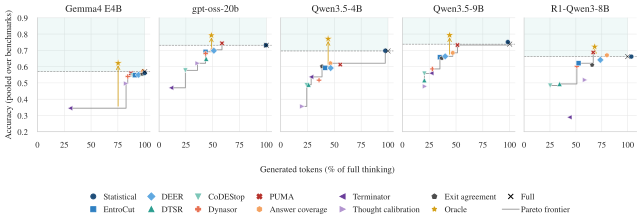

In [38]:
PARETO_REFERENCE_METHOD = ORACLE_METHOD
PARETO_INDIVIDUAL_METHODS = [
    method for method in REPORT_METHOD_ORDER
    if method not in {
        PARETO_REFERENCE_METHOD,
        "baseline_no_thinking",
    }
]
PARETO_RULE_METHODS = [EXIT_AGREEMENT_METHOD]
PARETO_METHODS = (
    PARETO_INDIVIDUAL_METHODS
    + PARETO_RULE_METHODS
    + [PARETO_REFERENCE_METHOD]
)
PARETO_LABELS = {
    "codestop": "CoDEStop",
    "deer": "DEER",
    "entrocut": "EntroCut",
    "dtsr": "DTSR",
    "statistical_early_stop": "Statistical",
    "dynasor": "Dynasor",
    "puma": "PUMA",
    "answer-coverage": "Answer coverage",
    "terminator_hf": "Terminator",
    "thought_calibration": "Thought calibration",
    ORACLE_REPLAY_METHOD: "Full",
    EXIT_AGREEMENT_METHOD: "Exit agreement",
    PARETO_REFERENCE_METHOD: "Oracle",
}


def build_pareto_group_summary(
    report_df,
    hybrid_metric_report,
    dataset_groups=DATASET_GROUPS,
    token_col="total_cost_tokens_est",
):
    """Return benchmark-balanced accuracy/token means for methods and oracle."""
    accuracy_col = (
        "run_accuracy" if "run_accuracy" in report_df.columns else "correct"
    )
    individual = report_df[
        report_df["method"].isin(
            PARETO_INDIVIDUAL_METHODS + [PARETO_REFERENCE_METHOD]
        )
    ].copy()

    # Repeated runs are averaged within a question before benchmark means.
    individual_questions = (
        individual.groupby(
            ["model", "benchmark", "method", "sample_id"],
            as_index=False,
        )
        .agg(accuracy=(accuracy_col, "mean"), avg_tokens=(token_col, "mean"))
    )
    individual_benchmarks = (
        individual_questions.groupby(
            ["model", "benchmark", "method"], as_index=False
        )
        .agg(accuracy=("accuracy", "mean"), avg_tokens=("avg_tokens", "mean"))
    )

    rule_benchmarks = hybrid_metric_report[
        hybrid_metric_report["method"].isin(PARETO_RULE_METHODS)
    ][[
        "model", "benchmark", "method", "accuracy",
        "mean_tok (complete+verify)",
    ]].rename(columns={"mean_tok (complete+verify)": "avg_tokens"})

    benchmark_metrics = pd.concat(
        [individual_benchmarks, rule_benchmarks],
        ignore_index=True,
        sort=False,
    )
    full_tokens = (
        benchmark_metrics[
            benchmark_metrics["method"].eq(ORACLE_REPLAY_METHOD)
        ][["model", "benchmark", "avg_tokens"]]
        .rename(columns={"avg_tokens": "full_avg_tokens"})
    )
    if full_tokens.duplicated(["model", "benchmark"]).any():
        raise ValueError("Full-token reference is not unique per benchmark.")
    benchmark_metrics = benchmark_metrics.merge(
        full_tokens,
        on=["model", "benchmark"],
        how="left",
        validate="many_to_one",
    )
    benchmark_metrics["ratio_pct_full"] = (
        benchmark_metrics["avg_tokens"]
        / benchmark_metrics["full_avg_tokens"].replace(0, np.nan)
        * 100
    )

    benchmark_to_group = {
        benchmark: group
        for group, benchmarks in dataset_groups.items()
        for benchmark in benchmarks
    }
    benchmark_metrics["bench_group"] = (
        benchmark_metrics["benchmark"].map(benchmark_to_group)
    )
    benchmark_metrics = benchmark_metrics[
        benchmark_metrics["bench_group"].notna()
    ].copy()

    grouped = (
        benchmark_metrics.groupby(
            ["model", "bench_group", "method"], as_index=False
        )
        .agg(
            accuracy=("accuracy", "mean"),
            avg_tokens=("avg_tokens", "mean"),
            ratio_pct_full=("ratio_pct_full", "mean"),
            benchmarks=("benchmark", "nunique"),
        )
    )
    overall = (
        benchmark_metrics.groupby(["model", "method"], as_index=False)
        .agg(
            accuracy=("accuracy", "mean"),
            avg_tokens=("avg_tokens", "mean"),
            ratio_pct_full=("ratio_pct_full", "mean"),
            benchmarks=("benchmark", "nunique"),
        )
    )
    overall["bench_group"] = "all benchmarks"
    overall["expected_benchmarks"] = len(benchmark_to_group)
    grouped["expected_benchmarks"] = grouped["bench_group"].map(
        {group: len(benchmarks) for group, benchmarks in dataset_groups.items()}
    )
    grouped = pd.concat([grouped, overall], ignore_index=True, sort=False)
    grouped["complete_group"] = (
        grouped["benchmarks"] == grouped["expected_benchmarks"]
    )

    grouped["is_reference"] = grouped["method"].eq(
        PARETO_REFERENCE_METHOD
    )
    pareto_flags = pd.Series(False, index=grouped.index)
    candidates = grouped[~grouped["is_reference"]]
    for _, scope in candidates.groupby(["model", "bench_group"]):
        for index, point in scope.iterrows():
            dominates = (
                (scope["ratio_pct_full"] <= point["ratio_pct_full"])
                & (scope["accuracy"] >= point["accuracy"])
                & (
                    (scope["ratio_pct_full"] < point["ratio_pct_full"])
                    | (scope["accuracy"] > point["accuracy"])
                )
            )
            pareto_flags.loc[index] = not dominates.any()
    grouped["pareto_optimal"] = pareto_flags
    return grouped.sort_values(
        ["model", "bench_group", "ratio_pct_full"]
    ).reset_index(drop=True)


PAPER_MODEL_LABELS = {
    "gemma4e4": "Gemma4 E4B", "gpt_oss_20b_high": "gpt-oss-20b",
    "qwen35_4b": "Qwen3.5-4B", "qwen35_9b": "Qwen3.5-9B",
    "r1_qwen3_8b": "R1-Qwen3-8B",
}
PAPER_MODEL_COLORS = {
    "gemma4e4": "#cc79a7", "gpt_oss_20b_high": "#0072b2",
    "qwen35_4b": "#e69f00", "qwen35_9b": "#d55e00",
    "r1_qwen3_8b": "#009e73",
}
PAPER_METHOD_STYLES = {
    "statistical_early_stop": ("#1f4e79", "o"), "entrocut": ("#2f80c2", "s"),
    "deer": ("#5fa8e0", "D"), "dtsr": ("#2a9d8f", "^"),
    "codestop": ("#7cc6b8", "v"), "dynasor": ("#e76f51", "P"),
    "puma": ("#b5302a", "X"), "answer-coverage": ("#f4a261", "h"),
    "terminator_hf": ("#6a3d9a", "<"), "thought_calibration": ("#b294cf", ">"),
    "exit_agreement": ("#4d4d4d", "p"), "oracle": ("#d4a017", "*"),
    "replay_eval": ("#000000", "x"),
}
PAPER_RC = {
    "font.family": "serif", "font.serif": ["Times", "Times New Roman", "STIXGeneral"],
    "mathtext.fontset": "stix", "font.size": 8, "axes.titlesize": 8.5,
    "axes.labelsize": 8, "xtick.labelsize": 7, "ytick.labelsize": 7,
    "legend.fontsize": 7, "axes.linewidth": .6, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e6e6",
    "grid.linewidth": .5, "axes.axisbelow": True, "legend.frameon": False,
    "svg.fonttype": "none",
}

def show_paper_figure(fig):
    """Display a crisp vector figure in Jupyter."""
    from io import StringIO
    from IPython.display import SVG, display
    svg = StringIO()
    fig.savefig(svg, format="svg", bbox_inches="tight", pad_inches=.06)
    display(SVG(data=svg.getvalue()))
    plt.close(fig)

def plot_pareto_front(summary):
    """Three-panel paper design, populated from the current notebook summary."""
    from matplotlib.lines import Line2D
    overall = summary[summary["bench_group"].eq("all benchmarks")].dropna(
        subset=["accuracy", "ratio_pct_full"])
    models = list(overall["model"].drop_duplicates())
    if not models:
        raise ValueError("No all-benchmark Pareto data available")
    with plt.rc_context({**PAPER_RC, "font.size": 9, "axes.titlesize": 10,
                         "axes.labelsize": 9, "xtick.labelsize": 8.5,
                         "ytick.labelsize": 8.5, "legend.fontsize": 8.5}):
        fig, axes = plt.subplots(1, len(models), figsize=(max(6.3, 2.15 * len(models)), 3.3),
                                 sharey=True, squeeze=False)
        axes = axes[0]
        for ax, model in zip(axes, models):
            scope = overall[overall["model"].eq(model)]
            full = scope[scope["method"].eq(ORACLE_REPLAY_METHOD)]
            oracle = scope[scope["method"].eq(PARETO_REFERENCE_METHOD)]
            if not full.empty:
                full_acc = float(full["accuracy"].iloc[0])
                full_x = float(full["ratio_pct_full"].iloc[0])
                ax.fill_between([0, full_x], full_acc, .9, color="#2a9d8f", alpha=.07, lw=0)
                ax.axhline(full_acc, color="#888888", lw=.6, ls="--")
            methods = scope[~scope["method"].isin([PARETO_REFERENCE_METHOD, ORACLE_REPLAY_METHOD])]
            methods = methods.sort_values(["ratio_pct_full", "accuracy"], ascending=[True, False])
            frontier = methods[methods["accuracy"].cummax().eq(methods["accuracy"])]
            if len(frontier) > 1:
                ax.plot(frontier["ratio_pct_full"], frontier["accuracy"],
                        color="#999999", lw=.9, drawstyle="steps-post", zorder=2)
            if not oracle.empty and not methods.empty:
                ox = float(oracle["ratio_pct_full"].iloc[0])
                oa = float(oracle["accuracy"].iloc[0])
                within = methods[methods["ratio_pct_full"].le(ox)]
                if not within.empty:
                    best = float(within["accuracy"].max())
                    if oa > best:
                        ax.annotate("", xy=(ox, oa), xytext=(ox, best),
                                    arrowprops=dict(arrowstyle="->", color="#d4a017", lw=.8))
            for row in scope.itertuples():
                color, marker = PAPER_METHOD_STYLES.get(row.method, ("#666666", "o"))
                ax.scatter(row.ratio_pct_full, row.accuracy,
                           s=68 if row.method == PARETO_REFERENCE_METHOD else 24,
                           marker=marker, color=color, edgecolor="white" if marker != "x" else None,
                           linewidth=.4, zorder=4)
            ax.set_title(PAPER_MODEL_LABELS.get(model, str(model)))
            ax.set_xlim(left=0, right=max(105, float(scope["ratio_pct_full"].max()) * 1.05))
            ax.set_ylim(.2, .9)
            ax.set_yticks(np.arange(.2, 1, .1))
            ax.set_xticks([0, 25, 50, 75, 100])
            ax.set_xticklabels(["0", "25", "50", "75", "100"])
        axes[0].set_ylabel("Accuracy (pooled over benchmarks)")
        fig.supxlabel("Generated tokens (% of full thinking)", y=.22, fontsize=9)
        present = [m for m in PAPER_METHOD_STYLES if m in set(overall["method"])]
        handles = [Line2D([], [], ls="", marker=PAPER_METHOD_STYLES[m][1],
                          color=PAPER_METHOD_STYLES[m][0], markersize=5,
                          label=PARETO_LABELS.get(m, m)) for m in present]
        handles.append(Line2D([], [], color="#999999", lw=.9, label="Pareto frontier"))
        fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(.5, .02),
                   ncol=min(7, len(handles)), columnspacing=.7, handletextpad=.2)
        fig.subplots_adjust(wspace=.08, bottom=.40)
        show_paper_figure(fig)


pareto_group_summary = build_pareto_group_summary(
    report_df=report_df,
    hybrid_metric_report=hybrid_metric_report,
)
display(
    pareto_group_summary[[
        "model", "bench_group", "method", "accuracy",
        "avg_tokens", "ratio_pct_full", "benchmarks",
        "expected_benchmarks", "pareto_optimal", "is_reference",
    ]].round({
        "accuracy": 4, "avg_tokens": 1, "ratio_pct_full": 1,
    })
)
plot_pareto_front(pareto_group_summary)


# THINKING LEAKAGE AND ORACLE EARLY-EXIT ANALYSIS

This section estimates an **offline oracle bound**, not a deployable stopping rule. It also estimates normalized-position vulnerability, $P(L=1\mid R_{exit}=r)$, in 5-percentage-point bins. All results are descriptive for the evaluated model/dataset/method mixture and are repeated overall, by dataset, and by model where support permits.

Definitions and assumptions:

- One row is one **candidate exit**: a method is asked to stop at a tested thinking-token position and produce its final answer from only that prefix. Candidate exits turn one reasoning trajectory into comparable checkpoints, letting us ask at each checkpoint whether stopping would already be correct and free of leakage. They are offline observations, not instructions that a deployed model must stop at every tested position. `marker_evaluable` ($E$) means non-empty final-answer text exists and generation did not fail.
- `primary_leakage` ($L_p$) detects an explicit thinking/final boundary (`</think>`, Gemma 4's `<channel|>`, and the GPT-OSS final-channel boundary). `soft_leakage` ($L_s$) detects the whole words *wait* or *actually*. The analysis label is their union, $L=L_p\lor L_s$. Keeping the component labels visible makes the more permissive soft-marker assumption auditable.
- `correct` ($A$) is the stored task-evaluator result. A candidate exit is `safe_exit` iff it is evaluable, correct, and has neither primary nor soft leakage: $S=1\iff E=1\land A=1\land L=0$. Thus an otherwise correct answer containing a soft marker is **not safe**.
- `position` is the number of thinking tokens generated before that candidate exit. For a naturally completed full trajectory, $R_{exit}=\text{position}/\text{full\_num\_token}$. Capped or failed full trajectories are excluded from ratio analysis because their denominator is censored.
- In each 5-point ratio bin, vulnerability is calculated as $\widehat P(L=1\mid R_{exit}\in b)=N_{leaking,b}/N_{evaluable,b}$. This is candidate-exit weighted; confidence intervals resample complete `run_id`s to respect dependence among exits from the same trajectory.
- Repeated exits from one `run_id` are dependent. Bootstrap intervals resample complete runs.
- The **stable observed frontier** is the earliest tested candidate-exit position for which that exit and every later tested exit are safe. Requiring all later exits to remain safe avoids treating one isolated lucky early answer as the readiness point. The frontier is included as an offline reference for whether signals such as DEER and EntroCut fire before safety is consistently observed (premature) or after it was already available (conservative). It is not a deployable stopping rule, does not predict untested positions, and can move when candidate exits are sparse or one later answer is noisy.
- A 32K full-generation limit is right-censoring; it is not treated as the natural reasoning length. Other trajectories without an observed frontier are censored at their last tested position.
- Exact switch locations are not identified between sparse candidate exits. The optional isotonic result is a sensitivity analysis, not ground truth.


In [39]:
import math, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Keep every figure in this analysis readable in notebook and exported views.
plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 15,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 12,
    "legend.title_fontsize": 12,
    "figure.titlesize": 18,
})

THINKING_CAP = 32_000
FINAL_ANSWER_CAP = 2_048
GPT_OSS_BOUNDARY = "<|end|><|start|>assistant<|channel|>final<|message|>"
GEMMA_BOUNDARY = "<channel|>"
PRIMARY_MARKERS = ("</think>",)
SOFT_MARKERS = ("wait", "actually")

def _text(x):
    return x.strip() if isinstance(x, str) else ""

def _number(x):
    try:
        x = float(x)
        return x if np.isfinite(x) else np.nan
    except (TypeError, ValueError):
        return np.nan

def _is_gpt_oss(model):
    return "gpt_oss" in _text(model).lower().replace("-", "_")

def _is_gemma4e4(model):
    name = _text(model).lower().replace("-", "_")
    return "gemma4e4" in name or "gemma_4_e4b" in name

def _answer_suffix(output, model):
    """Final-answer suffix used only when a top-level result lacks final_answer."""
    output = _text(output)
    boundaries = ["</think>"]
    boundaries += [GPT_OSS_BOUNDARY] if _is_gpt_oss(model) else []
    boundaries += [GEMMA_BOUNDARY] if _is_gemma4e4(model) else []
    hits = [(output.rfind(b), b) for b in boundaries if output.rfind(b) >= 0]
    return output[max(hits)[0] + len(max(hits)[1]):].strip() if hits else output

def _marker_spans(answer, model, markers=PRIMARY_MARKERS):
    # Soft markers are words, not substrings (for example, `await` is not `wait`).
    patterns = [rf"\b{re.escape(m)}\b" if m in SOFT_MARKERS else re.escape(m) for m in markers]
    if "</think>" in markers and _is_gpt_oss(model):
        patterns.append(re.escape(GPT_OSS_BOUNDARY))
    if "</think>" in markers and _is_gemma4e4(model):
        patterns.append(re.escape(GEMMA_BOUNDARY))
    return [m.span() for m in re.finditer("|".join(patterns), answer, re.I)] if patterns else []

def _onset(answer, spans):
    """Whitespace-token onset and normalized onset; avoids model-specific tokenizers."""
    tokens = list(re.finditer(r"\S+", answer))
    if not tokens:
        return np.nan, np.nan, 0
    if not spans:
        return np.nan, np.nan, len(tokens)
    first_char = min(start for start, _ in spans)
    first_token = 1 + sum(token.end() <= first_char for token in tokens)
    return first_token, first_token / len(tokens), len(tokens)

def build_leakage_candidates(records):
    rows = []
    for record_index, record in enumerate(records):
        if not isinstance(record, dict):
            continue
        additional = record.get("additional_logs") if isinstance(record.get("additional_logs"), dict) else {}
        benchmark = record.get("benchmark")
        model = record.get("model") or record.get("llm")
        line = record.get("line_number", record.get("line_index", record_index))
        source_file = record.get("source_file", "unknown_file")
        run_name = record.get("run_name", "unknown_run")
        run_id = "::".join(map(str, (benchmark, model, source_file, run_name, line)))
        top_method = record.get("agent") or record.get("method") or "unknown"
        full_tokens = _number(record.get("num_token"))
        full_failure = record.get("failure_reason") or additional.get("failure_reason")
        full_capped = full_failure == "full_generation_reached_token_limit"
        fallback = _answer_suffix(record.get("output"), model)

        for method_index, result in enumerate(get_method_results(record)):
            if not isinstance(result, dict):
                continue
            values = process_method_result(record, result)
            failed = bool(values["generation_failed"])
            answer = _text(result.get("final_answer"))
            if not answer and values["method"] == top_method and not failed:
                answer = fallback
            primary_spans = _marker_spans(answer, model)
            soft_spans = _marker_spans(answer, model, SOFT_MARKERS)
            leak_spans = sorted(primary_spans + soft_spans)
            onset, onset_ratio, answer_word_tokens = _onset(answer, leak_spans)
            primary_onset, primary_onset_ratio, _ = _onset(answer, primary_spans)
            evaluable = bool(answer) and not failed
            primary_leakage = bool(primary_spans) if evaluable else np.nan
            soft_leakage = bool(soft_spans) if evaluable else np.nan
            leakage = bool(leak_spans) if evaluable else np.nan
            correct = bool(values["correct"]) if not failed else False
            position = _number(values["position"])
            finish_reason = result.get("finish_reason") or values.get("logs", {}).get("finish_reason")
            answer_tokens = _number(values.get("answer_tokens"))

            rows.append({
                "run_id": run_id, "record_index": record_index,
                "method_result_index": method_index, "sample_id": f"{benchmark}_{line}",
                "benchmark": benchmark, "model": model, "source_file": source_file,
                "method": values["method"], "position": position,
                "full_num_token": full_tokens, "full_capped": full_capped,
                "full_complete": bool(np.isfinite(full_tokens) and full_tokens > 0 and not full_capped),
                "generation_failed": failed, "stopped_early": bool(values["stopped_early"]),
                "correct": correct, "marker_evaluable": evaluable,
                "primary_leakage": primary_leakage, "soft_leakage": soft_leakage,
                "leakage": leakage, "safe_exit": bool(evaluable and correct and not leakage),
                "primary_marker_count": len(primary_spans), "soft_marker_count": len(soft_spans),
                "method_final_answer": answer, "answer_word_tokens": answer_word_tokens,
                "first_leak_token": onset, "first_leak_ratio": onset_ratio,
                "first_primary_leak_token": primary_onset,
                "first_primary_leak_ratio": primary_onset_ratio,
                "answer_tokens": answer_tokens, "finish_reason": finish_reason,
                "answer_truncated": bool(finish_reason == "length" or answer_tokens >= FINAL_ANSWER_CAP),
            })
    return pd.DataFrame(rows)

df_leakage = build_leakage_candidates(records)
eligible = df_leakage[df_leakage["marker_evaluable"]].copy()
method_leakage_summary = (eligible.groupby(["benchmark", "model", "method"], dropna=False)
    .agg(n=("leakage", "size"), leakage_rate=("leakage", "mean"),
         primary_leakage_rate=("primary_leakage", "mean"),
         soft_leakage_rate=("soft_leakage", "mean"),
         accuracy=("correct", "mean"), safe_exit_rate=("safe_exit", "mean"),
         median_position=("position", "median"))
    .reset_index())

print(f"Candidate rows: {len(df_leakage):,}; text-evaluable: {len(eligible):,}; "
      f"combined leakage events: {int(eligible['leakage'].sum()):,} "
      f"(primary: {int(eligible['primary_leakage'].sum()):,}; "
      f"soft: {int(eligible['soft_leakage'].sum()):,})")
display(method_leakage_summary.round(4))


Candidate rows: 1,329,327; text-evaluable: 1,329,089; combined leakage events: 121,994 (primary: 37,079; soft: 93,583)


,benchmark,model,method,n,leakage_rate,primary_leakage_rate,soft_leakage_rate,accuracy,safe_exit_rate,median_position
0,aime26,gemma4e4,answer-coverage,60,0.1,0.0,0.1,0.3667,0.3500,4023.5
1,aime26,gemma4e4,baseline_1.5K,60,0.2,0.0,0.2,0.2167,0.2167,1536.0
2,aime26,gemma4e4,baseline_12K,60,0.1,0.0,0.1,0.3833,0.3500,4773.0
3,aime26,gemma4e4,baseline_16K,60,0.116667,0.0,0.116667,0.3833,0.3500,4773.0
4,aime26,gemma4e4,baseline_1K,60,0.233333,0.0,0.233333,0.1500,0.1500,1024.0
...,...,...,...,...,...,...,...,...,...,...
902,truthfulqa,r1_qwen3_8b,puma,817,0.0306,0.015912,0.015912,0.3953,0.3843,556.0
903,truthfulqa,r1_qwen3_8b,replay_eval,817,0.008568,0.0,0.008568,0.4357,0.4308,2869.0
904,truthfulqa,r1_qwen3_8b,statistical_early_stop,817,0.008568,0.001224,0.008568,0.4345,0.4308,2787.0
905,truthfulqa,r1_qwen3_8b,terminator_hf,817,0.723378,0.537332,0.423501,0.2570,0.0122,16.0


### Leakage by method

This view pools candidate exits across benchmarks and models, then compares methods using only text-evaluable exits for leakage, accuracy, and safe-exit rates. `candidate_exits` and `non_evaluable_exits` keep the denominator visible; the three leakage rates use `evaluable_exits` as their denominator. These are candidate-exit-weighted descriptive rates, so methods with different benchmark/model coverage should not be interpreted as a benchmark-balanced ranking.


In [40]:
def build_pooled_method_leakage(candidates):
    named = candidates.copy()
    named["method"] = named["method"].fillna("unknown")

    support = (named.groupby("method", dropna=False)
        .agg(candidate_exits=("run_id", "size"),
             evaluable_exits=("marker_evaluable", "sum"),
             generation_failures=("generation_failed", "sum"))
        .astype(int))
    support["non_evaluable_exits"] = (
        support["candidate_exits"] - support["evaluable_exits"]
    )

    evaluable = named[named["marker_evaluable"]].copy()
    outcomes = (evaluable.groupby("method", dropna=False)
        .agg(leaking_exits=("leakage", "sum"),
             primary_leaking_exits=("primary_leakage", "sum"),
             soft_leaking_exits=("soft_leakage", "sum"),
             correct_exits=("correct", "sum"),
             safe_exits=("safe_exit", "sum"),
             median_position=("position", "median")))

    summary = support.join(outcomes, how="left").reset_index()
    count_columns = [
        "leaking_exits", "primary_leaking_exits",
        "soft_leaking_exits", "correct_exits", "safe_exits",
    ]
    summary[count_columns] = summary[count_columns].fillna(0).astype(int)
    denominator = summary["evaluable_exits"].replace(0, np.nan)
    summary["leakage_rate"] = summary["leaking_exits"] / denominator
    summary["primary_leakage_rate"] = (
        summary["primary_leaking_exits"] / denominator
    )
    summary["soft_leakage_rate"] = (
        summary["soft_leaking_exits"] / denominator
    )
    summary["accuracy"] = summary["correct_exits"] / denominator
    summary["safe_exit_rate"] = summary["safe_exits"] / denominator
    return summary.sort_values(
        ["leakage_rate", "method"], ascending=[False, True]
    ).reset_index(drop=True)


pooled_method_leakage = build_pooled_method_leakage(df_leakage)
display_columns = [
    "method", "candidate_exits", "evaluable_exits",
    "non_evaluable_exits", "generation_failures",
    "leaking_exits", "primary_leaking_exits",
    "soft_leaking_exits", "leakage_rate",
    "primary_leakage_rate", "soft_leakage_rate",
    "accuracy", "safe_exit_rate", "median_position",
]
display(pooled_method_leakage[display_columns].round(4))


,method,candidate_exits,evaluable_exits,non_evaluable_exits,generation_failures,leaking_exits,primary_leaking_exits,soft_leaking_exits,leakage_rate,primary_leakage_rate,soft_leakage_rate,accuracy,safe_exit_rate,median_position
0,terminator_hf,57999,57993,6,0,16086,9983,9147,0.2774,0.1721,0.1577,0.5520,0.4455,16.0
1,baseline_no_thinking,58529,58525,4,0,13805,7536,7877,0.2359,0.1288,0.1346,0.5870,0.4806,0.0
2,baseline_500,58529,58473,56,0,11079,3696,8301,0.1895,0.0632,0.1420,0.5374,0.5117,500.0
3,thought_calibration,57999,57994,5,0,7443,1672,6211,0.1283,0.0288,0.1071,0.6128,0.5864,606.0
4,codestop,58529,58509,20,0,7369,2561,5170,0.1259,0.0438,0.0884,0.6344,0.5998,521.0
5,dtsr,58529,58486,43,0,6250,1829,4731,0.1069,0.0313,0.0809,0.6392,0.6185,546.0
6,baseline_1K,58529,58527,2,0,5937,886,5246,0.1014,0.0151,0.0896,0.6370,0.6207,1024.0
7,entrocut,58529,58509,20,0,5595,1939,3918,0.0956,0.0331,0.0670,0.6667,0.6358,613.0
8,deer,58529,58512,17,0,5330,1867,3703,0.0911,0.0319,0.0633,0.6726,0.6422,657.0
9,dynasor,53269,53263,6,0,4662,1081,3775,0.0875,0.0203,0.0709,0.6629,0.6467,640.0


### Candidate exits and the stable-safe frontier

**Purpose.** This analysis asks how far a completed reasoning trajectory had to progress before the tested early-exit candidates became reliably usable. It provides an offline oracle reference for comparing stopping signals such as DEER and EntroCut. It does **not** define a deployable stopping rule, because it uses correctness and all later tested exits—information unavailable at generation time.

**Candidate exits.** Each row of `df_leakage` is one method's attempted final answer at a recorded thinking-token `position`. An evaluable candidate is labeled safe only when its task answer is correct and its final-answer text contains neither a primary boundary marker nor a soft marker (`wait` or `actually`). Failed or empty generations are excluded from the frontier calculation. When several methods produce candidates at the same position, that position is safe only if **all** of those candidates are safe; leakage at the position is true if **any** candidate leaks. This deliberately makes the frontier conservative.

**Stable-frontier calculation.** For each `run_id`, positions are sorted as $p_1 < p_2 < \dots < p_k$. Let $S(p_i)$ be the consolidated safe label at position $p_i$. A position is stable-safe when it and every later tested position are safe: $S_{stable}(p_i)=\bigwedge_{j\ge i}S(p_j)$. `frontier_tokens` is the earliest tested position satisfying this condition. Consequently, an isolated early safe answer followed by an unsafe answer does not count as the frontier. The exact transition between two tested positions remains unknown.

**Censoring and labels.** If no tested position begins an all-safe suffix, `frontier_observed=False`. A full generation stopped by the 32K cap is right-censored at 32K; otherwise it is censored at its last tested candidate position. `sequence_type` summarizes the observed pattern as always safe, never safe, monotonic unsafe-to-safe, safe followed by unsafe, or multiple reversals. `duration_ratio` is calculated only for naturally completed full trajectories.

In the candidate-exit raster, each row is a trajectory, green points are safe candidates, red points leak, and gray points are incorrect without detected leakage. If multiple methods share the same `(run_id, position)`, the base point uses **leak > safe > incorrect without leakage**. Method signals then have the highest visual priority: outlined triangles, diamonds, and squares show DEER, EntroCut, and PUMA on top of the base state, so a red fill inside an outline means that method's candidate leaked. The black tick is the observed stable frontier. The first chart gives the frontier-sorted overview. The second chart is a reproducible random sample drawn only from trajectories containing at least one leakage event, making the timing and recurrence of leakage easier to inspect without claiming that this subset is representative of all runs.


,level,group,runs,observed_frontiers,right_censored,km_median_tokens,safe_by_2K,safe_by_4K,safe_by_8K,safe_by_16K
0,pooled,All,58523,41250,17273,832.0,0.636,0.689,0.747,0.799
1,dataset,aime26,313,210,103,12288.0,0.147,0.254,0.408,0.592
2,dataset,gpqa_diamond,1776,1113,663,6144.0,0.318,0.425,0.516,0.618
3,dataset,gsm8k,7622,6378,1244,335.0,0.822,0.855,0.887,0.906
4,dataset,halueval,22517,17216,5301,173.0,0.863,0.891,0.918,0.925
5,dataset,livecodebench,5260,2317,2943,24576.0,0.250,0.298,0.354,0.430
6,dataset,math500,3485,2997,488,912.0,0.685,0.768,0.840,0.886
7,dataset,mmlu_pro_subset,12016,8900,3116,1536.0,0.536,0.625,0.739,0.843
8,dataset,truthfulqa,5534,2119,3415,16553.0,0.310,0.366,0.439,0.493
9,model,gemma4e4,12286,7844,4442,500.0,0.676,0.734,0.773,0.798


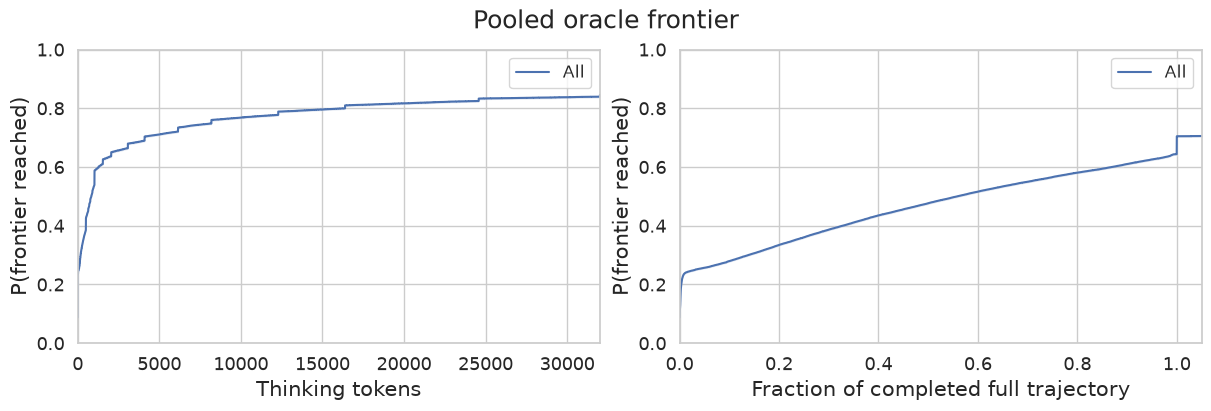

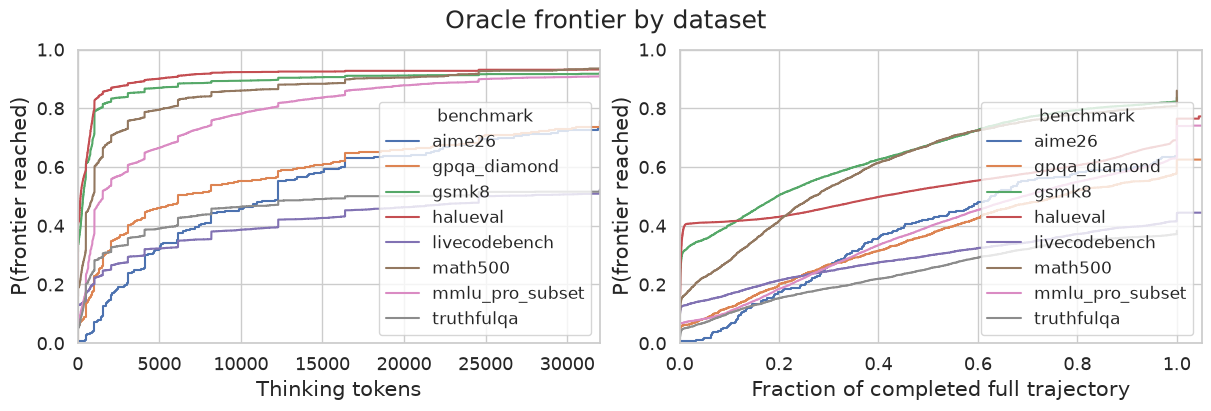

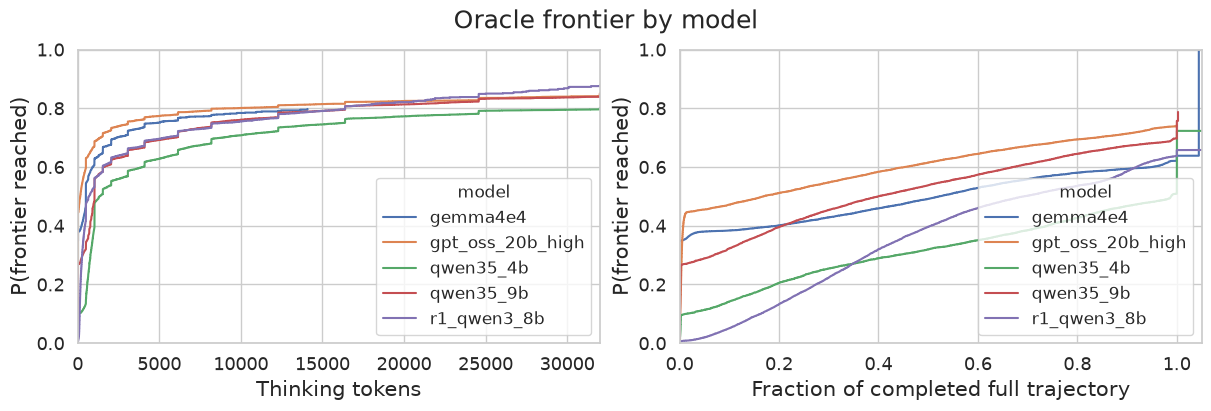

In [41]:
def build_stable_frontiers(candidates):
    """One strict stable-safe frontier (or right-censoring record) per trajectory."""
    valid = candidates[candidates["marker_evaluable"] & candidates["position"].notna()].copy()
    rows, sequences = [], []
    for run_id, group in valid.groupby("run_id", sort=False):
        by_position = (group.groupby("position", as_index=False)
            .agg(safe=("safe_exit", "all"), leak=("leakage", "any"), n=("method", "size"))
            .sort_values("position"))
        safe = by_position["safe"].to_numpy(bool)
        stable = np.logical_and.accumulate(safe[::-1])[::-1]
        event = bool(stable.any())
        frontier = float(by_position.loc[stable, "position"].iloc[0]) if event else np.nan
        meta = group.iloc[0]
        censor = THINKING_CAP if bool(meta["full_capped"]) else float(by_position["position"].max())
        duration = frontier if event else censor
        full = float(meta["full_num_token"]) if np.isfinite(meta["full_num_token"]) else np.nan
        ratio = duration / full if bool(meta["full_complete"]) and full > 0 else np.nan
        transitions = int(np.count_nonzero(safe[1:] != safe[:-1]))
        if safe.all(): sequence = "always safe"
        elif not safe.any(): sequence = "never safe"
        elif transitions == 1 and not safe[0] and safe[-1]: sequence = "monotonic leak/unsafe → safe"
        elif np.any(safe[:-1] & ~safe[1:]): sequence = "safe followed by unsafe"
        else: sequence = "multiple reversals"
        rows.append({
            "run_id": run_id, "benchmark": meta["benchmark"], "model": meta["model"],
            "frontier_observed": event, "frontier_tokens": frontier,
            "duration_tokens": duration, "duration_ratio": ratio,
            "full_complete": bool(meta["full_complete"]), "full_capped": bool(meta["full_capped"]),
            "candidate_positions": len(by_position), "sequence_type": sequence,
        })
        sequences.append(by_position.assign(run_id=run_id))
    return pd.DataFrame(rows), pd.concat(sequences, ignore_index=True) if sequences else pd.DataFrame()

def km_curve(frame, duration="duration_tokens", event="frontier_observed"):
    d = frame[[duration, event]].dropna().sort_values(duration)
    survival, greenwood, out = 1.0, 0.0, []
    for time in np.sort(d[duration].unique()):
        at_risk = int((d[duration] >= time).sum())
        events = int(((d[duration] == time) & d[event].astype(bool)).sum())
        if events:
            survival *= 1 - events / at_risk
            if at_risk > events:
                greenwood += events / (at_risk * (at_risk - events))
            se = survival * np.sqrt(greenwood)
            out.append((time, 1 - survival, max(0, 1 - survival - 1.96 * se),
                        min(1, 1 - survival + 1.96 * se), at_risk, events))
    return pd.DataFrame(out, columns=["time", "cdf", "low", "high", "at_risk", "events"])

def _km_value(curve, time):
    prior = curve[curve["time"] <= time]
    return float(prior["cdf"].iloc[-1]) if len(prior) else 0.0

def frontier_summary_table(frontiers):
    parts = []
    for level, column in (("pooled", None), ("dataset", "benchmark"), ("model", "model")):
        groups = [("All", frontiers)] if column is None else frontiers.groupby(column, dropna=False)
        for name, group in groups:
            curve = km_curve(group)
            median_rows = curve[curve["cdf"] >= .5]
            parts.append({
                "level": level, "group": name, "runs": len(group),
                "observed_frontiers": int(group["frontier_observed"].sum()),
                "right_censored": int((~group["frontier_observed"]).sum()),
                "km_median_tokens": median_rows["time"].iloc[0] if len(median_rows) else np.nan,
                **{f"safe_by_{k//1000}K": _km_value(curve, k) for k in (2_000, 4_000, 8_000, 16_000)},
            })
    return pd.DataFrame(parts)

def plot_frontier_curves(frontiers, group_col=None, title="Pooled oracle frontier"):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
    groups = [("All", frontiers)] if group_col is None else frontiers.groupby(group_col, dropna=False)
    for label, group in groups:
        curve = km_curve(group)
        if len(curve):
            axes[0].step(curve["time"], curve["cdf"], where="post", label=str(label))
            if group_col is None: axes[0].fill_between(curve["time"], curve["low"], curve["high"], alpha=.2, step="post")
        normalized = group[group["duration_ratio"].notna()]
        curve_r = km_curve(normalized, "duration_ratio")
        if len(curve_r):
            axes[1].step(curve_r["time"], curve_r["cdf"], where="post", label=str(label))
            if group_col is None: axes[1].fill_between(curve_r["time"], curve_r["low"], curve_r["high"], alpha=.2, step="post")
    axes[0].set(xlabel="Thinking tokens", ylabel="P(frontier reached)", xlim=(0, THINKING_CAP))
    axes[1].set(xlabel="Fraction of completed full trajectory", ylabel="P(frontier reached)", xlim=(0, 1.05))
    for ax in axes: ax.set_ylim(0, 1); ax.legend(title=group_col or "")
    fig.suptitle(title)
    plt.show()

frontier_df, trajectory_positions = build_stable_frontiers(df_leakage)
frontier_summary = frontier_summary_table(frontier_df)
display(frontier_summary.round(3))
plot_frontier_curves(frontier_df)
plot_frontier_curves(frontier_df, "benchmark", "Oracle frontier by dataset")
plot_frontier_curves(frontier_df, "model", "Oracle frontier by model")


### Reasoning leakage rate by normalized exit position

The table and five-model figure use `ratio_vulnerability`, computed above from `df_leakage` with five-point exit-position bins. The filled bands separate primary leakage from additional soft-marker leakage.


,signal,level,group,ratio_bin,candidate_exits,leaking_exits,runs,leakage_probability,ci_low,ci_high,bin_left,bin_right,bin_center
0,including_soft_leakage,pooled,All,00-05%,146965,42628,58520,0.290055,0.2864,0.2939,0.00,0.05,0.025
1,including_soft_leakage,pooled,All,05-10%,52723,17121,24767,0.324735,0.3188,0.3305,0.05,0.10,0.075
2,including_soft_leakage,pooled,All,10-15%,41925,10739,23158,0.256148,0.2503,0.2614,0.10,0.15,0.125
3,including_soft_leakage,pooled,All,15-20%,36690,7787,22847,0.212238,0.2065,0.2176,0.15,0.20,0.175
4,including_soft_leakage,pooled,All,20-25%,31047,5616,20564,0.180887,0.1758,0.1860,0.20,0.25,0.225
...,...,...,...,...,...,...,...,...,...,...,...,...,...
555,primary_leakage_only,model,r1_qwen3_8b,75-80%,2725,94,2092,0.034495,0.0245,0.0444,0.75,0.80,0.775
556,primary_leakage_only,model,r1_qwen3_8b,80-85%,6699,65,2156,0.009703,0.0055,0.0155,0.80,0.85,0.825
557,primary_leakage_only,model,r1_qwen3_8b,85-90%,29809,128,3404,0.004294,0.0021,0.0072,0.85,0.90,0.875
558,primary_leakage_only,model,r1_qwen3_8b,90-95%,39258,37,3874,0.000942,0.0003,0.0019,0.90,0.95,0.925


,ratio_bin,candidate_exits,runs,leakage_probability,ci_low,ci_high
6,30-35%,24803,17285,0.135306,0.1306,0.1403
10,50-55%,20588,15676,0.102681,0.0977,0.1081
14,70-75%,16323,12408,0.11928,0.1132,0.1256


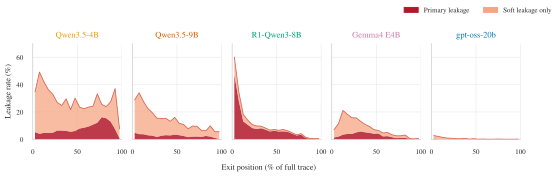

In [42]:
RATIO_BIN_WIDTH = 0.05
RATIO_LEFT = np.round(np.arange(0, 1, RATIO_BIN_WIDTH), 2)
RATIO_LABELS = [f"{int(100 * left):02d}-{int(100 * (left + RATIO_BIN_WIDTH)):02d}%" for left in RATIO_LEFT]
RATIO_EDGES = np.append(RATIO_LEFT, np.nextafter(1.0, 2.0))

def _ratio_probability_table(group, leakage_col="leakage", bootstraps=500, seed=17):
    point = (group.groupby("ratio_bin", observed=False)
             .agg(candidate_exits=(leakage_col, "size"),
                  leaking_exits=(leakage_col, "sum"),
                  runs=("run_id", "nunique"))
             .reindex(RATIO_LABELS))
    point["leakage_probability"] = point["leaking_exits"] / point["candidate_exits"]
    point["ci_low"] = point["ci_high"] = np.nan

    run_ids = pd.Index(group["run_id"].unique())
    if len(run_ids):
        sums = (group.assign(_leakage=group[leakage_col].astype(float))
                .pivot_table(index="run_id", columns="ratio_bin", values="_leakage",
                             aggfunc="sum", fill_value=0, observed=False)
                .reindex(index=run_ids, columns=RATIO_LABELS, fill_value=0).to_numpy(float))
        counts = (group.assign(one=1)
                  .pivot_table(index="run_id", columns="ratio_bin", values="one",
                               aggfunc="sum", fill_value=0, observed=False)
                  .reindex(index=run_ids, columns=RATIO_LABELS, fill_value=0).to_numpy(float))
        rng = np.random.default_rng(seed)
        sampled = rng.integers(0, len(run_ids), size=(bootstraps, len(run_ids)))
        boot_sums, boot_counts = sums[sampled].sum(axis=1), counts[sampled].sum(axis=1)
        for bin_index in range(len(RATIO_LABELS)):
            supported = boot_counts[:, bin_index] > 0
            if supported.any():
                draws = boot_sums[supported, bin_index] / boot_counts[supported, bin_index]
                point.iloc[bin_index, point.columns.get_loc("ci_low")] = np.quantile(draws, .025)
                point.iloc[bin_index, point.columns.get_loc("ci_high")] = np.quantile(draws, .975)

    point = point.reset_index(names="ratio_bin")
    point["bin_left"] = RATIO_LEFT
    point["bin_right"] = np.minimum(RATIO_LEFT + RATIO_BIN_WIDTH, 1.0)
    point["bin_center"] = (point["bin_left"] + point["bin_right"]) / 2
    return point

def build_ratio_vulnerability(candidates):
    valid = candidates[
        candidates["marker_evaluable"] & candidates["full_complete"]
        & candidates["position"].notna() & (candidates["full_num_token"] > 0)
    ].copy()
    valid["exit_ratio"] = valid["position"] / valid["full_num_token"]
    valid = valid[valid["exit_ratio"].between(0, 1, inclusive="both")].copy()
    valid["ratio_bin"] = pd.cut(valid["exit_ratio"], bins=RATIO_EDGES,
                                      labels=RATIO_LABELS, right=False, include_lowest=True)
    parts = []
    signals = (("including_soft_leakage", "leakage"),
               ("primary_leakage_only", "primary_leakage"))
    for signal_index, (signal, leakage_col) in enumerate(signals):
        for level, group_col in (("pooled", None), ("dataset", "benchmark"), ("model", "model")):
            groups = [("All", valid)] if group_col is None else valid.groupby(group_col, dropna=False)
            for offset, (name, group) in enumerate(groups):
                table = _ratio_probability_table(
                    group, leakage_col=leakage_col, seed=17 + 1000 * signal_index + offset
                )
                table.insert(0, "group", name)
                table.insert(0, "level", level)
                table.insert(0, "signal", signal)
                parts.append(table)
    return valid, pd.concat(parts, ignore_index=True)

ratio_candidates, ratio_vulnerability = build_ratio_vulnerability(df_leakage)
ratio_vulnerability_observed = ratio_vulnerability[ratio_vulnerability["candidate_exits"] > 0]
display(ratio_vulnerability_observed.round(4))
ratio_vulnerability_landmarks = ratio_vulnerability_observed[
    (ratio_vulnerability_observed["level"] == "pooled")
    & (ratio_vulnerability_observed["signal"] == "including_soft_leakage")
    & ratio_vulnerability_observed["bin_left"].isin([.30, .50, .70])
][["ratio_bin", "candidate_exits", "runs", "leakage_probability", "ci_low", "ci_high"]]
display(ratio_vulnerability_landmarks.round(4))
def plot_reasoning_leakage_rate(table):
    """Five-model paper layout from this notebook's measured leakage bins."""
    from matplotlib.patches import Patch
    model_rows = table[(table["level"] == "model") & (table["candidate_exits"] > 0)]
    combined = model_rows[model_rows["signal"].eq("including_soft_leakage")]
    primary = model_rows[model_rows["signal"].eq("primary_leakage_only")]
    models = (combined.groupby("group")["leakage_probability"].mean()
              .sort_values(ascending=False).index.tolist())
    if not models:
        raise ValueError("No model-level leakage bins available")
    with plt.rc_context(PAPER_RC):
        fig, axes = plt.subplots(1, len(models),
                                 figsize=(max(6.3, 1.75 * len(models)), 2.05),
                                 sharey=True, squeeze=False)
        axes = axes[0]
        for ax, model in zip(axes, models):
            total = combined[combined["group"].eq(model)]
            base = primary[primary["group"].eq(model)][["ratio_bin", "leakage_probability"]]
            curve = total.merge(base, on="ratio_bin", suffixes=("_total", "_primary"))
            curve = curve.sort_values("bin_center")
            x = curve["bin_center"].to_numpy(float) * 100
            upper = curve["leakage_probability_total"].to_numpy(float) * 100
            lower = curve["leakage_probability_primary"].to_numpy(float) * 100
            valid = np.isfinite(upper) & np.isfinite(lower)
            upper, lower = np.maximum(upper[valid], lower[valid]), lower[valid]
            x = x[valid]
            ax.fill_between(x, 0, lower, color="#b2182b", alpha=.85, lw=0)
            ax.fill_between(x, lower, upper, color="#f4a582", alpha=.75, lw=0)
            ax.plot(x, upper, color="#d6604d", lw=.8)
            ax.set_title(PAPER_MODEL_LABELS.get(model, str(model)),
                         color=PAPER_MODEL_COLORS.get(model, "#333333"))
            ax.set_xlim(0, 100)
            ax.set_xticks([0, 50, 100], ["0", "50", "100"])
        max_rate = float(combined["leakage_probability"].max()) * 100
        axes[0].set_ylim(0, min(100, max(10, np.ceil(max_rate / 10) * 10)))
        axes[0].set_ylabel("Leakage rate (%)")
        fig.supxlabel("Exit position (% of full trace)", y=.01, fontsize=8)
        fig.legend(handles=[Patch(color="#b2182b", label="Primary leakage"),
                            Patch(color="#f4a582", label="Soft leakage only")],
                   loc="upper right", ncol=2, bbox_to_anchor=(.96, 1.17))
        fig.subplots_adjust(wspace=.12, bottom=.23)
        show_paper_figure(fig)

plot_reasoning_leakage_rate(ratio_vulnerability)


,level,group,sequence_type,runs,share
0,pooled,All,always safe,13866,0.237
1,pooled,All,monotonic leak/unsafe → safe,9899,0.169
2,pooled,All,never safe,11543,0.197
3,pooled,All,safe followed by unsafe,23215,0.397
4,dataset,aime26,always safe,2,0.006
5,dataset,aime26,monotonic leak/unsafe → safe,115,0.367
6,dataset,aime26,never safe,80,0.256
7,dataset,aime26,safe followed by unsafe,116,0.371
8,dataset,gpqa_diamond,always safe,100,0.056
9,dataset,gpqa_diamond,monotonic leak/unsafe → safe,290,0.163


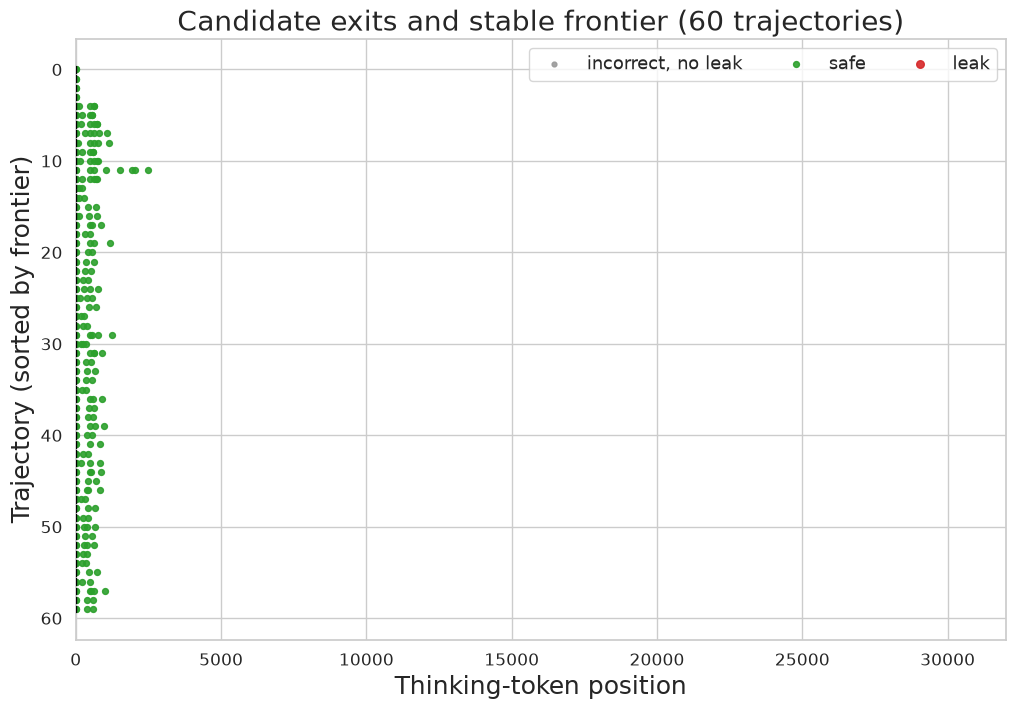

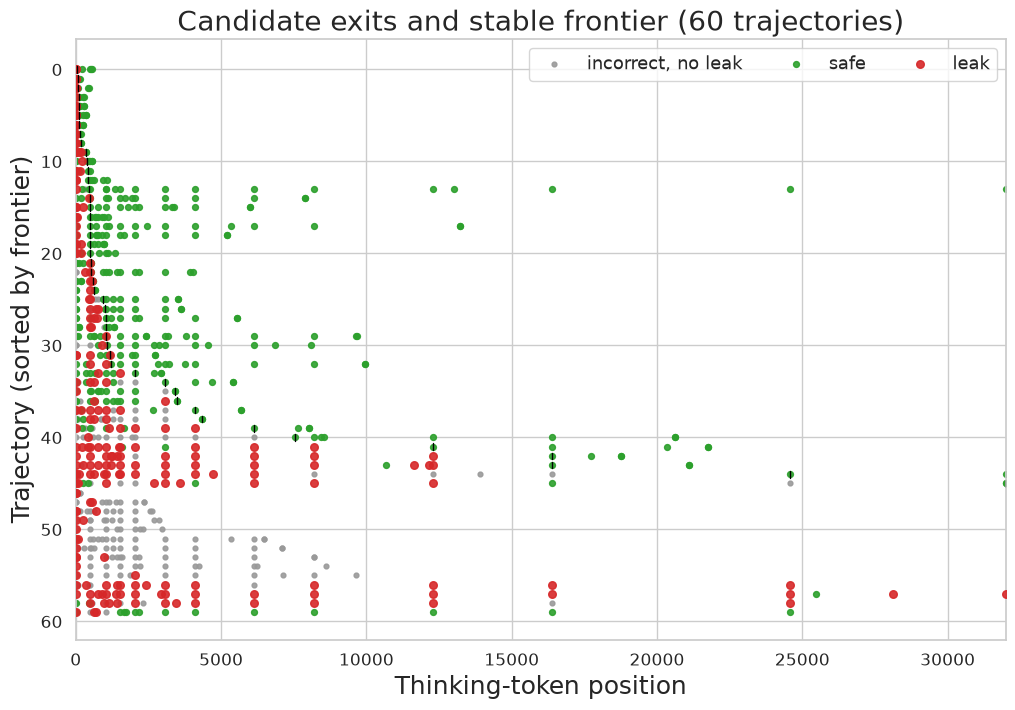

In [43]:
def sequence_summary_table(frontiers):
    tables = []
    for level, column in (("pooled", None), ("dataset", "benchmark"), ("model", "model")):
        grouped = (frontiers.assign(group="All").groupby(["group", "sequence_type"]) if column is None
                   else frontiers.groupby([column, "sequence_type"], dropna=False))
        table = grouped.size().rename("runs").reset_index().rename(columns={column or "group": "group"})
        table["share"] = table["runs"] / table.groupby("group")["runs"].transform("sum")
        table["level"] = level
        tables.append(table)
    return pd.concat(tables, ignore_index=True)[["level", "group", "sequence_type", "runs", "share"]]

def plot_trajectory_raster(
    candidates, frontiers, n=60, benchmark=None, model=None,
    leakage_only=False, random_sample=False, seed=7,
):
    data = candidates[candidates["marker_evaluable"] & candidates["position"].notna()].copy()
    meta = frontiers.copy()
    if benchmark is not None: meta = meta[meta["benchmark"] == benchmark]
    if model is not None: meta = meta[meta["model"] == model]
    if leakage_only:
        leaking_runs = data.loc[data["leakage"].fillna(False), "run_id"].unique()
        meta = meta[meta["run_id"].isin(leaking_runs)]
    if random_sample and len(meta) > n:
        chosen = (meta.sample(n=n, random_state=seed)
                  .sort_values(["frontier_observed", "duration_tokens"], ascending=[False, True]))
    else:
        chosen = meta.sort_values(
            ["frontier_observed", "duration_tokens"], ascending=[False, True]
        ).head(n)
    data = data[data["run_id"].isin(chosen["run_id"])]
    order = {run: i for i, run in enumerate(chosen["run_id"])}
    # Several methods can emit candidates at the same trajectory position.
    # Collapse that coordinate once, with leakage taking visual precedence.
    points = (data.groupby(["run_id", "position"], as_index=False)
              .agg(leakage=("leakage", lambda values: values.fillna(False).any()),
                   safe_exit=("safe_exit", "all")))
    points["point_state"] = np.select(
        [points["leakage"], points["safe_exit"]],
        ["leak", "safe"], default="incorrect, no leak",
    )
    fig, ax = plt.subplots(figsize=(12, max(5, .13 * len(chosen))))
    # Base-state priority: leak > safe > incorrect/no-leak.
    styles = [("incorrect, no leak", "#999999", 12, 1),
              ("safe", "#2ca02c", 18, 2),
              ("leak", "#d62728", 30, 3)]
    for state, color, size, zorder in styles:
        part = points[points["point_state"] == state]
        ax.scatter(part["position"], part["run_id"].map(order), s=size,
                   color=color, label=state, alpha=.9, zorder=zorder)
    for row in chosen[chosen["frontier_observed"]].itertuples():
        ax.plot([row.frontier_tokens] * 2,
                [order[row.run_id] - .35, order[row.run_id] + .35],
                color="black", lw=1, zorder=4)
    # subset = "leakage-only sample" if leakage_only else "overview"
    ax.set(xlabel="Thinking-token position", ylabel="Trajectory (sorted by frontier)",
           title=f"Candidate exits and stable frontier ({len(chosen)} trajectories)",
           xlim=(0, THINKING_CAP))
    ax.set_title(ax.get_title(), fontsize=20)
    ax.set_xlabel(ax.get_xlabel(), fontsize=18)
    ax.set_ylabel(ax.get_ylabel(), fontsize=18)
    ax.tick_params(axis="both", labelsize=12)
    ax.invert_yaxis(); ax.legend(ncol=3, fontsize=13); plt.show()

sequence_summary = sequence_summary_table(frontier_df)
display(sequence_summary.round(3))
plot_trajectory_raster(df_leakage, frontier_df)
plot_trajectory_raster(
    df_leakage, frontier_df, n=60, leakage_only=True, random_sample=True, seed=7,
)
